READING THE FILES AND DATA

In [308]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

dataset_path = '/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020'

circuits = pd.read_csv(dataset_path + '/circuits.csv')
constructors = pd.read_csv(dataset_path + '/constructors.csv')
constructor_results = pd.read_csv(dataset_path + '/constructor_results.csv')
constructor_standings = pd.read_csv(dataset_path + '/constructor_standings.csv')
drivers = pd.read_csv(dataset_path + '/drivers.csv')
driver_standings = pd.read_csv(dataset_path + '/driver_standings.csv')
races = pd.read_csv(dataset_path + '/races.csv')
results = pd.read_csv(dataset_path + '/results.csv')
qualifying = pd.read_csv(dataset_path + '/qualifying.csv')
lap_times = pd.read_csv(dataset_path + '/lap_times.csv')
pit_stops = pd.read_csv(dataset_path + '/pit_stops.csv')
sprint_results = pd.read_csv(dataset_path + '/sprint_results.csv')
seasons = pd.read_csv(dataset_path + '/seasons.csv')
status = pd.read_csv(dataset_path + '/status.csv')

CREATING DICTIONARY FOR ALL TABLES

In [309]:
tables = {
    'circuits': circuits,
    'constructors': constructors,
    'constructor_results': constructor_results,
    'constructor_standings': constructor_standings,
    'drivers': drivers,
    'driver_standings': driver_standings,
    'races': races,
    'results': results,
    'qualifying': qualifying,
    'lap_times': lap_times,
    'pit_stops': pit_stops,
    'sprint_results': sprint_results,
    'seasons': seasons,
    'status': status
}

CHECK THAT EVERY TABLE LOADED

In [310]:
for name, df in tables.items():
    print(name, df.shape)

circuits (77, 9)
constructors (212, 5)
constructor_results (12625, 5)
constructor_standings (13391, 7)
drivers (861, 9)
driver_standings (34863, 7)
races (1125, 18)
results (26759, 18)
qualifying (10494, 9)
lap_times (589081, 6)
pit_stops (11371, 7)
sprint_results (360, 16)
seasons (75, 2)
status (139, 2)


First Audit Summary

In [311]:
audit_summary = []

for name, df in tables.items():
    audit_summary.append({
        'table': name,
        'rows': df.shape[0],
        'columns': df.shape[1],
        'duplicate_rows': df.duplicated().sum(),
        'missing_values_standard_NaN': df.isna().sum().sum(),
        'sentinel_missing_\\N': (df == '\\N').sum().sum()
    })

audit_summary = pd.DataFrame(audit_summary)
audit_summary

,table,rows,columns,duplicate_rows,missing_values_standard_NaN,sentinel_missing_\N
0,circuits,77,9,0,0,0
1,constructors,212,5,0,0,0
2,constructor_results,12625,5,0,0,12608
3,constructor_standings,13391,7,0,0,0
4,drivers,861,9,0,0,1559
5,driver_standings,34863,7,0,0,0
6,races,1125,18,0,0,11349
7,results,26759,18,0,0,122887
8,qualifying,10494,9,0,68,11600
9,lap_times,589081,6,0,0,0


### Initial Data Audit Summary

The initial audit was performed on all 14 relational Formula 1 CSV tables. The purpose of this step was to understand the size of each table, check for fully duplicated rows, identify standard missing values already recognized by Pandas as `NaN`, and count sentinel missing values represented as `\N`.

The audit shows that all required dataset tables were successfully loaded, including `results`, `races`, `drivers`, `constructors`, `qualifying`, `status`, `lap_times`, `pit_stops`, and the standings tables. The largest table is `lap_times`, with 589,081 rows, while smaller reference tables such as `circuits`, `seasons`, and `status` contain far fewer rows.

No fully duplicated rows were found in the loaded tables, which means there are no exact row repetitions at this stage. However, several tables contain a large number of sentinel missing values written as `\N`. These appear especially in important tables such as `results`, `constructor_results`, `races`, `drivers`, `qualifying`, and `sprint_results`.

This is important because `\N` is not automatically treated as a proper missing value by Pandas. Therefore, before performing type conversion, joins, cleaning, feature engineering, or modeling, these sentinel values must be converted into real `NaN` values.

This audit represents the "before cleaning" snapshot of the dataset and will be compared with the cleaned version later to show the effect of the preprocessing step.

# Replace sentinel missing values '\N' with proper NaN values in all tables

In [312]:

for name, df in tables.items():
    tables[name] = df.replace('\\N', np.nan)

In [313]:
circuits = tables['circuits']
constructors = tables['constructors']
constructor_results = tables['constructor_results']
constructor_standings = tables['constructor_standings']
drivers = tables['drivers']
driver_standings = tables['driver_standings']
races = tables['races']
results = tables['results']
qualifying = tables['qualifying']
lap_times = tables['lap_times']
pit_stops = tables['pit_stops']
sprint_results = tables['sprint_results']
seasons = tables['seasons']
status = tables['status']

# CHECKING THAT CLEANING WORKED

In [314]:
audit_summary_after_sentinel_cleaning = []

for name, df in tables.items():
    audit_summary_after_sentinel_cleaning.append({
        'table': name,
        'rows': df.shape[0],
        'columns': df.shape[1],
        'duplicate_rows': df.duplicated().sum(),
        'missing_values_standard_NaN': df.isna().sum().sum(),
        'sentinel_missing_\\N': (df == '\\N').sum().sum()
    })

audit_summary_after_sentinel_cleaning = pd.DataFrame(audit_summary_after_sentinel_cleaning)
audit_summary_after_sentinel_cleaning

,table,rows,columns,duplicate_rows,missing_values_standard_NaN,sentinel_missing_\N
0,circuits,77,9,0,0,0
1,constructors,212,5,0,0,0
2,constructor_results,12625,5,0,12608,0
3,constructor_standings,13391,7,0,0,0
4,drivers,861,9,0,1559,0
5,driver_standings,34863,7,0,0,0
6,races,1125,18,0,11349,0
7,results,26759,18,0,122887,0
8,qualifying,10494,9,0,11668,0
9,lap_times,589081,6,0,0,0


### Sentinel Missing Value Cleaning Summary

After the initial audit, all sentinel missing values represented as `\N` were replaced with proper `NaN` values across all 14 Formula 1 tables.

The second audit confirms that the number of remaining `\N` values is now 0 in every table. This means that missing values are now represented consistently using Pandas' standard missing value format.

Several tables now show a large number of standard missing values, especially `results`, `qualifying`, `races`, `constructor_results`, `drivers`, and `sprint_results`. This is expected because the dataset originally stored many missing values as `\N`.

This cleaning step is necessary before converting columns to numeric or datetime types, performing joins, checking missingness, and building features. Without this step, Pandas would treat some missing values as strings, which could cause errors or incorrect data types later in the pipeline.

### CHECKING CURRENT DATA TYPES

In [315]:
results.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26759 entries, 0 to 26758
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   resultId         26759 non-null  int64  
 1   raceId           26759 non-null  int64  
 2   driverId         26759 non-null  int64  
 3   constructorId    26759 non-null  int64  
 4   number           26753 non-null  object 
 5   grid             26759 non-null  int64  
 6   position         15806 non-null  object 
 7   positionText     26759 non-null  object 
 8   positionOrder    26759 non-null  int64  
 9   points           26759 non-null  float64
 10  laps             26759 non-null  int64  
 11  time             7680 non-null   object 
 12  milliseconds     7680 non-null   object 
 13  fastestLap       8252 non-null   object 
 14  rank             8510 non-null   object 
 15  fastestLapTime   8252 non-null   object 
 16  fastestLapSpeed  8252 non-null   object 
 17  statusId    

In [316]:
races.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1125 entries, 0 to 1124
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   raceId       1125 non-null   int64 
 1   year         1125 non-null   int64 
 2   round        1125 non-null   int64 
 3   circuitId    1125 non-null   int64 
 4   name         1125 non-null   object
 5   date         1125 non-null   object
 6   time         394 non-null    object
 7   url          1125 non-null   object
 8   fp1_date     90 non-null     object
 9   fp1_time     68 non-null     object
 10  fp2_date     90 non-null     object
 11  fp2_time     68 non-null     object
 12  fp3_date     72 non-null     object
 13  fp3_time     53 non-null     object
 14  quali_date   90 non-null     object
 15  quali_time   68 non-null     object
 16  sprint_date  18 non-null     object
 17  sprint_time  15 non-null     object
dtypes: int64(4), object(14)
memory usage: 158.3+ KB


In [317]:
qualifying.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10494 entries, 0 to 10493
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   qualifyId      10494 non-null  int64 
 1   raceId         10494 non-null  int64 
 2   driverId       10494 non-null  int64 
 3   constructorId  10494 non-null  int64 
 4   number         10494 non-null  int64 
 5   position       10494 non-null  int64 
 6   q1             10338 non-null  object
 7   q2             5847 non-null   object
 8   q3             3629 non-null   object
dtypes: int64(6), object(3)
memory usage: 738.0+ KB


# Convert race date to datetime


In [318]:
races['date'] = pd.to_datetime(races['date'], errors='coerce')

In [319]:
races[['raceId', 'year', 'round', 'date']].head()

,raceId,year,round,date
0,1,2009,1,2009-03-29
1,2,2009,2,2009-04-05
2,3,2009,3,2009-04-19
3,4,2009,4,2009-04-26
4,5,2009,5,2009-05-10


# Convert important results columns to numeric

In [320]:
results_numeric_cols = [
    'resultId',
    'raceId',
    'driverId',
    'constructorId',
    'number',
    'grid',
    'position',
    'positionOrder',
    'points',
    'laps',
    'milliseconds',
    'fastestLap',
    'rank',
    'fastestLapSpeed',
    'statusId'
]

for col in results_numeric_cols:
    if col in results.columns:
        results[col] = pd.to_numeric(results[col], errors='coerce')

# Convert important qualifying columns

In [321]:
qualifying_numeric_cols = [
    'qualifyId',
    'raceId',
    'driverId',
    'constructorId',
    'number',
    'position'
]

for col in qualifying_numeric_cols:
    if col in qualifying.columns:
        qualifying[col] = pd.to_numeric(qualifying[col], errors='coerce')

# CONFIRM CONVERSION WORKED

In [322]:
results.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26759 entries, 0 to 26758
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   resultId         26759 non-null  int64  
 1   raceId           26759 non-null  int64  
 2   driverId         26759 non-null  int64  
 3   constructorId    26759 non-null  int64  
 4   number           26753 non-null  float64
 5   grid             26759 non-null  int64  
 6   position         15806 non-null  float64
 7   positionText     26759 non-null  object 
 8   positionOrder    26759 non-null  int64  
 9   points           26759 non-null  float64
 10  laps             26759 non-null  int64  
 11  time             7680 non-null   object 
 12  milliseconds     7680 non-null   float64
 13  fastestLap       8252 non-null   float64
 14  rank             8510 non-null   float64
 15  fastestLapTime   8252 non-null   object 
 16  fastestLapSpeed  8252 non-null   float64
 17  statusId    

In [323]:
races.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1125 entries, 0 to 1124
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   raceId       1125 non-null   int64         
 1   year         1125 non-null   int64         
 2   round        1125 non-null   int64         
 3   circuitId    1125 non-null   int64         
 4   name         1125 non-null   object        
 5   date         1125 non-null   datetime64[ns]
 6   time         394 non-null    object        
 7   url          1125 non-null   object        
 8   fp1_date     90 non-null     object        
 9   fp1_time     68 non-null     object        
 10  fp2_date     90 non-null     object        
 11  fp2_time     68 non-null     object        
 12  fp3_date     72 non-null     object        
 13  fp3_time     53 non-null     object        
 14  quali_date   90 non-null     object        
 15  quali_time   68 non-null     object        
 16  sprint

In [324]:
qualifying.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10494 entries, 0 to 10493
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   qualifyId      10494 non-null  int64 
 1   raceId         10494 non-null  int64 
 2   driverId       10494 non-null  int64 
 3   constructorId  10494 non-null  int64 
 4   number         10494 non-null  int64 
 5   position       10494 non-null  int64 
 6   q1             10338 non-null  object
 7   q2             5847 non-null   object
 8   q3             3629 non-null   object
dtypes: int64(6), object(3)
memory usage: 738.0+ KB


### Data Type Conversion Summary

After replacing sentinel missing values with proper `NaN` values, key columns were converted to appropriate data types.

In the `races` table, the `date` column was converted to a datetime type, which allows chronological sorting and time-based splitting. In the `results` table, ID columns, grid position, finishing order, points, laps, fastest-lap fields, and status IDs were converted to numeric types. In the `qualifying` table, ID columns and qualifying position were also converted to numeric types.

The qualifying lap-time columns `q1`, `q2`, and `q3` remain as object/string columns because they represent lap times and require separate parsing later.

This step is important because correct data types are required before performing joins, checking primary and foreign keys, creating the podium target, and engineering leakage-safe features.

In [325]:
def check_primary_key(df, key, table_name):
    print(f"\nChecking primary key: {table_name}.{key}")
    print("Rows:", len(df))
    print("Missing key values:", df[key].isna().sum())
    print("Duplicate key values:", df[key].duplicated().sum())
    print("Unique key values:", df[key].nunique())

check_primary_key(circuits, 'circuitId', 'circuits')
check_primary_key(constructors, 'constructorId', 'constructors')
check_primary_key(drivers, 'driverId', 'drivers')
check_primary_key(races, 'raceId', 'races')
check_primary_key(results, 'resultId', 'results')
check_primary_key(qualifying, 'qualifyId', 'qualifying')
check_primary_key(status, 'statusId', 'status')


Checking primary key: circuits.circuitId
Rows: 77
Missing key values: 0
Duplicate key values: 0
Unique key values: 77

Checking primary key: constructors.constructorId
Rows: 212
Missing key values: 0
Duplicate key values: 0
Unique key values: 212

Checking primary key: drivers.driverId
Rows: 861
Missing key values: 0
Duplicate key values: 0
Unique key values: 861

Checking primary key: races.raceId
Rows: 1125
Missing key values: 0
Duplicate key values: 0
Unique key values: 1125

Checking primary key: results.resultId
Rows: 26759
Missing key values: 0
Duplicate key values: 0
Unique key values: 26759

Checking primary key: qualifying.qualifyId
Rows: 10494
Missing key values: 0
Duplicate key values: 0
Unique key values: 10494

Checking primary key: status.statusId
Rows: 139
Missing key values: 0
Duplicate key values: 0
Unique key values: 139


### Primary Key Validation Summary

The primary-key audit was performed on the main reference and event tables: `circuits`, `constructors`, `drivers`, `races`, `results`, `qualifying`, and `status`.

For all checked tables, the primary-key columns have:
- 0 missing values
- 0 duplicate values
- the number of unique key values equal to the number of rows

This confirms that the main primary keys are valid and can safely be used for joins. For example, each `raceId` uniquely identifies one race, each `driverId` uniquely identifies one driver, and each `resultId` uniquely identifies one result row.

This validation is important because the milestone requires primary keys to be unique and non-null before building the relational modeling table.

In [326]:
def check_foreign_key(child_df, child_col, parent_df, parent_col, relationship_name):
    child_values = set(child_df[child_col].dropna().unique())
    parent_values = set(parent_df[parent_col].dropna().unique())

    missing_values = child_values - parent_values

    print(f"\nChecking foreign key: {relationship_name}")
    print("Unique child values:", len(child_values))
    print("Unique parent values:", len(parent_values))
    print("Missing references:", len(missing_values))

    if len(missing_values) > 0:
        print("Example missing values:", list(missing_values)[:10])


check_foreign_key(results, 'raceId', races, 'raceId', 'results.raceId -> races.raceId')
check_foreign_key(results, 'driverId', drivers, 'driverId', 'results.driverId -> drivers.driverId')
check_foreign_key(results, 'constructorId', constructors, 'constructorId', 'results.constructorId -> constructors.constructorId')
check_foreign_key(results, 'statusId', status, 'statusId', 'results.statusId -> status.statusId')


Checking foreign key: results.raceId -> races.raceId
Unique child values: 1125
Unique parent values: 1125
Missing references: 0

Checking foreign key: results.driverId -> drivers.driverId
Unique child values: 861
Unique parent values: 861
Missing references: 0

Checking foreign key: results.constructorId -> constructors.constructorId
Unique child values: 211
Unique parent values: 212
Missing references: 0

Checking foreign key: results.statusId -> status.statusId
Unique child values: 137
Unique parent values: 139
Missing references: 0


### Foreign Key Validation Summary

The foreign-key audit was performed on the main `results` table because it is the base table for the modeling dataset.

The checks confirm that:
- Every `raceId` in `results` exists in `races`
- Every `driverId` in `results` exists in `drivers`
- Every `constructorId` in `results` exists in `constructors`
- Every `statusId` in `results` exists in `status`

All checked relationships have 0 missing references. This means the main `results` table can safely be joined with the race, driver, constructor, and status reference tables without losing records because of invalid IDs.

This step is important because the Formula 1 dataset is relational, and the milestone requires verifying that foreign keys reconcile with their referenced primary keys before building the final modeling table.

In [327]:
# Check whether each driver appears only once per race in results

driver_race_duplicates = results[
    results.duplicated(subset=['raceId', 'driverId'], keep=False)
].sort_values(['raceId', 'driverId', 'positionOrder'])

print("Number of duplicated (raceId, driverId) rows:", len(driver_race_duplicates))

driver_race_duplicates.head(20)

Number of duplicated (raceId, driverId) rows: 176


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
13188,13189,540,229,54,10.0,0,NaN,F,26,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,81
13191,13192,540,229,57,23.0,0,NaN,F,29,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,97
17362,17363,717,373,172,1.0,1,7.0,7,7,0.0,102,NaN,NaN,NaN,NaN,NaN,NaN,60
24298,24304,717,373,172,2.0,1,NaN,R,12,0.0,54,NaN,NaN,NaN,NaN,NaN,NaN,98
17740,17741,733,465,172,48.0,0,NaN,W,22,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,54
17743,17744,733,465,97,50.0,0,NaN,W,25,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,54
17961,17962,742,475,102,26.0,20,NaN,D,19,0.0,56,NaN,NaN,NaN,NaN,NaN,NaN,2
17963,17964,742,475,172,28.0,5,NaN,R,21,0.0,44,NaN,NaN,NaN,NaN,NaN,NaN,23
24297,24303,745,418,172,21.0,15,11.0,11,11,0.0,92,NaN,NaN,NaN,NaN,NaN,NaN,18
18062,18063,745,418,172,22.0,11,NaN,R,17,0.0,23,NaN,NaN,NaN,NaN,NaN,NaN,6


In [328]:
duplicate_group_count = (
    driver_race_duplicates
    .groupby(['raceId', 'driverId'])
    .size()
    .reset_index(name='count')
)

print("Number of duplicated driver-race pairs:", len(duplicate_group_count))

duplicate_group_count.head()

Number of duplicated driver-race pairs: 85


,raceId,driverId,count
0,540,229,2
1,717,373,2
2,733,465,2
3,742,475,2
4,745,418,2


In [329]:
duplicate_details = driver_race_duplicates.merge(
    races[['raceId', 'year', 'name']],
    on='raceId',
    how='left'
).merge(
    drivers[['driverId', 'forename', 'surname']],
    on='driverId',
    how='left'
)

duplicate_details[['raceId', 'year', 'name', 'driverId', 'forename', 'surname',
                   'resultId', 'constructorId', 'grid', 'positionOrder',
                   'positionText', 'statusId']].head(30)

,raceId,year,name,driverId,forename,surname,resultId,constructorId,grid,positionOrder,positionText,statusId
0,540,1978,Italian Grand Prix,229,Harald,Ertl,13189,54,0,26,F,81
1,540,1978,Italian Grand Prix,229,Harald,Ertl,13192,57,0,29,F,97
2,717,1964,United States Grand Prix,373,Jim,Clark,17363,172,1,7,7,60
3,717,1964,United States Grand Prix,373,Jim,Clark,24304,172,1,12,R,98
4,733,1962,British Grand Prix,465,Keith,Greene,17741,172,0,22,W,54
5,733,1962,British Grand Prix,465,Keith,Greene,17744,97,0,25,W,54
6,742,1961,British Grand Prix,475,Stirling,Moss,17962,102,20,19,D,2
7,742,1961,British Grand Prix,475,Stirling,Moss,17964,172,5,21,R,23
8,745,1961,United States Grand Prix,418,Masten,Gregory,24303,172,15,11,11,18
9,745,1961,United States Grand Prix,418,Masten,Gregory,18063,172,11,17,R,6


In [330]:
# Create helper columns for duplicate handling
# has_grid_start = 1 if the row has a positive grid position, otherwise 0

results_clean = results.copy()

results_clean['has_grid_start'] = (results_clean['grid'] > 0).astype(int)

# Sort so the row we want to keep comes first:
# 1. same raceId and driverId together
# 2. prefer grid > 0
# 3. then prefer best finishing order, meaning smallest positionOrder

results_clean = results_clean.sort_values(
    by=['raceId', 'driverId', 'has_grid_start', 'positionOrder'],
    ascending=[True, True, False, True]
)

# Keep only the first row for each driver-race pair
results_clean = results_clean.drop_duplicates(
    subset=['raceId', 'driverId'],
    keep='first'
)

# Remove helper column
results_clean = results_clean.drop(columns=['has_grid_start'])

print("Original results rows:", len(results))
print("Cleaned results rows:", len(results_clean))
print("Rows removed:", len(results) - len(results_clean))

print(
    "Remaining duplicated (raceId, driverId) pairs:",
    results_clean.duplicated(subset=['raceId', 'driverId']).sum()
)

Original results rows: 26759
Cleaned results rows: 26668
Rows removed: 91
Remaining duplicated (raceId, driverId) pairs: 0


### Reason for Duplicate-Handling Rule

The Milestone 1 modeling table must contain exactly one row per `(raceId, driverId)` pair, because each row represents one prediction: whether a specific driver will finish on the podium in a specific race.

During the audit, some duplicated `(raceId, driverId)` pairs were found. These duplicates can occur in historical Formula 1 data because of shared drives, multiple race entries, withdrawals, failed qualifications, or other older race-record irregularities.

To handle these duplicates, a deterministic cleaning rule was applied. First, rows with a positive grid position (`grid > 0`) were preferred because they are more likely to represent the car/entry that actually started the race. If more than one row still remained for the same driver-race pair, the row with the best finishing order, meaning the smallest `positionOrder`, was kept. If all duplicate rows had `grid = 0`, the row with the best `positionOrder` was also kept.

This rule was chosen because it preserves the most representative race-start record when available, while still providing a consistent tie-breaker when the grid position alone cannot resolve the duplicate. It also avoids random deletion and makes the cleaning decision explainable and reproducible.

In [331]:
# build model_df from the clean results table

model_df = results_clean.copy()

# Create target
model_df['podium'] = (model_df['positionOrder'] <= 3).astype(int)

# Add race information
model_df = model_df.merge(
    races[['raceId', 'year', 'round', 'circuitId', 'name', 'date']],
    on='raceId',
    how='left'
)

model_df = model_df.rename(columns={
    'name': 'race_name'
})

# Add driver information
model_df = model_df.merge(
    drivers[['driverId', 'driverRef', 'forename', 'surname', 'nationality']],
    on='driverId',
    how='left'
)

model_df = model_df.rename(columns={
    'nationality': 'driver_nationality'
})

# Add constructor information
model_df = model_df.merge(
    constructors[['constructorId', 'constructorRef', 'name', 'nationality']],
    on='constructorId',
    how='left'
)

model_df = model_df.rename(columns={
    'name': 'constructor_name',
    'nationality': 'constructor_nationality'
})

# Add circuit information
model_df = model_df.merge(
    circuits[['circuitId', 'circuitRef', 'name', 'location', 'country']],
    on='circuitId',
    how='left'
)

model_df = model_df.rename(columns={
    'name': 'circuit_name',
    'country': 'circuit_country'
})

# Check result
print("model_df shape:", model_df.shape)
print("Duplicated (raceId, driverId) pairs:", model_df.duplicated(subset=['raceId', 'driverId']).sum())

display(
    model_df[['raceId', 'year', 'race_name', 'driverId', 'forename', 'surname',
              'constructor_name', 'grid', 'positionOrder', 'podium',
              'circuit_name', 'circuit_country']].head()
)

model_df shape: (26668, 35)
Duplicated (raceId, driverId) pairs: 0


,raceId,year,race_name,driverId,forename,surname,constructor_name,grid,positionOrder,podium,circuit_name,circuit_country
0,1,2009,Australian Grand Prix,1,Lewis,Hamilton,McLaren,18,20,0,Albert Park Grand Prix Circuit,Australia
1,1,2009,Australian Grand Prix,2,Nick,Heidfeld,BMW Sauber,9,10,0,Albert Park Grand Prix Circuit,Australia
2,1,2009,Australian Grand Prix,3,Nico,Rosberg,Williams,5,6,0,Albert Park Grand Prix Circuit,Australia
3,1,2009,Australian Grand Prix,4,Fernando,Alonso,Renault,10,5,0,Albert Park Grand Prix Circuit,Australia
4,1,2009,Australian Grand Prix,5,Heikki,Kovalainen,McLaren,12,19,0,Albert Park Grand Prix Circuit,Australia


### Base Modeling Table Construction Summary

The first version of the modeling table was built from `results_clean`, which is the cleaned version of the `results` table after enforcing one row per `(raceId, driverId)`.

A binary target variable called `podium` was created using `positionOrder`. Drivers with `positionOrder <= 3` were labeled as `podium = 1`, while all other drivers were labeled as `podium = 0`. This matches the project objective of predicting podium finish versus non-podium finish.

After creating the target, several relational joins were performed to enrich the modeling table:

- The `races` table was joined using `raceId` to add race year, round, circuit ID, race name, and race date.
- The `drivers` table was joined using `driverId` to add driver reference, name, and nationality.
- The `constructors` table was joined using `constructorId` to add constructor reference, name, and nationality.
- The `circuits` table was joined using `circuitId` to add circuit reference, circuit name, location, and country.

These joins are necessary because the Formula 1 dataset is relational, and the project requires combining information from multiple tables to answer the analysis questions, engineer features, and build the final prediction model.

The resulting `model_df` is the base analytical table that will be used for EDA, data-engineering questions, feature engineering, model training, and reporting.

In [332]:
print("model_df shape:", model_df.shape)

print(
    "Duplicated (raceId, driverId) pairs:",
    model_df.duplicated(subset=['raceId', 'driverId']).sum()
)

print("\nPodium class counts:")
print(model_df['podium'].value_counts())

print("\nPodium class percentages:")
print(model_df['podium'].value_counts(normalize=True))

model_df shape: (26668, 35)
Duplicated (raceId, driverId) pairs: 0

Podium class counts:
podium
0    23273
1     3395
Name: count, dtype: int64

Podium class percentages:
podium
0    0.872694
1    0.127306
Name: proportion, dtype: float64


In [333]:
model_df[['raceId', 'year', 'race_name', 'driverId', 'forename', 'surname',
          'constructor_name', 'grid', 'positionOrder', 'podium',
          'circuit_name', 'circuit_country']].head()

,raceId,year,race_name,driverId,forename,surname,constructor_name,grid,positionOrder,podium,circuit_name,circuit_country
0,1,2009,Australian Grand Prix,1,Lewis,Hamilton,McLaren,18,20,0,Albert Park Grand Prix Circuit,Australia
1,1,2009,Australian Grand Prix,2,Nick,Heidfeld,BMW Sauber,9,10,0,Albert Park Grand Prix Circuit,Australia
2,1,2009,Australian Grand Prix,3,Nico,Rosberg,Williams,5,6,0,Albert Park Grand Prix Circuit,Australia
3,1,2009,Australian Grand Prix,4,Fernando,Alonso,Renault,10,5,0,Albert Park Grand Prix Circuit,Australia
4,1,2009,Australian Grand Prix,5,Heikki,Kovalainen,McLaren,12,19,0,Albert Park Grand Prix Circuit,Australia


### Base Modeling Table Validation Summary

The base modeling table contains 26,668 rows and 35 columns after cleaning duplicate `(raceId, driverId)` records and joining race, driver, constructor, and circuit information.

The duplicate check confirms that there are 0 duplicated `(raceId, driverId)` pairs, meaning the table satisfies the required modeling grain: one row represents one driver entering one race.

The target variable `podium` is imbalanced. There are 23,273 non-podium rows and 3,395 podium rows. This means approximately 87.27% of the rows are non-podium finishes, while only 12.73% are podium finishes.

This imbalance is expected in Formula 1 because only three drivers can finish on the podium in each race. Therefore, later model evaluation should not rely only on accuracy. Metrics such as PR-AUC, ROC-AUC, precision, recall, and F1 score will be more informative for evaluating podium prediction performance.

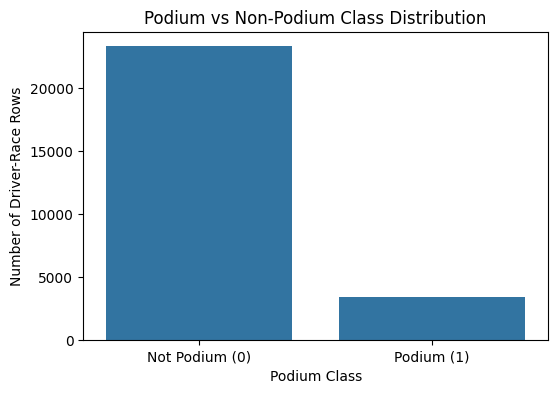

In [334]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=model_df,
    x='podium'
)

plt.title('Podium vs Non-Podium Class Distribution')
plt.xlabel('Podium Class')
plt.ylabel('Number of Driver-Race Rows')
plt.xticks([0, 1], ['Not Podium (0)', 'Podium (1)'])
plt.show()

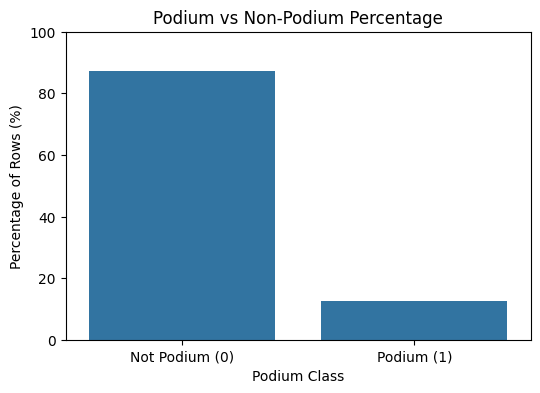

,podium,percentage
0,0,87.269387
1,1,12.730613


In [335]:
podium_percentages = (
    model_df['podium']
    .value_counts(normalize=True)
    .sort_index()
    .reset_index()
)

podium_percentages.columns = ['podium', 'percentage']
podium_percentages['percentage'] = podium_percentages['percentage'] * 100

plt.figure(figsize=(6, 4))

sns.barplot(
    data=podium_percentages,
    x='podium',
    y='percentage'
)

plt.title('Podium vs Non-Podium Percentage')
plt.xlabel('Podium Class')
plt.ylabel('Percentage of Rows (%)')
plt.xticks([0, 1], ['Not Podium (0)', 'Podium (1)'])
plt.ylim(0, 100)
plt.show()

podium_percentages

### Podium Class Distribution Summary

The class distribution plot shows that the dataset is highly imbalanced. Most driver-race rows are non-podium finishes, while podium finishes represent a much smaller proportion of the data.

This is expected because only three drivers can finish on the podium in each race. In this dataset, approximately 12.73% of rows are podium finishes and 87.27% are non-podium finishes.

This imbalance affects model evaluation. Accuracy alone may be misleading because a model could achieve high accuracy by mostly predicting the majority class. Therefore, later evaluation will include metrics that are more suitable for imbalanced binary classification, such as PR-AUC, ROC-AUC, precision, recall, and F1 score.

In [336]:
podium_by_year = (
    model_df
    .groupby('year')
    .agg(
        total_driver_race_rows=('podium', 'size'),
        podiums=('podium', 'sum'),
        podium_rate=('podium', 'mean')
    )
    .reset_index()
)

podium_by_year['podium_rate_percent'] = podium_by_year['podium_rate'] * 100

podium_by_year.head()

,year,total_driver_race_rows,podiums,podium_rate,podium_rate_percent
0,1950,156,22,0.141026,14.102564
1,1951,175,28,0.160000,16.000000
2,1952,212,24,0.113208,11.320755
3,1953,230,29,0.126087,12.608696
4,1954,213,29,0.136150,13.615023


In [337]:
podium_by_year.tail()

,year,total_driver_race_rows,podiums,podium_rate,podium_rate_percent
70,2020,340,51,0.150000,15.000000
71,2021,440,66,0.150000,15.000000
72,2022,440,66,0.150000,15.000000
73,2023,440,66,0.150000,15.000000
74,2024,479,72,0.150313,15.031315


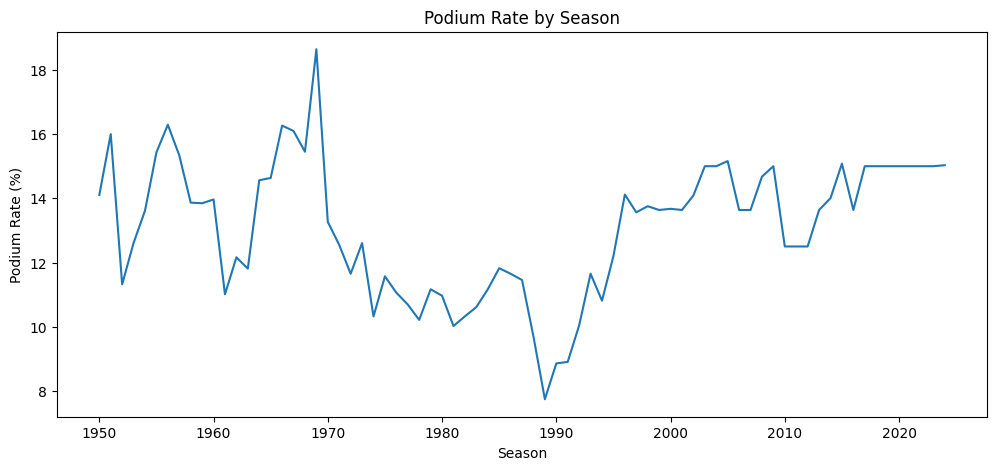

In [338]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=podium_by_year,
    x='year',
    y='podium_rate_percent'
)

plt.title('Podium Rate by Season')
plt.xlabel('Season')
plt.ylabel('Podium Rate (%)')
plt.show()

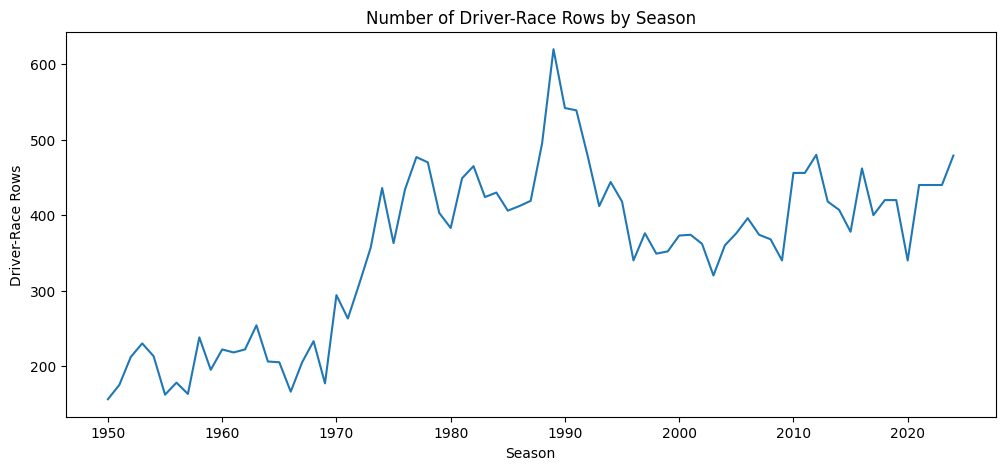

In [339]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=podium_by_year,
    x='year',
    y='total_driver_race_rows'
)

plt.title('Number of Driver-Race Rows by Season')
plt.xlabel('Season')
plt.ylabel('Driver-Race Rows')
plt.show()

### Podium Rate by Season Summary

The podium rate by season shows how the proportion of podium finishes changes over time. In modern seasons, the podium rate is very stable at around 15%, which matches the structure of modern Formula 1: around 20 drivers enter most races, and only 3 drivers can finish on the podium.

In earlier seasons, the podium rate fluctuates more. This is expected because historical Formula 1 had less consistent race-entry sizes, with some seasons and races having larger or more uneven fields. As a result, the percentage of driver-race rows that became podium finishes was not as stable as in the modern era.

The number of driver-race rows by season also changes across history, reflecting changes in the number of races per season and the number of entrants per race. This supports the need to consider time and era effects when building and evaluating the podium prediction model.

In [340]:
def assign_era(year):
    if year <= 1957:
        return '1950-1957 Front-engine era'
    elif year <= 1965:
        return '1958-1965 Rear-engine revolution'
    elif year <= 1976:
        return '1966-1976 3-litre and wings'
    elif year <= 1988:
        return '1977-1988 Turbo and ground effect'
    elif year <= 1994:
        return '1989-1994 Post-turbo'
    elif year <= 2008:
        return '1995-2008 V10 and early V8'
    elif year <= 2013:
        return '2009-2013 Late V8 era'
    elif year <= 2021:
        return '2014-2021 Turbo-hybrid era'
    else:
        return '2022-2024 Ground-effect era'

model_df['era'] = model_df['year'].apply(assign_era)

model_df[['year', 'era']].drop_duplicates().sort_values('year').head(20)

,year,era
20532,1950,1950-1957 Front-engine era
20357,1951,1950-1957 Front-engine era
20145,1952,1950-1957 Front-engine era
19915,1953,1950-1957 Front-engine era
19702,1954,1950-1957 Front-engine era
19540,1955,1950-1957 Front-engine era
19362,1956,1950-1957 Front-engine era
19199,1957,1950-1957 Front-engine era
18961,1958,1958-1965 Rear-engine revolution
18766,1959,1958-1965 Rear-engine revolution


### Era Label Creation Summary

An `era` column was created from the race `year` column to group Formula 1 seasons into major technical and sporting periods.

This is useful because Formula 1 rules, race formats, reliability, field sizes, and competitive patterns changed significantly across history. Grouping seasons into eras allows the analysis to compare podium rates and model behavior across more meaningful historical periods instead of relying only on individual years.

The era labels will also support later milestone requirements, especially the comparison around the 2014 hybrid era and the 2022–2024 ground-effect era.

In [341]:
podium_by_era = (
    model_df
    .groupby('era')
    .agg(
        total_driver_race_rows=('podium', 'size'),
        podiums=('podium', 'sum'),
        podium_rate=('podium', 'mean')
    )
    .reset_index()
)

podium_by_era['podium_rate_percent'] = podium_by_era['podium_rate'] * 100

podium_by_era

,era,total_driver_race_rows,podiums,podium_rate,podium_rate_percent
0,1950-1957 Front-engine era,1489,211,0.141706,14.170584
1,1958-1965 Rear-engine revolution,1760,232,0.131818,13.181818
2,1966-1976 3-litre and wings,3237,417,0.128823,12.882298
3,1977-1988 Turbo and ground effect,5233,564,0.107778,10.777757
4,1989-1994 Post-turbo,3035,288,0.094893,9.489292
5,1995-2008 V10 and early V8,5138,717,0.139548,13.954846
6,2009-2013 Late V8 era,2150,282,0.131163,13.116279
7,2014-2021 Turbo-hybrid era,3267,480,0.146924,14.692378
8,2022-2024 Ground-effect era,1359,204,0.150110,15.011038


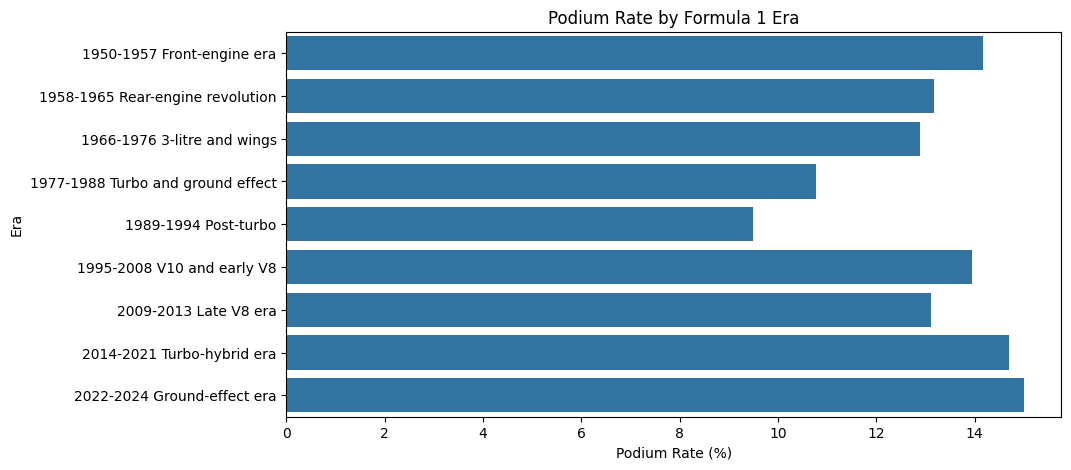

In [342]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=podium_by_era,
    x='podium_rate_percent',
    y='era'
)

plt.title('Podium Rate by Formula 1 Era')
plt.xlabel('Podium Rate (%)')
plt.ylabel('Era')
plt.show()

### Podium Rate by Era Summary

The podium rate by era was calculated to compare how often driver-race entries ended in podium finishes across major Formula 1 historical periods.

This analysis is important because the number of races, number of entrants, reliability, and competition structure changed across F1 history. Therefore, podium probability is not expected to be identical across all eras.

The era-based plot provides an early indication of historical variation in the target variable, which is useful for later feature selection, model evaluation, and limitation discussion.

### Era-Based Podium Rate Interpretation

The podium rate differs across Formula 1 eras. The lowest podium rates appear in the 1989–1994 Post-turbo era and the 1977–1988 Turbo and ground-effect era, while the highest rates appear in the modern 2014–2021 Turbo-hybrid era and 2022–2024 Ground-effect era.

This variation is expected because Formula 1 changed significantly across history. The number of entrants, race formats, reliability, and season structures were not constant across eras. In modern Formula 1, the podium rate is close to 15%, which is consistent with a typical field of around 20 drivers and 3 podium positions per race.

This era-level analysis is important because it shows that the target variable is affected by historical context. Therefore, later modeling and evaluation should consider era sensitivity, and era-based limitations should be discussed in the final report.

In [343]:
model_df['grid'].describe()

count    26668.000000
mean        11.140655
std          7.198745
min          0.000000
25%          5.000000
50%         11.000000
75%         17.000000
max         34.000000
Name: grid, dtype: float64

In [344]:
model_df['grid'].value_counts().sort_index().head(30)

grid
0     1635
1     1124
2     1119
3     1127
4     1128
5     1121
6     1120
7     1132
8     1122
9     1132
10    1125
11    1126
12    1127
13    1122
14    1119
15    1111
16    1098
17    1086
18    1049
19    1028
20     974
21     696
22     656
23     451
24     429
25     301
26     247
27      45
28      28
29      25
Name: count, dtype: int64

In [345]:
podium_by_grid = (
    model_df
    .groupby('grid')
    .agg(
        total_driver_race_rows=('podium', 'size'),
        podiums=('podium', 'sum'),
        podium_rate=('podium', 'mean')
    )
    .reset_index()
)

podium_by_grid['podium_rate_percent'] = podium_by_grid['podium_rate'] * 100

podium_by_grid.head(30)

,grid,total_driver_race_rows,podiums,podium_rate,podium_rate_percent
0,0,1635,0,0.000000,0.000000
1,1,1124,721,0.641459,64.145907
2,2,1119,626,0.559428,55.942806
3,3,1127,523,0.464064,46.406389
4,4,1128,386,0.342199,34.219858
5,5,1121,281,0.250669,25.066905
6,6,1120,209,0.186607,18.660714
7,7,1132,147,0.129859,12.985866
8,8,1122,112,0.099822,9.982175
9,9,1132,94,0.083039,8.303887


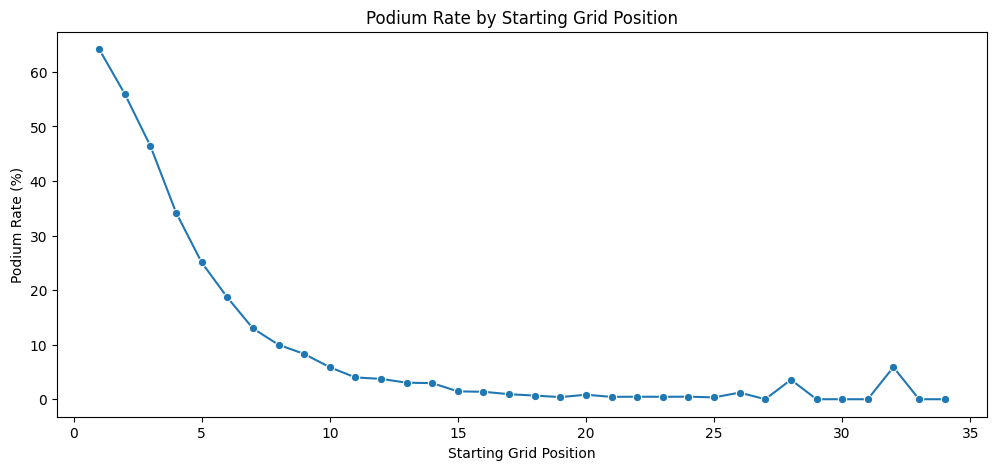

In [346]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=podium_by_grid[podium_by_grid['grid'] > 0],
    x='grid',
    y='podium_rate_percent',
    marker='o'
)

plt.title('Podium Rate by Starting Grid Position')
plt.xlabel('Starting Grid Position')
plt.ylabel('Podium Rate (%)')
plt.show()

### Podium Rate by Starting Grid Position Summary

The grid-position analysis shows a strong relationship between starting position and podium probability. Drivers starting from the front of the grid have a much higher chance of finishing on the podium than drivers starting further back.

For example, pole position (`grid = 1`) has a podium rate of approximately 64.15%, while second place on the grid has a podium rate of approximately 55.94%. The podium rate then decreases sharply as the starting position gets worse. By grid position 10, the podium rate drops to approximately 5.87%, and for most later grid positions the podium rate is very low.

This confirms that starting grid position is one of the strongest pre-race predictors of podium finishes. Since grid position is known before the race starts, it is a valid leakage-safe feature for the prediction model.

Rows with `grid = 0` were also observed. These rows have a 0% podium rate in the current dataset. Since `grid = 0` may represent special cases such as pit-lane starts or historical irregularities, it will be treated carefully during feature engineering rather than immediately removed.

In [347]:
model_df['front_row_start'] = model_df['grid'].isin([1, 2]).astype(int)

print(model_df['front_row_start'].value_counts())
print(model_df['front_row_start'].value_counts(normalize=True))

front_row_start
0    24425
1     2243
Name: count, dtype: int64
front_row_start
0    0.915892
1    0.084108
Name: proportion, dtype: float64


In [348]:
front_row_summary = (
    model_df
    .groupby('front_row_start')
    .agg(
        total_driver_race_rows=('podium', 'size'),
        podiums=('podium', 'sum'),
        podium_rate=('podium', 'mean')
    )
    .reset_index()
)

front_row_summary['podium_rate_percent'] = front_row_summary['podium_rate'] * 100

front_row_summary

,front_row_start,total_driver_race_rows,podiums,podium_rate,podium_rate_percent
0,0,24425,2048,0.083849,8.384852
1,1,2243,1347,0.600535,60.053500


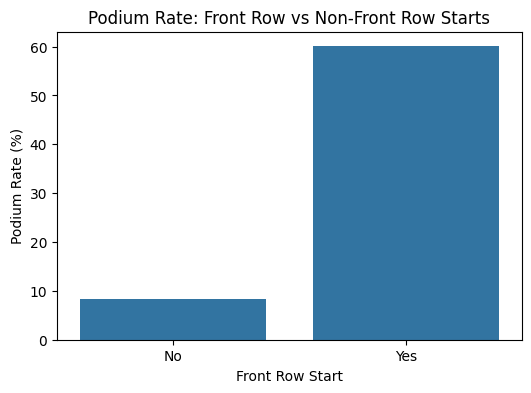

In [349]:
plt.figure(figsize=(6, 4))

sns.barplot(
    data=front_row_summary,
    x='front_row_start',
    y='podium_rate_percent'
)

plt.title('Podium Rate: Front Row vs Non-Front Row Starts')
plt.xlabel('Front Row Start')
plt.ylabel('Podium Rate (%)')
plt.xticks([0, 1], ['No', 'Yes'])
plt.show()

### Front-Row Start Podium Rate Summary

A `front_row_start` feature was created to identify drivers who started from grid position 1 or 2. This feature is important because the first data-engineering question asks which circuits convert front-row starts into podium finishes most often.

The analysis shows a large difference between front-row and non-front-row starters. Drivers starting from the front row achieved a podium rate of approximately 60.05%, while drivers starting outside the front row achieved a podium rate of approximately 8.38%.

This confirms that starting position is strongly associated with podium probability. Since grid position is known before the race starts, `front_row_start` is a valid leakage-safe feature for analysis and later modeling.

In [350]:
front_row_df = model_df[model_df['front_row_start'] == 1].copy()

print("Front-row rows:", front_row_df.shape)
front_row_df[['year', 'race_name', 'circuit_name', 'driverId', 'forename', 'surname', 'grid', 'podium']].head()

Front-row rows: (2243, 37)


,year,race_name,circuit_name,driverId,forename,surname,grid,podium
15,2009,Australian Grand Prix,Albert Park Grand Prix Circuit,18,Jenson,Button,1,1
18,2009,Australian Grand Prix,Albert Park Grand Prix Circuit,22,Rubens,Barrichello,2,1
32,2009,Malaysian Grand Prix,Sepang International Circuit,15,Jarno,Trulli,2,0
35,2009,Malaysian Grand Prix,Sepang International Circuit,18,Jenson,Button,1,1
43,2009,Chinese Grand Prix,Shanghai International Circuit,4,Fernando,Alonso,2,0


In [351]:
circuit_front_row_conversion = (
    front_row_df
    .groupby('circuit_name')
    .agg(
        front_row_starts=('podium', 'size'),
        front_row_podiums=('podium', 'sum'),
        conversion_rate=('podium', 'mean')
    )
    .reset_index()
)

circuit_front_row_conversion['conversion_rate_percent'] = (
    circuit_front_row_conversion['conversion_rate'] * 100
)

# Keep circuits with enough front-row starts to avoid tiny-sample misleading rankings
circuit_front_row_conversion_filtered = (
    circuit_front_row_conversion[circuit_front_row_conversion['front_row_starts'] >= 10]
    .sort_values('conversion_rate_percent', ascending=False)
)

circuit_front_row_conversion_filtered.head(15)

,circuit_name,front_row_starts,front_row_podiums,conversion_rate,conversion_rate_percent
29,Circuit of the Americas,24,20,0.833333,83.333333
70,Sochi Autodrom,16,13,0.812500,81.250000
26,Circuit de Nevers Magny-Cours,36,29,0.805556,80.555556
74,Yas Marina Circuit,32,25,0.781250,78.125000
33,Dijon-Prenois,12,9,0.750000,75.000000
71,Suzuka Circuit,68,51,0.750000,75.000000
67,Sepang International Circuit,37,27,0.729730,72.972973
40,Istanbul Park,18,13,0.722222,72.222222
24,Circuit de Barcelona-Catalunya,68,48,0.705882,70.588235
68,Shanghai International Circuit,34,24,0.705882,70.588235


In [352]:
for threshold in [10, 15, 20]:
    filtered = (
        circuit_front_row_conversion[
            circuit_front_row_conversion['front_row_starts'] >= threshold
        ]
        .sort_values('conversion_rate_percent', ascending=False)
    )
    
    print(f"\nTop 10 circuits with at least {threshold} front-row starts:")
    display(filtered.head(10))


Top 10 circuits with at least 10 front-row starts:


,circuit_name,front_row_starts,front_row_podiums,conversion_rate,conversion_rate_percent
29,Circuit of the Americas,24,20,0.833333,83.333333
70,Sochi Autodrom,16,13,0.812500,81.250000
26,Circuit de Nevers Magny-Cours,36,29,0.805556,80.555556
74,Yas Marina Circuit,32,25,0.781250,78.125000
33,Dijon-Prenois,12,9,0.750000,75.000000
71,Suzuka Circuit,68,51,0.750000,75.000000
67,Sepang International Circuit,37,27,0.729730,72.972973
40,Istanbul Park,18,13,0.722222,72.222222
24,Circuit de Barcelona-Catalunya,68,48,0.705882,70.588235
68,Shanghai International Circuit,34,24,0.705882,70.588235



Top 10 circuits with at least 15 front-row starts:


,circuit_name,front_row_starts,front_row_podiums,conversion_rate,conversion_rate_percent
29,Circuit of the Americas,24,20,0.833333,83.333333
70,Sochi Autodrom,16,13,0.812500,81.250000
26,Circuit de Nevers Magny-Cours,36,29,0.805556,80.555556
74,Yas Marina Circuit,32,25,0.781250,78.125000
71,Suzuka Circuit,68,51,0.750000,75.000000
67,Sepang International Circuit,37,27,0.729730,72.972973
40,Istanbul Park,18,13,0.722222,72.222222
24,Circuit de Barcelona-Catalunya,68,48,0.705882,70.588235
68,Shanghai International Circuit,34,24,0.705882,70.588235
14,Bahrain International Circuit,42,28,0.666667,66.666667



Top 10 circuits with at least 20 front-row starts:


,circuit_name,front_row_starts,front_row_podiums,conversion_rate,conversion_rate_percent
29,Circuit of the Americas,24,20,0.833333,83.333333
26,Circuit de Nevers Magny-Cours,36,29,0.805556,80.555556
74,Yas Marina Circuit,32,25,0.781250,78.125000
71,Suzuka Circuit,68,51,0.750000,75.000000
67,Sepang International Circuit,37,27,0.729730,72.972973
24,Circuit de Barcelona-Catalunya,68,48,0.705882,70.588235
68,Shanghai International Circuit,34,24,0.705882,70.588235
14,Bahrain International Circuit,42,28,0.666667,66.666667
50,Marina Bay Street Circuit,30,20,0.666667,66.666667
38,Hungaroring,78,51,0.653846,65.384615


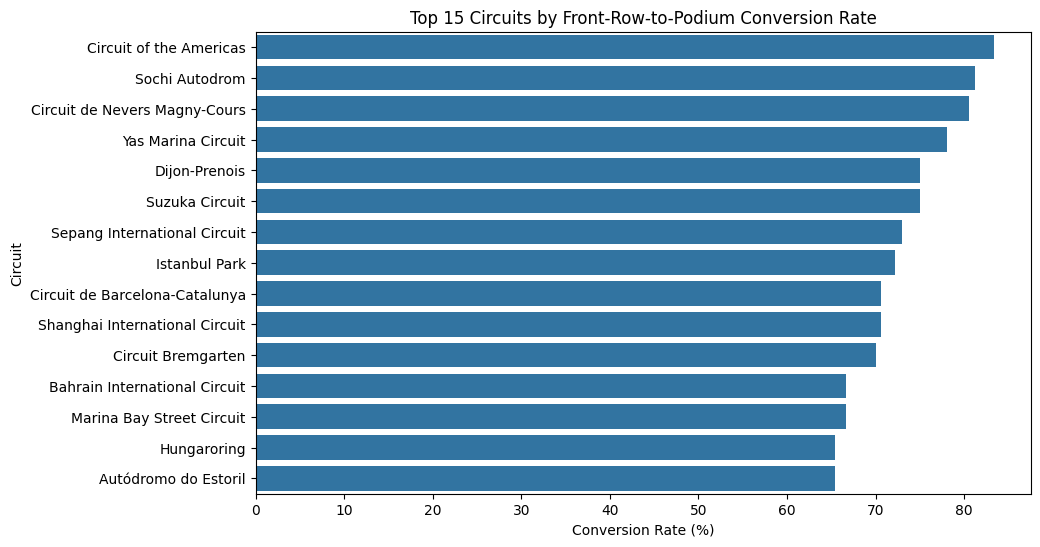

In [353]:
top15_circuits = circuit_front_row_conversion_filtered.head(15)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top15_circuits,
    x='conversion_rate_percent',
    y='circuit_name'
)

plt.title('Top 15 Circuits by Front-Row-to-Podium Conversion Rate')
plt.xlabel('Conversion Rate (%)')
plt.ylabel('Circuit')
plt.show()

### Minimum Sample Size Threshold Justification

To rank circuits by front-row-to-podium conversion rate, circuits with very few front-row starts were filtered out. This is necessary because small samples can create misleading conversion rates. For example, a circuit with only two front-row starts could show a 100% conversion rate if both drivers finished on the podium, but this would not be a reliable indicator of circuit behavior.

A minimum threshold of 10 front-row starts was used for the main ranking. This threshold removes very small-sample circuits while still keeping enough circuits for comparison. However, this threshold is a methodological choice rather than a fixed rule.

To check whether the ranking is sensitive to this decision, additional rankings can be generated using thresholds of 15 and 20 front-row starts. If the same circuits remain near the top across thresholds, the result is more robust. If the ranking changes significantly, this limitation should be mentioned in the interpretation.

In [354]:
model_df['era_2014_split'] = np.where(
    model_df['year'] >= 2014,
    '2014 onward',
    'Before 2014'
)

model_df[['year', 'era_2014_split']].drop_duplicates().sort_values('year').head()

,year,era_2014_split
20532,1950,Before 2014
20357,1951,Before 2014
20145,1952,Before 2014
19915,1953,Before 2014
19702,1954,Before 2014


In [355]:
model_df[['year', 'era_2014_split']].drop_duplicates().sort_values('year').tail()

,year,era_2014_split
24529,2020,2014 onward
24869,2021,2014 onward
25309,2022,2014 onward
25749,2023,2014 onward
26189,2024,2014 onward


In [356]:
front_row_df = model_df[model_df['front_row_start'] == 1].copy()

front_row_df[['year', 'era_2014_split', 'circuit_name', 'grid', 'podium']].head()

,year,era_2014_split,circuit_name,grid,podium
15,2009,Before 2014,Albert Park Grand Prix Circuit,1,1
18,2009,Before 2014,Albert Park Grand Prix Circuit,2,1
32,2009,Before 2014,Sepang International Circuit,2,0
35,2009,Before 2014,Sepang International Circuit,1,1
43,2009,Before 2014,Shanghai International Circuit,2,0


In [357]:
circuit_conversion_by_era2014 = (
    front_row_df
    .groupby(['era_2014_split', 'circuit_name'])
    .agg(
        front_row_starts=('podium', 'size'),
        front_row_podiums=('podium', 'sum'),
        conversion_rate=('podium', 'mean')
    )
    .reset_index()
)

circuit_conversion_by_era2014['conversion_rate_percent'] = (
    circuit_conversion_by_era2014['conversion_rate'] * 100
)

circuit_conversion_by_era2014.head()

,era_2014_split,circuit_name,front_row_starts,front_row_podiums,conversion_rate,conversion_rate_percent
0,2014 onward,Albert Park Grand Prix Circuit,18,13,0.722222,72.222222
1,2014 onward,Autodromo Enzo e Dino Ferrari,8,6,0.750000,75.000000
2,2014 onward,Autodromo Internazionale del Mugello,2,2,1.000000,100.000000
3,2014 onward,Autodromo Nazionale di Monza,22,16,0.727273,72.727273
4,2014 onward,Autódromo Hermanos Rodríguez,18,11,0.611111,61.111111


In [358]:
circuit_conversion_by_era2014_filtered = (
    circuit_conversion_by_era2014[
        circuit_conversion_by_era2014['front_row_starts'] >= 6
    ]
    .sort_values(
        ['era_2014_split', 'conversion_rate_percent'],
        ascending=[True, False]
    )
)

circuit_conversion_by_era2014_filtered

,era_2014_split,circuit_name,front_row_starts,front_row_podiums,conversion_rate,conversion_rate_percent
23,2014 onward,Miami International Autodrome,6,6,1.000000,100.000000
30,2014 onward,Suzuka Circuit,18,16,0.888889,88.888889
10,2014 onward,Circuit Park Zandvoort,8,7,0.875000,87.500000
19,2014 onward,Jeddah Corniche Circuit,8,7,0.875000,87.500000
31,2014 onward,Yas Marina Circuit,22,19,0.863636,86.363636
...,...,...,...,...,...,...
90,Before 2014,Scandinavian Raceway,12,5,0.416667,41.666667
45,Before 2014,Brands Hatch,28,11,0.392857,39.285714
40,Before 2014,Autódromo Internacional Nelson Piquet,20,7,0.350000,35.000000
61,Before 2014,Detroit Street Circuit,14,4,0.285714,28.571429


### Era-Split Minimum Sample Size Note

For the pre/post-2014 circuit comparison, a lower minimum threshold of 6 front-row starts was used because splitting the dataset into two time periods reduces the number of observations available for each circuit.

Since each race normally has two front-row starters, 6 front-row starts correspond to approximately three races at that circuit within the period. This threshold helps remove circuits with extremely small samples while still preserving enough circuits for comparison across the pre-2014 and 2014-onward periods.

The threshold is a methodological choice and should be interpreted as a balance between sample reliability and retaining enough circuits for analysis.

In [359]:
top_circuits_by_era2014 = (
    circuit_conversion_by_era2014_filtered
    .groupby('era_2014_split')
    .head(10)
)

top_circuits_by_era2014

,era_2014_split,circuit_name,front_row_starts,front_row_podiums,conversion_rate,conversion_rate_percent
23,2014 onward,Miami International Autodrome,6,6,1.000000,100.000000
30,2014 onward,Suzuka Circuit,18,16,0.888889,88.888889
10,2014 onward,Circuit Park Zandvoort,8,7,0.875000,87.500000
19,2014 onward,Jeddah Corniche Circuit,8,7,0.875000,87.500000
31,2014 onward,Yas Marina Circuit,22,19,0.863636,86.363636
26,2014 onward,Sepang International Circuit,7,6,0.857143,85.714286
13,2014 onward,Circuit de Monaco,20,17,0.850000,85.000000
12,2014 onward,Circuit de Barcelona-Catalunya,22,18,0.818182,81.818182
14,2014 onward,Circuit de Spa-Francorchamps,22,18,0.818182,81.818182
29,2014 onward,Sochi Autodrom,16,13,0.812500,81.250000


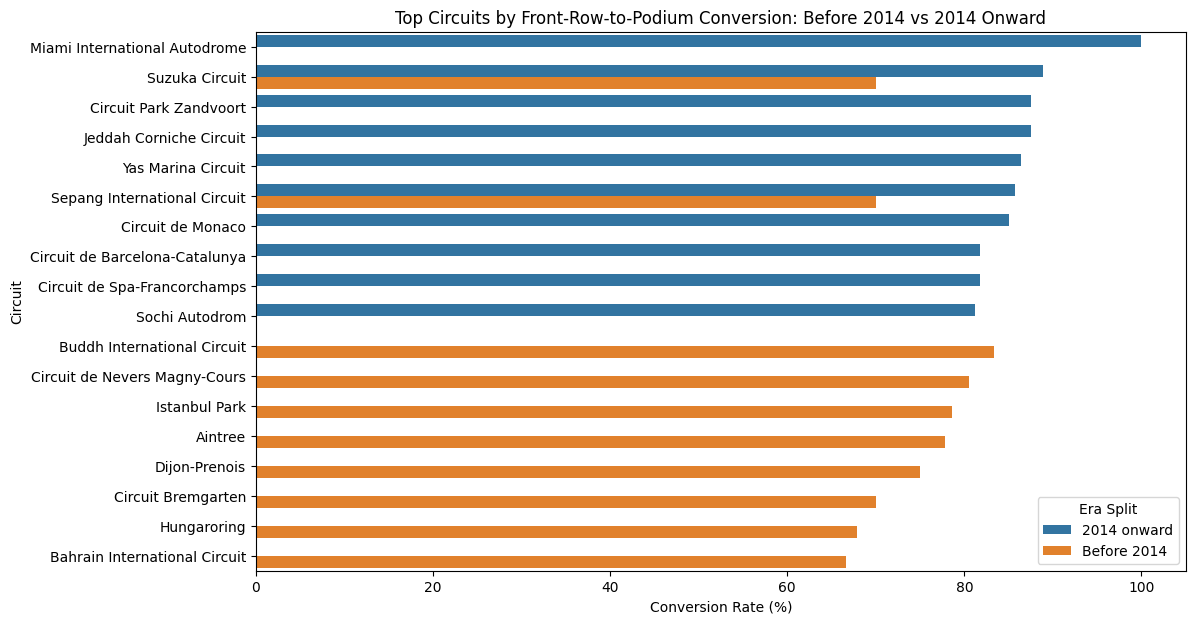

In [360]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_circuits_by_era2014,
    x='conversion_rate_percent',
    y='circuit_name',
    hue='era_2014_split'
)

plt.title('Top Circuits by Front-Row-to-Podium Conversion: Before 2014 vs 2014 Onward')
plt.xlabel('Conversion Rate (%)')
plt.ylabel('Circuit')
plt.legend(title='Era Split')
plt.show()

### Data-Engineering Question 1 Answer

To answer the first data-engineering question, the dataset was filtered to include only front-row starters, defined as drivers starting from grid position 1 or 2. For each circuit, the front-row-to-podium conversion rate was calculated as:

`front_row_podiums / front_row_starts`

A minimum sample threshold was applied to avoid misleading rankings from circuits with very few front-row starts.

Overall, front-row starts are strongly associated with podium finishes. Front-row starters achieved a podium rate of approximately 60.05%, compared with approximately 8.38% for non-front-row starters.

The circuit ranking does change after the 2014 hybrid-era split. In the 2014-onward period, circuits such as Miami International Autodrome, Suzuka Circuit, Circuit Park Zandvoort, Jeddah Corniche Circuit, and Yas Marina Circuit appear near the top of the ranking. Before 2014, the top circuits include Buddh International Circuit, Circuit de Nevers Magny-Cours, Istanbul Park, Aintree, and Dijon-Prenois.

This indicates that front-row-to-podium conversion is not identical across historical periods. The change in ranking may reflect differences in circuit characteristics, race eras, car regulations, competitive structure, and sample availability. However, these results should be interpreted as descriptive associations, not causal effects.

### Question 1 Limitation

The circuit rankings are sensitive to the minimum sample-size threshold. Some circuits in the top rankings have relatively small numbers of front-row starts, especially after splitting the data into pre-2014 and 2014-onward periods. Therefore, high conversion rates such as 100% should not automatically be interpreted as proof that a circuit guarantees podium conversion from the front row.

The result is best understood as a descriptive historical comparison of observed front-row-to-podium conversion rates.

### Qualifying Position vs Starting Grid Clarification

For the front-row-to-podium analysis, front-row starters were identified using the `grid` column from the `results` table, not the `position` column from the `qualifying` table.

This distinction is important because qualifying position and starting grid position do not always match. Penalties, pit-lane starts, exclusions, and other race-weekend decisions can change the final starting grid after qualifying. Since the question asks about converting a front-row start into a podium, the correct variable is the actual starting grid position.

Therefore, `front_row_start` was defined as `grid` equal to 1 or 2.

In [361]:
print("Driver nationalities:")
print(sorted(model_df['driver_nationality'].dropna().unique()))

print("\nCircuit countries:")
print(sorted(model_df['circuit_country'].dropna().unique()))

Driver nationalities:
['American', 'American-Italian', 'Argentine', 'Argentine-Italian', 'Argentinian ', 'Australian', 'Austrian', 'Belgian', 'Brazilian', 'British', 'Canadian', 'Chilean', 'Chinese', 'Colombian', 'Czech', 'Danish', 'Dutch', 'East German', 'Finnish', 'French', 'German', 'Hungarian', 'Indian', 'Indonesian', 'Irish', 'Italian', 'Japanese', 'Liechtensteiner', 'Malaysian', 'Mexican', 'Monegasque', 'New Zealander', 'Polish', 'Portuguese', 'Rhodesian', 'Russian', 'South African', 'Spanish', 'Swedish', 'Swiss', 'Thai', 'Uruguayan', 'Venezuelan']

Circuit countries:
['Argentina', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'China', 'France', 'Germany', 'Hungary', 'India', 'Italy', 'Japan', 'Korea', 'Malaysia', 'Mexico', 'Monaco', 'Morocco', 'Netherlands', 'Portugal', 'Qatar', 'Russia', 'Saudi Arabia', 'Singapore', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Turkey', 'UAE', 'UK', 'USA', 'United States']


In [362]:
nationality_to_country = {
    'American': 'USA',
    'Argentine': 'Argentina',
    'Argentine-Italian': 'Argentina',
    'Australian': 'Australia',
    'Austrian': 'Austria',
    'Belgian': 'Belgium',
    'Brazilian': 'Brazil',
    'British': 'UK',
    'Canadian': 'Canada',
    'Chilean': 'Chile',
    'Chinese': 'China',
    'Colombian': 'Colombia',
    'Czech': 'Czech Republic',
    'Danish': 'Denmark',
    'Dutch': 'Netherlands',
    'East German': 'Germany',
    'Finnish': 'Finland',
    'French': 'France',
    'German': 'Germany',
    'Hungarian': 'Hungary',
    'Indian': 'India',
    'Indonesian': 'Indonesia',
    'Irish': 'Ireland',
    'Italian': 'Italy',
    'Japanese': 'Japan',
    'Liechtensteiner': 'Switzerland',
    'Malaysian': 'Malaysia',
    'Mexican': 'Mexico',
    'Monegasque': 'Monaco',
    'New Zealander': 'New Zealand',
    'Polish': 'Poland',
    'Portuguese': 'Portugal',
    'Rhodesian': 'South Africa',
    'Russian': 'Russia',
    'South African': 'South Africa',
    'Spanish': 'Spain',
    'Swedish': 'Sweden',
    'Swiss': 'Switzerland',
    'Thai': 'Thailand',
    'Uruguayan': 'Uruguay',
    'Venezuelan': 'Venezuela'
}

In [363]:
model_df['driver_country'] = model_df['driver_nationality'].map(nationality_to_country)

model_df['home_race'] = (
    model_df['driver_country'] == model_df['circuit_country']
).astype(int)

print(model_df[['driver_nationality', 'driver_country', 'circuit_country', 'home_race']].head(20))

print("\nHome race counts:")
print(model_df['home_race'].value_counts())

print("\nHome race percentages:")
print(model_df['home_race'].value_counts(normalize=True))

   driver_nationality driver_country circuit_country  home_race
0             British             UK       Australia          0
1              German        Germany       Australia          0
2              German        Germany       Australia          0
3             Spanish          Spain       Australia          0
4             Finnish        Finland       Australia          0
5            Japanese          Japan       Australia          0
6              French         France       Australia          0
7             Finnish        Finland       Australia          0
8              Polish         Poland       Australia          0
9              German        Germany       Australia          0
10          Brazilian         Brazil       Australia          0
11          Brazilian         Brazil       Australia          0
12            Italian          Italy       Australia          0
13             German        Germany       Australia          0
14         Australian      Australia    

In [364]:
unmapped_nationalities = (
    model_df.loc[model_df['driver_country'].isna(), 'driver_nationality']
    .dropna()
    .unique()
)

print("Unmapped nationalities:")
print(sorted(unmapped_nationalities))

Unmapped nationalities:
['American-Italian', 'Argentinian ']


In [365]:
def grid_group(grid):
    if grid == 0:
        return 'Grid 0 / special'
    elif grid <= 3:
        return 'P1-P3'
    elif grid <= 6:
        return 'P4-P6'
    elif grid <= 10:
        return 'P7-P10'
    elif grid <= 15:
        return 'P11-P15'
    elif grid <= 20:
        return 'P16-P20'
    else:
        return 'P21+'

model_df['grid_group'] = model_df['grid'].apply(grid_group)

model_df[['grid', 'grid_group']].head(20)

,grid,grid_group
0,18,P16-P20
1,9,P7-P10
2,5,P4-P6
3,10,P7-P10
4,12,P11-P15
5,11,P11-P15
6,17,P16-P20
7,7,P7-P10
8,4,P4-P6
9,19,P16-P20


In [366]:
home_race_by_grid = (
    model_df
    .groupby(['grid_group', 'home_race'])
    .agg(
        total_driver_race_rows=('podium', 'size'),
        podiums=('podium', 'sum'),
        podium_rate=('podium', 'mean')
    )
    .reset_index()
)

home_race_by_grid['podium_rate_percent'] = home_race_by_grid['podium_rate'] * 100

home_race_by_grid

,grid_group,home_race,total_driver_race_rows,podiums,podium_rate,podium_rate_percent
0,Grid 0 / special,0,1464,0,0.000000,0.000000
1,Grid 0 / special,1,171,0,0.000000,0.000000
2,P1-P3,0,3106,1725,0.555377,55.537669
3,P1-P3,1,264,145,0.549242,54.924242
4,P11-P15,0,5132,154,0.030008,3.000779
5,P11-P15,1,473,16,0.033827,3.382664
6,P16-P20,0,4732,41,0.008664,0.866441
7,P16-P20,1,503,3,0.005964,0.596421
8,P21+,0,2496,12,0.004808,0.480769
9,P21+,1,447,4,0.008949,0.894855


   home_race         race_location
0          0  Away Race (Not Home)
1          1             Home Race


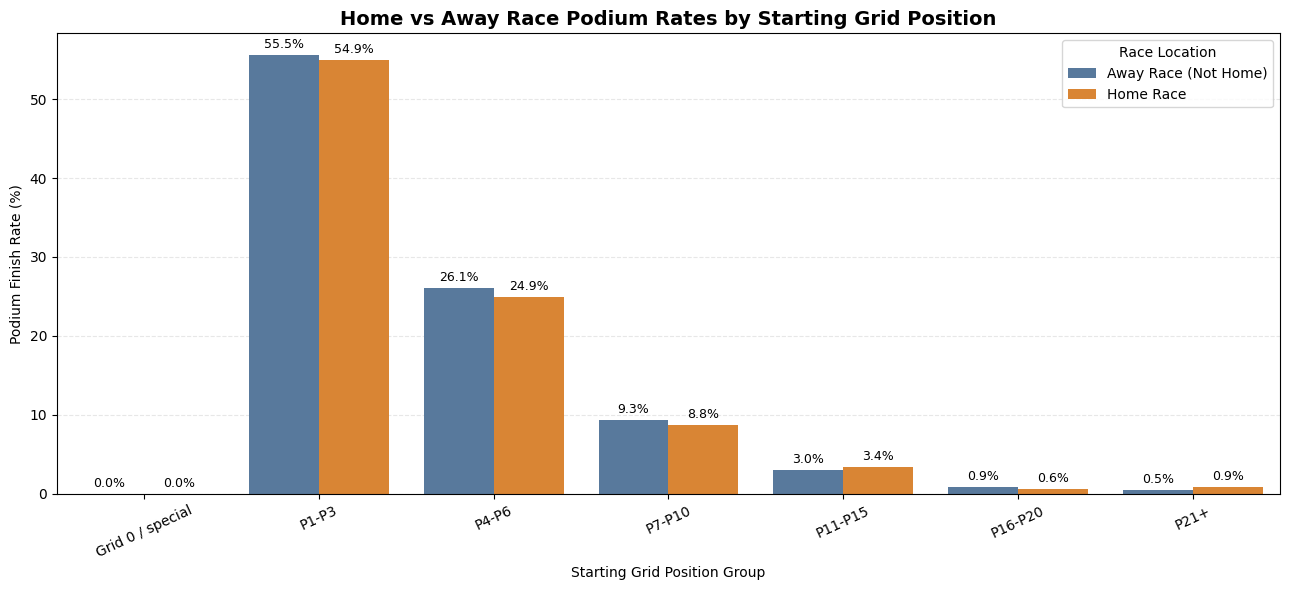

In [367]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

grid_order = [
    'Grid 0 / special',
    'P1-P3',
    'P4-P6',
    'P7-P10',
    'P11-P15',
    'P16-P20',
    'P21+'
]

# Work on a copy of the original data
plot_df = home_race_by_grid.copy()

# Convert home_race values into clear labels
plot_df['race_location'] = (
    plot_df['home_race']
    .astype(str)
    .str.strip()
    .str.lower()
    .map({
        'true': 'Home Race',
        '1': 'Home Race',
        'yes': 'Home Race',
        'false': 'Away Race (Not Home)',
        '0': 'Away Race (Not Home)',
        'no': 'Away Race (Not Home)'
    })
)

# Check that both categories were mapped correctly
print(plot_df[['home_race', 'race_location']].drop_duplicates())

if plot_df['race_location'].isna().any():
    raise ValueError(
        "Some home_race values could not be mapped. "
        "Check the printed categories."
    )

plt.figure(figsize=(13, 6))

ax = sns.barplot(
    data=plot_df,
    x='grid_group',
    y='podium_rate_percent',
    hue='race_location',
    order=grid_order,
    hue_order=['Away Race (Not Home)', 'Home Race'],
    palette={
        'Away Race (Not Home)': '#4C78A8',
        'Home Race': '#F58518'
    },
    errorbar=None
)

# Display percentages above the bars
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.1f%%',
        padding=3,
        fontsize=9
    )

plt.title(
    'Home vs Away Race Podium Rates by Starting Grid Position',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Starting Grid Position Group')
plt.ylabel('Podium Finish Rate (%)')

plt.legend(
    title='Race Location',
    loc='upper right'
)

plt.xticks(rotation=25)
plt.grid(axis='y', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


In [368]:
home_race_overall = (
    model_df
    .groupby('home_race')
    .agg(
        total_driver_race_rows=('podium', 'size'),
        podiums=('podium', 'sum'),
        podium_rate=('podium', 'mean')
    )
    .reset_index()
)

home_race_overall['podium_rate_percent'] = home_race_overall['podium_rate'] * 100

home_race_overall

,home_race,total_driver_race_rows,podiums,podium_rate,podium_rate_percent
0,0,24161,3128,0.129465,12.946484
1,1,2507,267,0.106502,10.650179


### Home-Race Feature Engineering Summary

To answer the second data-engineering question, a `home_race` feature was created by mapping each driver's nationality to a country and comparing it with the circuit country.

This mapping is necessary because driver nationality values and circuit country values do not always use the same wording. For example, a British driver must be mapped to the UK circuit country value.

To control for starting position, grid positions were grouped into similar starting-position buckets: P1-P3, P4-P6, P7-P10, P11-P15, P16-P20, P21+, and Grid 0/special. This allows home-race and non-home-race podium rates to be compared among drivers who started from broadly similar positions rather than comparing all drivers directly.

### Home-Race Mapping Correction

After creating the initial `home_race` feature, two unmapped nationality values were found: `American-Italian` and `Argentinian`. The `Argentinian` value also contained extra whitespace.

Before finalizing the home-race analysis, these values were corrected in the nationality-to-country mapping and the dependent home-race summaries were recalculated. This ensures that the final Question 2 results use the corrected `home_race` feature.

In [369]:
# Clean whitespace in driver nationality values
model_df['driver_nationality'] = model_df['driver_nationality'].str.strip()

# Add missing mappings
nationality_to_country['American-Italian'] = 'USA'
nationality_to_country['Argentinian'] = 'Argentina'

# Recreate driver_country using the corrected mapping
model_df['driver_country'] = model_df['driver_nationality'].map(nationality_to_country)

# Recreate home_race after correction
model_df['home_race'] = (
    model_df['driver_country'] == model_df['circuit_country']
).astype(int)

# Check unmapped nationalities again
unmapped_nationalities = (
    model_df.loc[model_df['driver_country'].isna(), 'driver_nationality']
    .dropna()
    .unique()
)

print("Unmapped nationalities:")
print(sorted(unmapped_nationalities))

Unmapped nationalities:
[]


In [370]:
home_race_by_grid = (
    model_df
    .groupby(['grid_group', 'home_race'])
    .agg(
        total_driver_race_rows=('podium', 'size'),
        podiums=('podium', 'sum'),
        podium_rate=('podium', 'mean')
    )
    .reset_index()
)

home_race_by_grid['podium_rate_percent'] = home_race_by_grid['podium_rate'] * 100

home_race_by_grid

,grid_group,home_race,total_driver_race_rows,podiums,podium_rate,podium_rate_percent
0,Grid 0 / special,0,1464,0,0.000000,0.000000
1,Grid 0 / special,1,171,0,0.000000,0.000000
2,P1-P3,0,3106,1725,0.555377,55.537669
3,P1-P3,1,264,145,0.549242,54.924242
4,P11-P15,0,5132,154,0.030008,3.000779
5,P11-P15,1,473,16,0.033827,3.382664
6,P16-P20,0,4732,41,0.008664,0.866441
7,P16-P20,1,503,3,0.005964,0.596421
8,P21+,0,2496,12,0.004808,0.480769
9,P21+,1,447,4,0.008949,0.894855


In [371]:
home_race_overall = (
    model_df
    .groupby('home_race')
    .agg(
        total_driver_race_rows=('podium', 'size'),
        podiums=('podium', 'sum'),
        podium_rate=('podium', 'mean')
    )
    .reset_index()
)

home_race_overall['podium_rate_percent'] = home_race_overall['podium_rate'] * 100

home_race_overall

,home_race,total_driver_race_rows,podiums,podium_rate,podium_rate_percent
0,0,24161,3128,0.129465,12.946484
1,1,2507,267,0.106502,10.650179


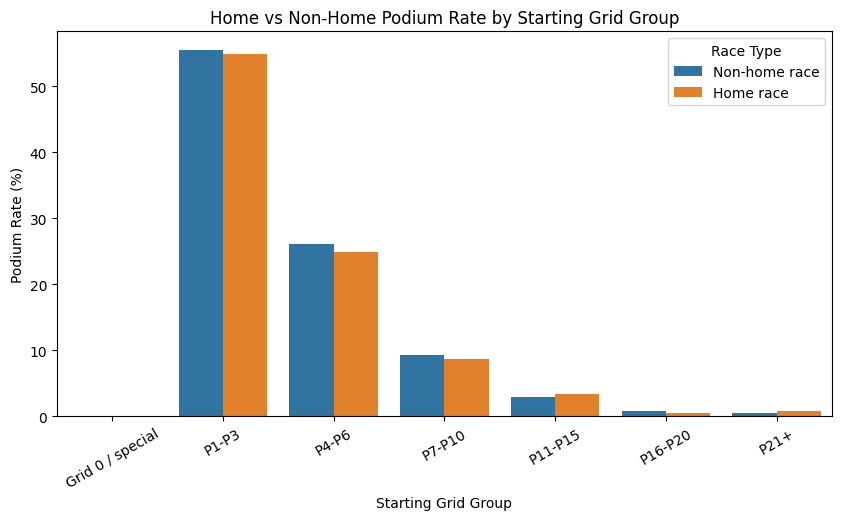

In [372]:
# Create readable labels for the plot
home_race_by_grid['home_race_label'] = home_race_by_grid['home_race'].map({
    0: 'Non-home race',
    1: 'Home race'
})

grid_order = [
    'Grid 0 / special',
    'P1-P3',
    'P4-P6',
    'P7-P10',
    'P11-P15',
    'P16-P20',
    'P21+'
]

plt.figure(figsize=(10, 5))

sns.barplot(
    data=home_race_by_grid,
    x='grid_group',
    y='podium_rate_percent',
    hue='home_race_label',
    order=grid_order
)

plt.title('Home vs Non-Home Podium Rate by Starting Grid Group')
plt.xlabel('Starting Grid Group')
plt.ylabel('Podium Rate (%)')
plt.legend(title='Race Type')
plt.xticks(rotation=30)
plt.show()

The legend was converted from numeric labels to readable labels, where `Non-home race` means the driver's mapped country does not match the circuit country, and `Home race` means the driver's mapped country matches the circuit country.

### Question 2 Limitation

The home-race feature depends on a nationality-to-country mapping, which simplifies some historical and political cases. Some nationalities required manual handling, such as `American-Italian` and `Argentinian`.

In addition, driver nationality does not always perfectly represent a driver's personal home race context. The analysis controls for starting position using grid-position groups rather than exact grid positions. This improves sample size within each comparison group but may still hide variation within each bucket.

Therefore, the result should be interpreted as a descriptive comparison rather than a causal estimate of a home-race advantage.

### Data-Engineering Question 2 Answer

To answer the second data-engineering question, a `home_race` feature was created by mapping each driver's nationality to a comparable country value and comparing it with the circuit country. This mapping was necessary because driver nationalities and circuit countries are not always written in the same format. For example, a British driver must be mapped to the UK.

The overall comparison shows that non-home-race entries have a podium rate of approximately 12.95%, while home-race entries have a podium rate of approximately 10.65%. However, this overall comparison is not sufficient because starting position strongly affects podium probability.

To control for starting position, grid positions were grouped into starting-position buckets: Grid 0/special, P1-P3, P4-P6, P7-P10, P11-P15, P16-P20, and P21+. Within these groups, home-race and non-home-race podium rates were compared.

After controlling for starting position, the results do not show a consistent home-race podium advantage. In the P1-P3 group, the rates are very similar: non-home entries have a podium rate of approximately 55.54%, while home entries have a podium rate of approximately 54.92%. In P4-P6 and P7-P10, home-race entries are slightly lower. In P11-P15 and P21+, home-race entries are slightly higher, but the podium counts are smaller.

Therefore, based on this descriptive analysis, home-race status does not appear to consistently increase podium probability once starting position is controlled for. Starting position remains the stronger explanatory factor.

In [373]:
retirement_df = results_clean.copy()

retirement_df = retirement_df.merge(
    races[['raceId', 'year', 'name']],
    on='raceId',
    how='left'
)

retirement_df = retirement_df.rename(columns={
    'name': 'race_name'
})

retirement_df = retirement_df.merge(
    constructors[['constructorId', 'constructorRef', 'name']],
    on='constructorId',
    how='left'
)

retirement_df = retirement_df.rename(columns={
    'name': 'constructor_name'
})

retirement_df = retirement_df.merge(
    status[['statusId', 'status']],
    on='statusId',
    how='left'
)

retirement_df[['year', 'race_name', 'constructor_name', 'grid', 'status']].head()

,year,race_name,constructor_name,grid,status
0,2009,Australian Grand Prix,McLaren,18,Disqualified
1,2009,Australian Grand Prix,BMW Sauber,9,Finished
2,2009,Australian Grand Prix,Williams,5,Finished
3,2009,Australian Grand Prix,Renault,10,Finished
4,2009,Australian Grand Prix,McLaren,12,Collision


In [374]:
retirement_df = retirement_df[
    (retirement_df['year'] >= 2014) &
    (retirement_df['year'] <= 2024) &
    (retirement_df['grid'] > 0)
].copy()

retirement_df['period'] = np.where(
    retirement_df['year'] <= 2021,
    '2014-2021',
    '2022-2024'
)

retirement_df['period'].value_counts()

period
2014-2021    3228
2022-2024    1319
Name: count, dtype: int64

In [375]:
status_counts_2014_2024 = (
    retirement_df['status']
    .value_counts()
    .reset_index()
)

status_counts_2014_2024.columns = ['status', 'count']

status_counts_2014_2024.head(50)

,status,count
0,Finished,2381
1,+1 Lap,1151
2,+2 Laps,201
3,Collision,149
4,Accident,83
5,Engine,80
6,Collision damage,56
7,Retired,48
8,Brakes,47
9,Gearbox,41


In [376]:
mechanical_statuses = [
    'Battery',
    'Brake duct',
    'Brakes',
    'Clutch',
    'Cooling system',
    'Differential',
    'Driveshaft',
    'Drivetrain',
    'ERS',
    'Electrical',
    'Electronics',
    'Engine',
    'Exhaust',
    'Fire',
    'Fuel leak',
    'Fuel pressure',
    'Fuel pump',
    'Fuel system',
    'Gearbox',
    'Hydraulics',
    'Oil leak',
    'Oil pressure',
    'Overheating',
    'Power Unit',
    'Power loss',
    'Puncture',
    'Radiator',
    'Spark plugs',
    'Safety belt',
    'Steering',
    'Suspension',
    'Technical',
    'Throttle',
    'Transmission',
    'Turbo',
    'Tyre',
    'Tyre puncture',
    'Vibrations',
    'Water leak',
    'Water pressure',
    'Water pump',
    'Wheel',
    'Wheel nut',
    'Mechanical'
]

In [377]:
retirement_df['mechanical_retirement'] = (
    retirement_df['status'].isin(mechanical_statuses)
).astype(int)

retirement_df[['year', 'period', 'constructor_name', 'status', 'mechanical_retirement']].head(20)

,year,period,constructor_name,status,mechanical_retirement
22042,2014,2014-2021,Mercedes,Engine,1
22043,2014,2014-2021,Mercedes,Finished,0
22044,2014,2014-2021,Ferrari,Finished,0
22045,2014,2014-2021,Ferrari,Finished,0
22046,2014,2014-2021,Williams,Collision,0
22047,2014,2014-2021,Sauber,+1 Lap,0
22048,2014,2014-2021,McLaren,Finished,0
22049,2014,2014-2021,Red Bull,Engine,1
22050,2014,2014-2021,Lotus F1,ERS,1
22051,2014,2014-2021,Caterham,Collision,0


In [378]:
mechanical_summary = (
    retirement_df
    .groupby(['period', 'mechanical_retirement'])
    .agg(
        total_rows=('mechanical_retirement', 'size')
    )
    .reset_index()
)

mechanical_summary

,period,mechanical_retirement,total_rows
0,2014-2021,0,2912
1,2014-2021,1,316
2,2022-2024,0,1244
3,2022-2024,1,75


In [379]:
constructor_mechanical_rates = (
    retirement_df
    .groupby(['period', 'constructor_name'])
    .agg(
        race_starts=('mechanical_retirement', 'size'),
        mechanical_retirements=('mechanical_retirement', 'sum'),
        mechanical_retirement_rate=('mechanical_retirement', 'mean')
    )
    .reset_index()
)

constructor_mechanical_rates['mechanical_retirement_rate_percent'] = (
    constructor_mechanical_rates['mechanical_retirement_rate'] * 100
)

constructor_mechanical_rates.head()

,period,constructor_name,race_starts,mechanical_retirements,mechanical_retirement_rate,mechanical_retirement_rate_percent
0,2014-2021,Alfa Romeo,115,5,0.043478,4.347826
1,2014-2021,AlphaTauri,75,6,0.080000,8.000000
2,2014-2021,Alpine F1 Team,44,3,0.068182,6.818182
3,2014-2021,Aston Martin,43,0,0.000000,0.000000
4,2014-2021,Caterham,34,8,0.235294,23.529412


In [380]:
constructor_mechanical_rates_filtered = (
    constructor_mechanical_rates[
        constructor_mechanical_rates['race_starts'] >= 20
    ]
    .sort_values(
        ['period', 'mechanical_retirement_rate_percent'],
        ascending=[True, False]
    )
)

constructor_mechanical_rates_filtered

,period,constructor_name,race_starts,mechanical_retirements,mechanical_retirement_rate,mechanical_retirement_rate_percent
4,2014-2021,Caterham,34,8,0.235294,23.529412
8,2014-2021,Lotus F1,76,14,0.184211,18.421053
17,2014-2021,Toro Rosso,238,39,0.163866,16.386555
11,2014-2021,McLaren,320,46,0.143750,14.375000
15,2014-2021,Renault,199,28,0.140704,14.070352
16,2014-2021,Sauber,199,23,0.115578,11.557789
14,2014-2021,Red Bull,312,34,0.108974,10.897436
13,2014-2021,Racing Point,75,8,0.106667,10.666667
10,2014-2021,Marussia,31,3,0.096774,9.677419
7,2014-2021,Haas F1 Team,240,23,0.095833,9.583333


In [381]:
top_mechanical_by_period = (
    constructor_mechanical_rates_filtered
    .groupby('period')
    .head(10)
)

top_mechanical_by_period

,period,constructor_name,race_starts,mechanical_retirements,mechanical_retirement_rate,mechanical_retirement_rate_percent
4,2014-2021,Caterham,34,8,0.235294,23.529412
8,2014-2021,Lotus F1,76,14,0.184211,18.421053
17,2014-2021,Toro Rosso,238,39,0.163866,16.386555
11,2014-2021,McLaren,320,46,0.143750,14.375000
15,2014-2021,Renault,199,28,0.140704,14.070352
16,2014-2021,Sauber,199,23,0.115578,11.557789
14,2014-2021,Red Bull,312,34,0.108974,10.897436
13,2014-2021,Racing Point,75,8,0.106667,10.666667
10,2014-2021,Marussia,31,3,0.096774,9.677419
7,2014-2021,Haas F1 Team,240,23,0.095833,9.583333


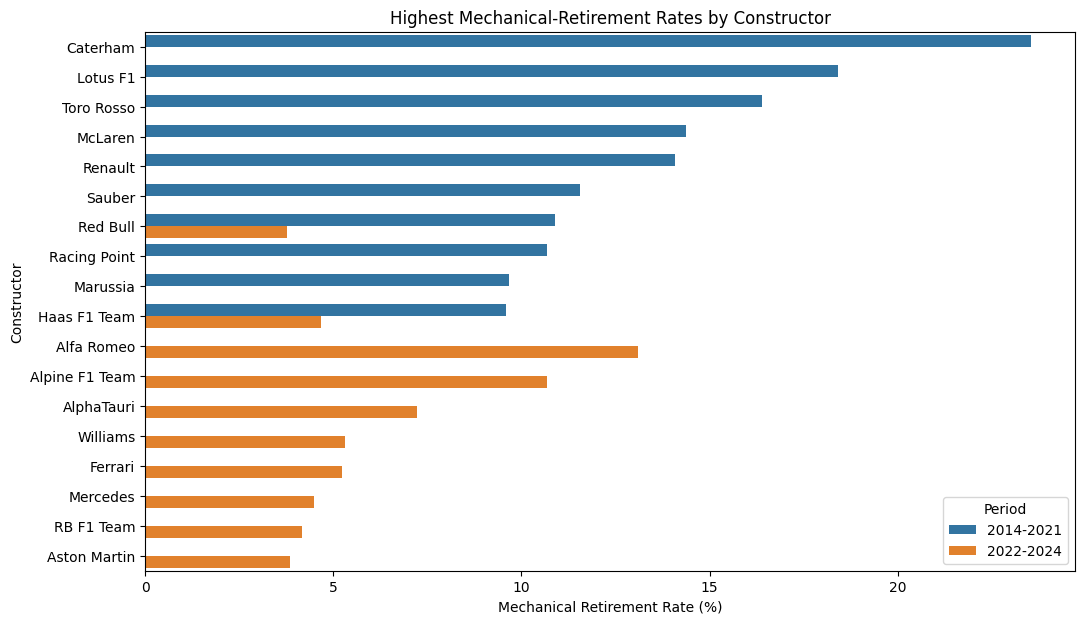

In [382]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_mechanical_by_period,
    x='mechanical_retirement_rate_percent',
    y='constructor_name',
    hue='period'
)

plt.title('Highest Mechanical-Retirement Rates by Constructor')
plt.xlabel('Mechanical Retirement Rate (%)')
plt.ylabel('Constructor')
plt.legend(title='Period')
plt.show()

### Mechanical-Retirement Classification

To answer the third data-engineering question, race-ending statuses were classified into mechanical and non-mechanical outcomes.

Mechanical retirements were defined as statuses caused by car or component failures, such as engine, gearbox, brakes, hydraulics, power unit, ERS, electrical, suspension, oil pressure, fuel pressure, cooling, transmission, steering, clutch, and similar technical failures.

Statuses caused by crashes, collisions, driver errors, illness, disqualification, withdrawal, or classified finishes such as `Finished`, `+1 Lap`, and `+2 Laps` were not counted as mechanical retirements.

This classification is necessary because the raw `status` table contains many different race-ending labels, and the milestone requires mechanical failures to be separated from accidents, driver-related causes, and regulation decisions.

### Data-Engineering Question 3 Answer

To answer the third data-engineering question, the `results`, `races`, `constructors`, and `status` tables were joined to analyze constructor-level mechanical-retirement rates.

The analysis was restricted to the required periods: 2014–2021 and 2022–2024. Race-ending statuses were classified into mechanical and non-mechanical outcomes. Mechanical retirements included component or technical failures such as engine, gearbox, power unit, brakes, hydraulics, suspension, electrical, fuel pressure, oil pressure, overheating, ERS, transmission, clutch, steering, and related technical statuses. Finished/classified rows, crashes, collisions, driver errors, withdrawals, disqualifications, and other non-component causes were not counted as mechanical retirements.

For 2014–2021, the constructors with the highest mechanical-retirement rates were Caterham, Lotus F1, Toro Rosso, McLaren, and Renault. Caterham had the highest rate among constructors with at least 20 race starts, with 8 mechanical retirements from 34 starts, or approximately 23.53%.

For 2022–2024, the constructors with the highest mechanical-retirement rates were Alfa Romeo, Alpine F1 Team, AlphaTauri, Ferrari, and Williams. Alfa Romeo had the highest rate in this period, with 10 mechanical retirements from 88 starts, or approximately 11.36%.

Overall, the highest mechanical-retirement rates in 2014–2021 were larger than the highest rates in 2022–2024, suggesting fewer mechanical-retirement problems among the highest-ranked constructors in the more recent period. This is a descriptive comparison based on the status labels in the dataset.

### Question 3 Limitation

The mechanical-retirement classification depends on manually grouping `status` labels into mechanical and non-mechanical categories. Some statuses, such as `Technical`, `Power loss`, `Wheel`, `Wheel nut`, `Undertray`, or `Vibrations`, may involve judgment because the dataset does not always provide detailed incident context.

A minimum threshold of 20 race starts per constructor-period was used to avoid rankings dominated by very small samples. This threshold is a methodological choice: it improves reliability but can exclude constructors with fewer entries.

Therefore, the results should be interpreted as descriptive rates based on the available status labels, not as a complete engineering reliability audit.

In [383]:
qualifying_coverage_df = model_df[['raceId', 'year', 'driverId', 'grid', 'podium']].copy()

qualifying_coverage_df = qualifying_coverage_df.merge(
    qualifying[['raceId', 'driverId', 'position', 'q1', 'q2', 'q3']],
    on=['raceId', 'driverId'],
    how='left'
)

qualifying_coverage_df = qualifying_coverage_df.rename(columns={
    'position': 'qualifying_position'
})

qualifying_coverage_df.head()

,raceId,year,driverId,grid,podium,qualifying_position,q1,q2,q3
0,1,2009,1,18,0,15.0,1:26.454,NaN,NaN
1,1,2009,2,9,0,11.0,1:25.827,1:25.504,NaN
2,1,2009,3,5,0,5.0,1:25.846,1:25.123,1:26.973
3,1,2009,4,10,0,12.0,1:26.026,1:25.605,NaN
4,1,2009,5,12,0,14.0,1:26.184,1:25.726,NaN


In [384]:
qualifying_coverage_df['has_qualifying_position'] = (
    qualifying_coverage_df['qualifying_position'].notna()
).astype(int)

qualifying_coverage_df[['year', 'driverId', 'grid', 'qualifying_position', 'has_qualifying_position']].head()

,year,driverId,grid,qualifying_position,has_qualifying_position
0,2009,1,18,15.0,1
1,2009,2,9,11.0,1
2,2009,3,5,5.0,1
3,2009,4,10,12.0,1
4,2009,5,12,14.0,1


In [385]:
qualifying_coverage_by_year = (
    qualifying_coverage_df
    .groupby('year')
    .agg(
        total_driver_race_rows=('driverId', 'size'),
        rows_with_qualifying=('has_qualifying_position', 'sum'),
        qualifying_coverage_rate=('has_qualifying_position', 'mean')
    )
    .reset_index()
)

qualifying_coverage_by_year['qualifying_coverage_percent'] = (
    qualifying_coverage_by_year['qualifying_coverage_rate'] * 100
)

qualifying_coverage_by_year.head()

,year,total_driver_race_rows,rows_with_qualifying,qualifying_coverage_rate,qualifying_coverage_percent
0,1950,156,0,0.0,0.0
1,1951,175,0,0.0,0.0
2,1952,212,0,0.0,0.0
3,1953,230,0,0.0,0.0
4,1954,213,0,0.0,0.0


In [386]:
qualifying_coverage_by_year.tail()

,year,total_driver_race_rows,rows_with_qualifying,qualifying_coverage_rate,qualifying_coverage_percent
70,2020,340,340,1.000000,100.000000
71,2021,440,439,0.997727,99.772727
72,2022,440,440,1.000000,100.000000
73,2023,440,440,1.000000,100.000000
74,2024,479,479,1.000000,100.000000


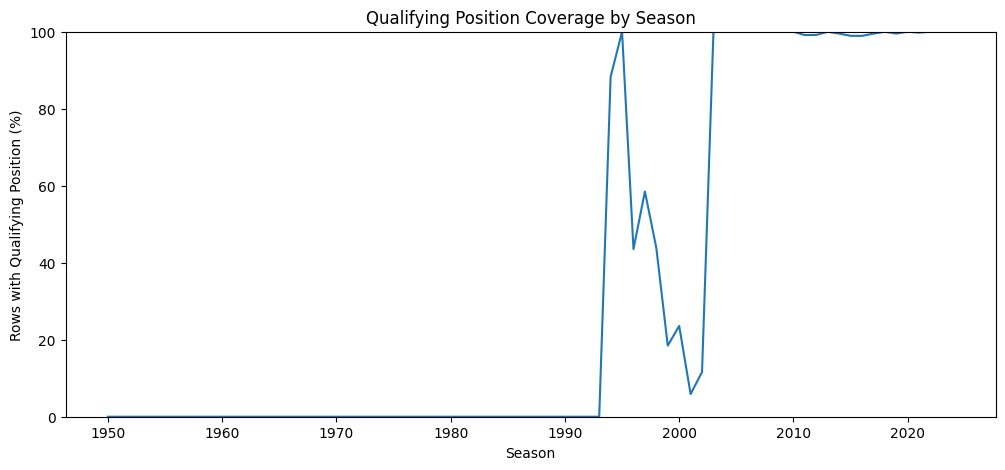

In [387]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=qualifying_coverage_by_year,
    x='year',
    y='qualifying_coverage_percent'
)

plt.title('Qualifying Position Coverage by Season')
plt.xlabel('Season')
plt.ylabel('Rows with Qualifying Position (%)')
plt.ylim(0, 100)
plt.show()

In [388]:
qual_grid_compare = qualifying_coverage_df[
    qualifying_coverage_df['qualifying_position'].notna()
].copy()

qual_grid_compare['grid_equals_qualifying'] = (
    qual_grid_compare['grid'] == qual_grid_compare['qualifying_position']
).astype(int)

grid_qual_match_summary = (
    qual_grid_compare
    .groupby('year')
    .agg(
        rows_with_both=('driverId', 'size'),
        matching_grid_and_qualifying=('grid_equals_qualifying', 'sum'),
        match_rate=('grid_equals_qualifying', 'mean')
    )
    .reset_index()
)

grid_qual_match_summary['match_rate_percent'] = (
    grid_qual_match_summary['match_rate'] * 100
)

grid_qual_match_summary.tail()

,year,rows_with_both,matching_grid_and_qualifying,match_rate,match_rate_percent
26,2020,340,279,0.820588,82.058824
27,2021,439,280,0.637813,63.781321
28,2022,440,274,0.622727,62.272727
29,2023,440,317,0.720455,72.045455
30,2024,479,363,0.757829,75.782881


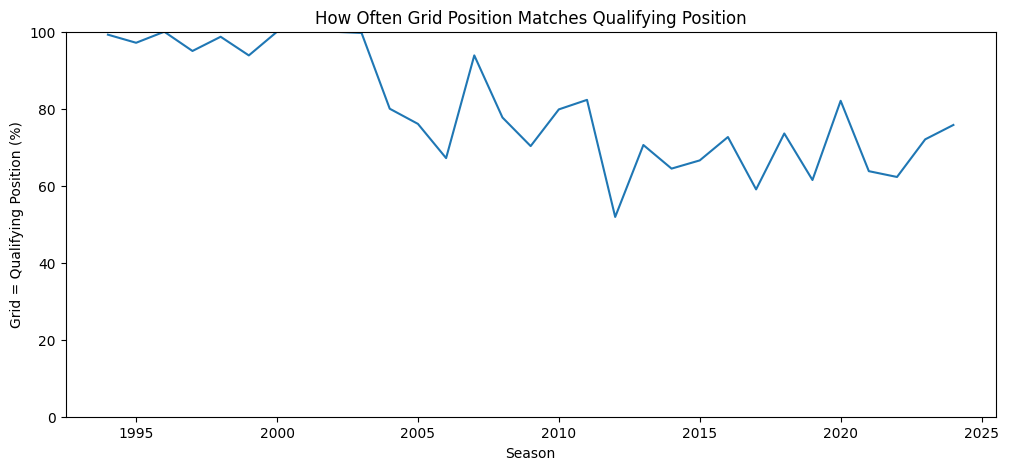

In [389]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=grid_qual_match_summary,
    x='year',
    y='match_rate_percent'
)

plt.title('How Often Grid Position Matches Qualifying Position')
plt.xlabel('Season')
plt.ylabel('Grid = Qualifying Position (%)')
plt.ylim(0, 100)
plt.show()

### Qualifying Coverage and Grid Comparison Summary

Qualifying information is valid pre-race information, but its availability is not consistent across Formula 1 history. Therefore, qualifying coverage was checked before deciding how to use qualifying features in the model.

The qualifying table was joined to the modeling table using `(raceId, driverId)`, and a coverage flag was created to show whether each driver-race row has a qualifying position. Coverage was then calculated by season and plotted over time.

A second check compared qualifying position with actual starting grid position. This is important because qualifying position and grid position do not always match. Grid penalties, pit-lane starts, exclusions, and other race-weekend decisions can change the actual starting grid after qualifying.

This confirms that `grid` and `qualifying_position` should be treated as separate variables. For questions or features involving actual race starts, `grid` is the correct variable. For features involving qualifying performance, `qualifying_position` can be used when available, but missingness must be handled carefully.

### Qualifying Coverage and Grid Comparison Interpretation

The qualifying coverage analysis shows that qualifying position data is not available consistently across Formula 1 history. Early seasons such as 1950–1954 have 0% qualifying-position coverage, while modern seasons such as 2020–2024 have almost complete coverage.

This confirms that qualifying information is historically patchy and should not be used blindly across the full dataset without handling missing values. If qualifying position is used as a model feature, the missingness must be handled carefully, for example by adding a missingness flag or limiting its use to periods where coverage is reliable.

The comparison between qualifying position and starting grid position also shows that these columns do not match perfectly. In recent years, the match rate ranges from approximately 62% to 82%, meaning that qualifying position and grid position are often different. This happens because penalties, pit-lane starts, and other race-weekend decisions can change the final starting grid.

Therefore, `grid` and `qualifying_position` should be treated as separate variables. `grid` represents the actual starting position and is appropriate for front-row-start analysis, while `qualifying_position` represents qualifying performance and may be useful as a separate pre-race feature when available.

In [390]:
# Remove columns from an earlier qualifying merge, if present
model_df = model_df.drop(
    columns=[
        'position_y',
        'qualifying_position',
        'qualifying_position_filled',
        'has_qualifying_position'
    ],
    errors='ignore'
)

# Restore the original results position column if pandas renamed it
if 'position_x' in model_df.columns:
    model_df = model_df.rename(columns={
        'position_x': 'position'
    })

# Rename qualifying position BEFORE merging
qualifying_features = qualifying[
    ['raceId', 'driverId', 'position']
].rename(columns={
    'position': 'qualifying_position'
})

# Join qualifying data
model_df = model_df.merge(
    qualifying_features,
    on=['raceId', 'driverId'],
    how='left',
    validate='many_to_one'
)

# Create qualifying availability flag
model_df['has_qualifying_position'] = (
    model_df['qualifying_position'].notna()
).astype(int)

# Fill missing qualifying position using grid
model_df['qualifying_position_filled'] = (
    model_df['qualifying_position'].fillna(model_df['grid'])
)

# Verify the output
display(model_df[[
    'year',
    'driverId',
    'grid',
    'qualifying_position',
    'has_qualifying_position',
    'qualifying_position_filled'
]].head())

,year,driverId,grid,qualifying_position,has_qualifying_position,qualifying_position_filled
0,2009,1,18,15.0,1,15.0
1,2009,2,9,11.0,1,11.0
2,2009,3,5,5.0,1,5.0
3,2009,4,10,12.0,1,12.0
4,2009,5,12,14.0,1,14.0


In [391]:
model_df[[
    'grid',
    'qualifying_position',
    'has_qualifying_position',
    'qualifying_position_filled'
]].isna().sum()

grid                              0
qualifying_position           16174
has_qualifying_position           0
qualifying_position_filled        0
dtype: int64

### Qualifying Feature Engineering Summary

Qualifying position was added to the modeling table as a pre-race feature. Because qualifying data is missing for many historical seasons, a missingness flag called `has_qualifying_position` was created.

A filled version of the feature, `qualifying_position_filled`, was also created. When qualifying position is available, it uses the recorded qualifying position. When qualifying position is missing, it falls back to the `grid` value.

This approach keeps the feature usable across the full historical dataset while preserving information about whether the original qualifying value was available. The fallback is a practical approximation, not a perfect reconstruction, because qualifying position and grid position can differ due to penalties and other race-weekend decisions.

### Qualifying Feature Missing-Value Check

The missing-value check confirmed that raw `qualifying_position` has many missing values because qualifying records are not available consistently across the full historical dataset.

However, the engineered features are complete:

- `has_qualifying_position` has no missing values and records whether qualifying data was originally available.
- `qualifying_position_filled` has no missing values because missing qualifying positions were filled using the available `grid` value.

Therefore, the model can use `qualifying_position_filled` together with `has_qualifying_position`. This preserves the useful information from qualifying data while avoiding row deletion caused by historical missingness.

In [392]:
model_df = model_df.sort_values(['date', 'raceId', 'driverId']).copy()

model_df[['date', 'raceId', 'year', 'driverId', 'constructorId', 'podium', 'positionOrder']].head()

,date,raceId,year,driverId,constructorId,podium,positionOrder
20532,1950-05-13,833,1950,579,51,0,12
20533,1950-05-13,833,1950,589,105,0,18
20534,1950-05-13,833,1950,619,151,0,6
20535,1950-05-13,833,1950,627,154,0,5
20536,1950-05-13,833,1950,640,105,0,17


In [393]:
model_df['driver_race_count_before'] = (
    model_df
    .groupby('driverId')
    .cumcount()
)

model_df['driver_past_podiums'] = (
    model_df
    .groupby('driverId')['podium']
    .transform(lambda x: x.cumsum().shift(1))
    .fillna(0)
)

model_df['driver_past_podium_rate'] = np.where(
    model_df['driver_race_count_before'] > 0,
    model_df['driver_past_podiums'] / model_df['driver_race_count_before'],
    0
)

model_df[[
    'year',
    'driverId',
    'podium',
    'driver_race_count_before',
    'driver_past_podiums',
    'driver_past_podium_rate'
]].head(20)

,year,driverId,podium,driver_race_count_before,driver_past_podiums,driver_past_podium_rate
20532,1950,579,0,0,0.0,0.0
20533,1950,589,0,0,0.0,0.0
20534,1950,619,0,0,0.0,0.0
20535,1950,627,0,0,0.0,0.0
20536,1950,640,0,0,0.0,0.0
20537,1950,642,1,0,0.0,0.0
20538,1950,660,0,0,0.0,0.0
20539,1950,661,0,0,0.0,0.0
20540,1950,666,0,0,0.0,0.0
20541,1950,669,0,0,0.0,0.0


In [394]:
model_df['constructor_race_count_before'] = (
    model_df
    .groupby('constructorId')
    .cumcount()
)

model_df['constructor_past_podiums'] = (
    model_df
    .groupby('constructorId')['podium']
    .transform(lambda x: x.cumsum().shift(1))
    .fillna(0)
)

model_df['constructor_past_podium_rate'] = np.where(
    model_df['constructor_race_count_before'] > 0,
    model_df['constructor_past_podiums'] / model_df['constructor_race_count_before'],
    0
)

model_df[[
    'year',
    'constructorId',
    'constructor_name',
    'podium',
    'constructor_race_count_before',
    'constructor_past_podiums',
    'constructor_past_podium_rate'
]].head(20)

,year,constructorId,constructor_name,podium,constructor_race_count_before,constructor_past_podiums,constructor_past_podium_rate
20532,1950,51,Alfa Romeo,0,0,0.0,0.000000
20533,1950,105,Maserati,0,0,0.0,0.000000
20534,1950,151,ERA,0,0,0.0,0.000000
20535,1950,154,Talbot-Lago,0,0,0.0,0.000000
20536,1950,105,Maserati,0,1,0.0,0.000000
20537,1950,51,Alfa Romeo,1,1,0.0,0.000000
20538,1950,154,Talbot-Lago,0,1,0.0,0.000000
20539,1950,151,ERA,0,1,0.0,0.000000
20540,1950,151,ERA,0,2,0.0,0.000000
20541,1950,105,Maserati,0,2,0.0,0.000000


In [395]:
model_df[[
    'driver_race_count_before',
    'driver_past_podiums',
    'driver_past_podium_rate',
    'constructor_race_count_before',
    'constructor_past_podiums',
    'constructor_past_podium_rate'
]].isna().sum()

driver_race_count_before         0
driver_past_podiums              0
driver_past_podium_rate          0
constructor_race_count_before    0
constructor_past_podiums         0
constructor_past_podium_rate     0
dtype: int64

### Past-Performance Feature Engineering Summary

Driver and constructor past-performance features were created using only races that occurred before the current race.

For each driver, the number of previous race entries, previous podiums, and previous podium rate were calculated. For each constructor, the same type of features were calculated at constructor level.

To avoid data leakage, cumulative values were shifted by one race within each driver or constructor group. This ensures that the current race result is not included in the feature value for that same race.

The missing-value check confirmed that all engineered past-performance features contain no missing values, so they can be safely used in the modeling phase.

In [396]:
model_df['driver_recent_podium_rate_5'] = (
    model_df
    .groupby('driverId')['podium']
    .transform(lambda x: x.shift(1).rolling(window=5, min_periods=1).mean())
    .fillna(0)
)

model_df[[
    'year',
    'driverId',
    'podium',
    'driver_recent_podium_rate_5'
]].head(20)

,year,driverId,podium,driver_recent_podium_rate_5
20532,1950,579,0,0.0
20533,1950,589,0,0.0
20534,1950,619,0,0.0
20535,1950,627,0,0.0
20536,1950,640,0,0.0
20537,1950,642,1,0.0
20538,1950,660,0,0.0
20539,1950,661,0,0.0
20540,1950,666,0,0.0
20541,1950,669,0,0.0


In [397]:
model_df['constructor_recent_podium_rate_5'] = (
    model_df
    .groupby('constructorId')['podium']
    .transform(lambda x: x.shift(1).rolling(window=5, min_periods=1).mean())
    .fillna(0)
)

model_df[[
    'year',
    'constructorId',
    'constructor_name',
    'podium',
    'constructor_recent_podium_rate_5'
]].head(20)

,year,constructorId,constructor_name,podium,constructor_recent_podium_rate_5
20532,1950,51,Alfa Romeo,0,0.000000
20533,1950,105,Maserati,0,0.000000
20534,1950,151,ERA,0,0.000000
20535,1950,154,Talbot-Lago,0,0.000000
20536,1950,105,Maserati,0,0.000000
20537,1950,51,Alfa Romeo,1,0.000000
20538,1950,154,Talbot-Lago,0,0.000000
20539,1950,151,ERA,0,0.000000
20540,1950,151,ERA,0,0.000000
20541,1950,105,Maserati,0,0.000000


In [398]:
model_df[[
    'driver_recent_podium_rate_5',
    'constructor_recent_podium_rate_5'
]].isna().sum()

driver_recent_podium_rate_5         0
constructor_recent_podium_rate_5    0
dtype: int64

In [399]:
feature_check_cols = [
    'grid',
    'front_row_start',
    'qualifying_position_filled',
    'has_qualifying_position',
    'driver_past_podium_rate',
    'constructor_past_podium_rate',
    'driver_recent_podium_rate_5',
    'constructor_recent_podium_rate_5',
    'podium'
]

model_df[feature_check_cols].corr()['podium'].sort_values(ascending=False)

podium                              1.000000
driver_recent_podium_rate_5         0.475350
front_row_start                     0.430242
constructor_recent_podium_rate_5    0.424116
driver_past_podium_rate             0.404323
constructor_past_podium_rate        0.370256
has_qualifying_position             0.033633
grid                               -0.364845
qualifying_position_filled         -0.369654
Name: podium, dtype: float64

### Feature Relationship Check

A correlation check was performed between the engineered numeric features and the target variable `podium`.

The strongest positive relationship was found for `driver_recent_podium_rate_5`, followed by `front_row_start`, `constructor_recent_podium_rate_5`, `driver_past_podium_rate`, and `constructor_past_podium_rate`. This suggests that both recent form and historical performance are useful predictors of podium finishes.

The variables `grid` and `qualifying_position_filled` have negative correlations with `podium`. This is expected because lower numerical positions are better in Formula 1. For example, grid position 1 is better than grid position 10, so as the grid number increases, podium likelihood generally decreases.

The `has_qualifying_position` feature has a weak direct correlation with the target, but it is still useful as a missingness indicator because qualifying coverage is inconsistent across historical seasons.

In [400]:
training_windows = {
    'Full history (1950-2018)': (1950, 2018),
    'Modern qualifying (2006-2018)': (2006, 2018),
    'Turbo-hybrid (2014-2018)': (2014, 2018)
}

window_summary = []

for name, (start_year, end_year) in training_windows.items():
    subset = model_df[
        model_df['year'].between(start_year, end_year)
    ]

    window_summary.append({
        'training_window': name,
        'total_rows': len(subset),
        'podium_rows': subset['podium'].sum(),
        'podium_rate_percent': subset['podium'].mean() * 100,
        'qualifying_coverage_percent':
            subset['has_qualifying_position'].mean() * 100
    })

window_summary = pd.DataFrame(window_summary)

window_summary

,training_window,total_rows,podium_rows,podium_rate_percent,qualifying_coverage_percent
0,Full history (1950-2018),24109,3011,12.489112,32.925464
1,Modern qualifying (2006-2018),5355,741,13.837535,99.607843
2,Turbo-hybrid (2014-2018),2067,300,14.513788,99.371069


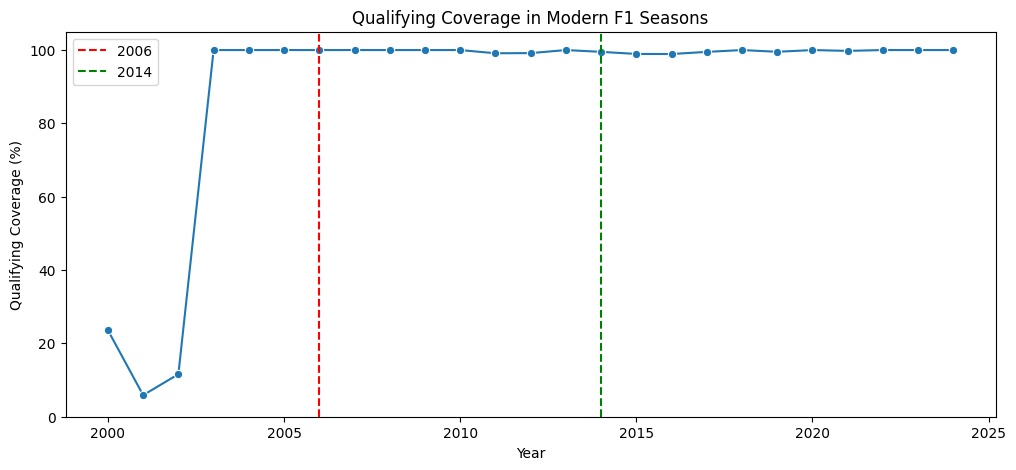

In [401]:
modern_coverage = qualifying_coverage_by_year[
    qualifying_coverage_by_year['year'] >= 2000
]

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=modern_coverage,
    x='year',
    y='qualifying_coverage_percent',
    marker='o'
)

plt.axvline(2006, linestyle='--', color='red', label='2006')
plt.axvline(2014, linestyle='--', color='green', label='2014')

plt.title('Qualifying Coverage in Modern F1 Seasons')
plt.xlabel('Year')
plt.ylabel('Qualifying Coverage (%)')
plt.ylim(0, 105)
plt.legend()
plt.show()

## Historical Modeling Dataset (1950–2024)

The modeling dataset is constructed using all available Formula 1 seasons from 1950 through 2024.

Each observation represents a driver participating in a particular race. The binary target variable, `podium`, indicates whether the driver finished among the top three classified positions.

Using the complete historical period satisfies the requirement to include earlier seasons. However, Formula 1 regulations, qualifying procedures, and team competitiveness have changed over time. These changes will be considered during exploratory analysis and model evaluation.

Only information available before the race is eligible for use as a predictor.

In [402]:
modern_df = model_df[
    model_df['year'].between(1950, 2024)
].copy()

modern_df = modern_df.sort_values(
    ['date', 'raceId', 'driverId']
).reset_index(drop=True)

print("Dataset shape:", modern_df.shape)
print("Year range:", modern_df['year'].min(), modern_df['year'].max())
print("Duplicate driver-race pairs:",
      modern_df.duplicated(['raceId', 'driverId']).sum())

print("\nPodium distribution:")
print(modern_df['podium'].value_counts())

assert modern_df.duplicated(['raceId', 'driverId']).sum() == 0

Dataset shape: (26668, 52)
Year range: 1950 2024
Duplicate driver-race pairs: 0

Podium distribution:
podium
0    23273
1     3395
Name: count, dtype: int64


## Starting Grid and Podium Relationship

Starting grid position is evaluated as a potential predictor of podium finishes.

The analysis calculates the number of observations, number of podium finishes, and podium rate for each starting position.

Because `grid = 0` represents a nonstandard grid designation rather than pole position, it is displayed separately and will receive special treatment during preprocessing.

,grid,observations,podiums,podium_rate,podium_rate_pct
0,0,1635,0,0.00,0.00
1,1,1124,721,0.64,64.15
2,2,1119,626,0.56,55.94
3,3,1127,523,0.46,46.41
4,4,1128,386,0.34,34.22
5,5,1121,281,0.25,25.07
6,6,1120,209,0.19,18.66
7,7,1132,147,0.13,12.99
8,8,1122,112,0.10,9.98
9,9,1132,94,0.08,8.30


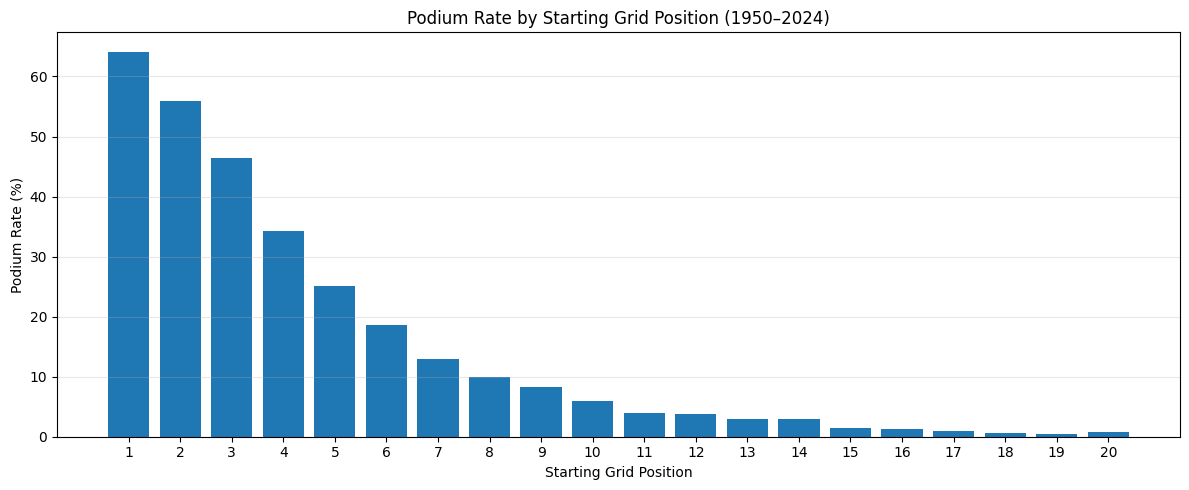

,count,mean
front_row_start,,
0,24425,0.083849
1,2243,0.600535


In [403]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

grid_summary = (
    modern_df.groupby('grid')
    .agg(
        observations=('podium', 'size'),
        podiums=('podium', 'sum'),
        podium_rate=('podium', 'mean')
    )
    .reset_index()
)

grid_summary['podium_rate_pct'] = (
    grid_summary['podium_rate'] * 100
)

display(grid_summary.round(2))

grid_plot = grid_summary[
    grid_summary['grid'].between(1, 20)
]

plt.figure(figsize=(12, 5))
plt.bar(
    grid_plot['grid'],
    grid_plot['podium_rate_pct']
)
plt.xlabel('Starting Grid Position')
plt.ylabel('Podium Rate (%)')
plt.title('Podium Rate by Starting Grid Position (1950–2024)')
plt.xticks(grid_plot['grid'])
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

modern_df['front_row_start'] = (
    modern_df['grid'].isin([1, 2]).astype(int)
)

display(
    modern_df.groupby('front_row_start')['podium']
    .agg(['count', 'mean'])
)

## Qualifying Position Availability and Relationship with Starting Grid

Qualifying position is investigated as a potential predictor of podium outcomes.

The qualifying dataset is merged using the combination of `raceId` and `driverId`.

Because the historical qualifying records are not equally available across all seasons, qualifying coverage is evaluated by year before deciding whether this feature should be included in the final model.

The relationship between qualifying position and starting grid position is examined using Pearson correlation and exact-position agreement. These are distinct measurements and should not be interpreted interchangeably.

Total observations: 26668
Missing qualifying positions: 16174
Qualifying coverage (%): 39.35


,year,observations,available,coverage_pct
0,1950,156,0,0.00
1,1951,175,0,0.00
2,1952,212,0,0.00
3,1953,230,0,0.00
4,1954,213,0,0.00
...,...,...,...,...
70,2020,340,340,100.00
71,2021,440,439,99.77
72,2022,440,440,100.00
73,2023,440,440,100.00


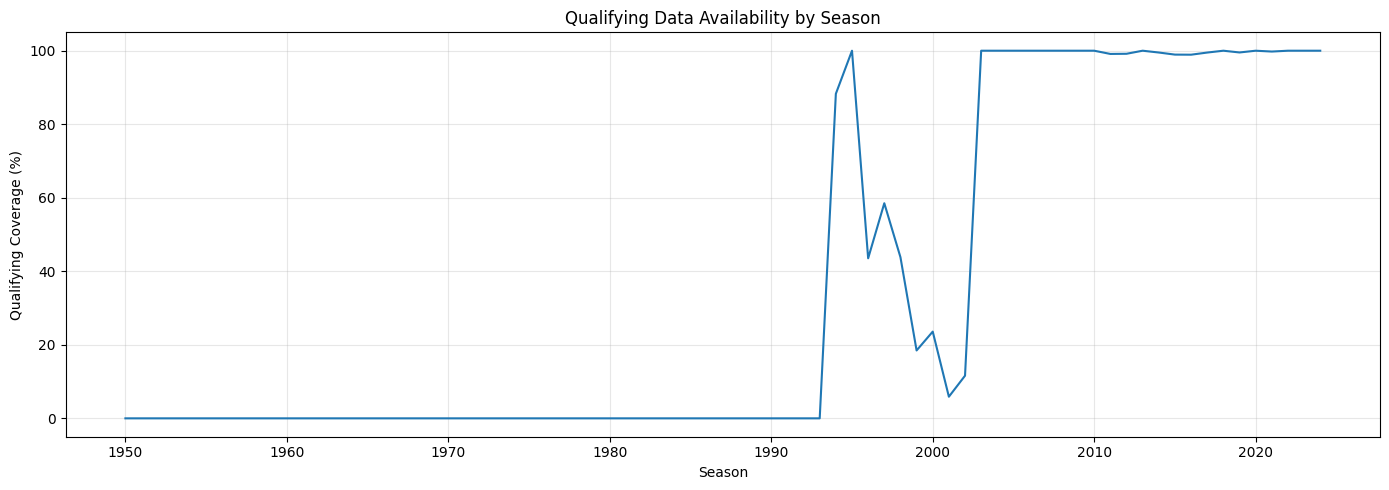

In [404]:
qualifying_features = qualifying[
    ['raceId', 'driverId', 'position']
].rename(columns={
    'position': 'qualifying_position'
})

# Make the merge safe to rerun
modern_df = modern_df.drop(
    columns=[
        'qualifying_position',
        'qualifying_position_x',
        'qualifying_position_y'
    ],
    errors='ignore'
)

modern_df = modern_df.merge(
    qualifying_features,
    on=['raceId', 'driverId'],
    how='left',
    validate='many_to_one'
)

print("Total observations:", len(modern_df))
print("Missing qualifying positions:",
      modern_df['qualifying_position'].isna().sum())
print("Qualifying coverage (%):",
      round(modern_df['qualifying_position'].notna().mean() * 100, 2))

qualifying_coverage = (
    modern_df.groupby('year')['qualifying_position']
    .agg(
        observations='size',
        available='count'
    )
    .reset_index()
)

qualifying_coverage['coverage_pct'] = (
    qualifying_coverage['available']
    / qualifying_coverage['observations'] * 100
)

display(qualifying_coverage.round(2))

plt.figure(figsize=(14, 5))
plt.plot(
    qualifying_coverage['year'],
    qualifying_coverage['coverage_pct']
)
plt.xlabel('Season')
plt.ylabel('Qualifying Coverage (%)')
plt.title('Qualifying Data Availability by Season')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 1. Historical Dataset Selection and Modeling Scope

### Objective

The objective of this project is to predict whether a Formula 1 driver will finish on the podium (top three) using information available after qualifying and before the race begins.

The prediction task is formulated as a binary classification problem:

- **1 — Podium:** The driver finishes among the top three classified positions.
- **0 — Non-podium:** The driver does not finish among the top three classified positions.

Each observation represents one driver participating in one race.

### Historical Data Selection

The modeling dataset includes Formula 1 seasons from **1950 through 2024**, retaining the full historical coverage available in the cleaned dataset.

Using the complete historical period increases the number of training observations and exposes the model to a wider variety of race conditions, drivers, and constructors.

However, Formula 1 has experienced substantial changes over time, including modifications to technical regulations, qualifying formats, race procedures, and team competitiveness. Consequently, historical relationships may not remain equally relevant across all seasons.

This creates a potential **concept drift** challenge, where relationships between predictor variables and podium outcomes change over time.

Rather than excluding older seasons, the project retains the full historical dataset and evaluates whether the selected features can generalize to later races.

### Data Integrity

Before proceeding, the modeling dataset is checked for:

- Total observations and feature dimensions.
- Historical year coverage.
- Duplicate driver-race observations.
- Podium and non-podium class distribution.

These checks establish the dataset's suitability for subsequent exploratory analysis, feature engineering, and chronological model evaluation.

In [405]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Use all available seasons from 1950 to 2024
modern_df = model_df[
    model_df['year'].between(1950, 2024)
].copy()

# Sort chronologically for subsequent historical analysis
modern_df = modern_df.sort_values(
    ['date', 'raceId', 'driverId']
).reset_index(drop=True)

print("Dataset shape:", modern_df.shape)

print(
    "Year range:",
    modern_df['year'].min(),
    "-",
    modern_df['year'].max()
)

print(
    "Unique races:",
    modern_df['raceId'].nunique()
)

print(
    "Unique drivers:",
    modern_df['driverId'].nunique()
)

print(
    "Unique constructors:",
    modern_df['constructorId'].nunique()
)

print(
    "Duplicate driver-race pairs:",
    modern_df.duplicated(
        ['raceId', 'driverId']
    ).sum()
)

print("\nPodium distribution:")
print(modern_df['podium'].value_counts())

print("\nPodium percentage distribution:")
print(
    (
        modern_df['podium']
        .value_counts(normalize=True) * 100
    ).round(2)
)

# Validation
assert modern_df['year'].min() == 1950
assert modern_df['year'].max() == 2024

assert not modern_df.duplicated(
    ['raceId', 'driverId']
).any()

assert modern_df['podium'].isin([0, 1]).all()

print("\nHistorical dataset validation passed!")

Dataset shape: (26668, 52)
Year range: 1950 - 2024
Unique races: 1125
Unique drivers: 861
Unique constructors: 210
Duplicate driver-race pairs: 0

Podium distribution:
podium
0    23273
1     3395
Name: count, dtype: int64

Podium percentage distribution:
podium
0    87.27
1    12.73
Name: proportion, dtype: float64

Historical dataset validation passed!


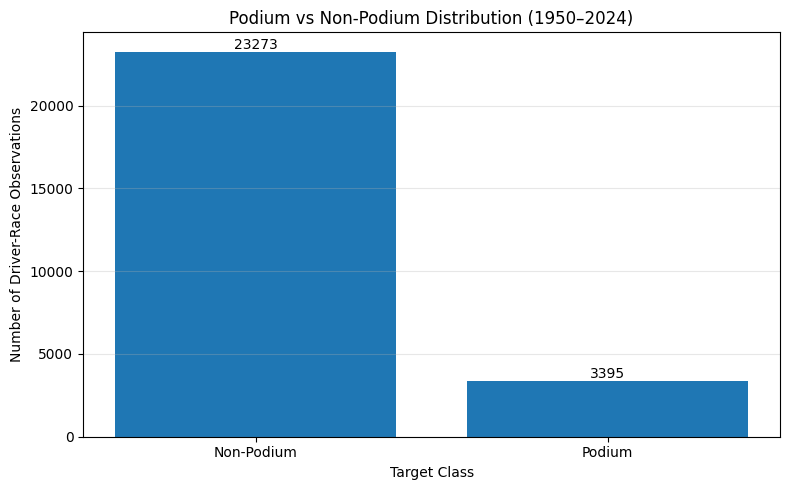

In [406]:
podium_counts = (
    modern_df['podium']
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

plt.figure(figsize=(8, 5))

bars = plt.bar(
    ['Non-Podium', 'Podium'],
    podium_counts.values
)

plt.title('Podium vs Non-Podium Distribution (1950–2024)')
plt.xlabel('Target Class')
plt.ylabel('Number of Driver-Race Observations')
plt.grid(axis='y', alpha=0.3)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(int(bar.get_height())),
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

### Results and Interpretation — Historical Dataset Validation

The final historical modeling dataset contains **26,668 driver-race observations and 52 columns**, covering the complete period from **1950 to 2024**.

The dataset includes:

- **1,125 unique races**
- **861 unique drivers**
- **210 unique constructors**

No duplicate combinations of `raceId` and `driverId` were detected. This confirms that each driver-race pair appears only once, preventing duplicate observations from affecting subsequent analysis.

#### Target Class Distribution

The target variable is imbalanced:

- **Non-podium (0):** 23,273 observations (87.27%)
- **Podium (1):** 3,395 observations (12.73%)

This means that podium finishes represent a minority of the observations.

A classifier that always predicts the majority class (non-podium) would achieve approximately **87.27% accuracy**, despite failing to identify any podium finishes.

Consequently, accuracy alone would provide a misleading assessment of model performance.

The project will therefore evaluate models using **precision, recall, F1-score, ROC-AUC, and PR-AUC**, in addition to accuracy.

PR-AUC is particularly relevant because it evaluates the relationship between precision and recall for the minority podium class.

#### Conclusion

The historical dataset passes the initial integrity checks and is suitable

## 2. Exploratory Data Analysis — Starting Grid Position

### Objective

Starting grid position is investigated as a candidate predictor of podium finishes.

Grid position is known before the race begins and therefore satisfies the prediction cutoff requirement.

A driver's starting position may influence podium probability because drivers starting near the front generally have fewer competitors ahead of them. However, the relationship must be evaluated empirically rather than assumed.

### Analysis Method

The following analyses are performed:

1. Calculate the number of observations and podium finishes for each starting grid position.
2. Calculate the podium rate for each grid position.
3. Visualize podium probability across starting positions.
4. Compare podium rates for front-row starters against other drivers.
5. Examine whether the grid-position relationship changes across historical periods.

The feature `front_row_start` is introduced as a binary indicator:

- **1:** Driver starts from grid position 1 or 2.
- **0:** Driver starts from any other position.

The value `grid = 0` is treated separately because it does not represent a conventional starting position.

### Expected Contribution to Feature Selection

If grid position and front-row status demonstrate a meaningful association with podium outcomes, they will be retained as candidate predictors.

Historical-period comparisons will help assess whether the relationship is reasonably stable across the full dataset.

These analyses are descriptive and do not establish causation. Final predictive usefulness will be assessed using chronological validation data.

Podium performance by starting grid position:


,grid,observations,podiums,podium_rate_pct
0,0,1635,0,0.00
1,1,1124,721,64.15
2,2,1119,626,55.94
3,3,1127,523,46.41
4,4,1128,386,34.22
5,5,1121,281,25.07
6,6,1120,209,18.66
7,7,1132,147,12.99
8,8,1122,112,9.98
9,9,1132,94,8.30


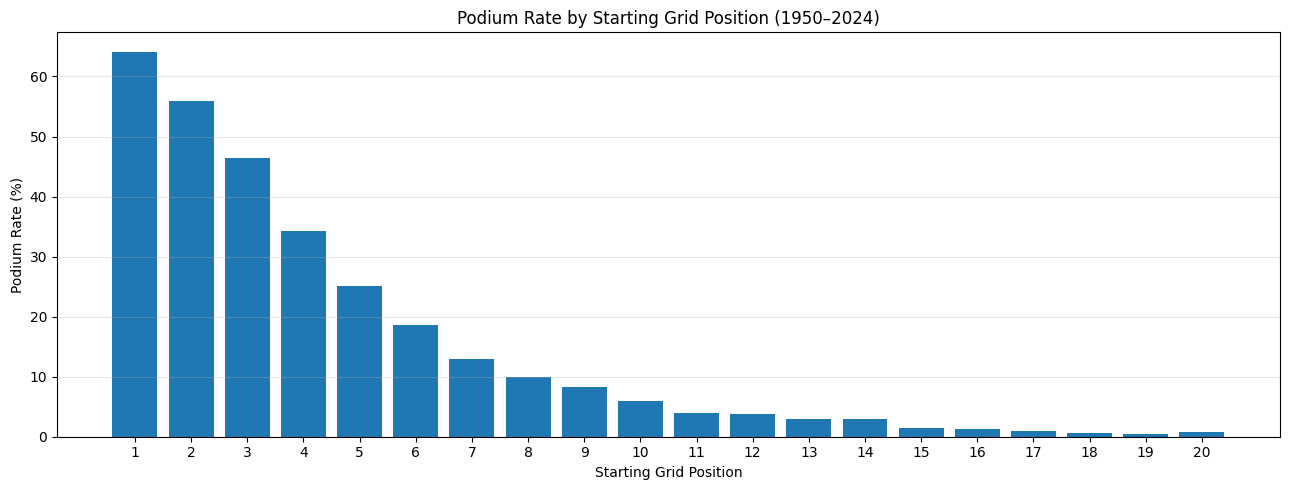

In [407]:
# Investigate starting grid position
grid_summary = (
    modern_df.groupby('grid')
    .agg(
        observations=('podium', 'size'),
        podiums=('podium', 'sum'),
        podium_rate=('podium', 'mean')
    )
    .reset_index()
    .sort_values('grid')
)

grid_summary['podium_rate_pct'] = (
    grid_summary['podium_rate'] * 100
)

print("Podium performance by starting grid position:")
display(
    grid_summary[
        ['grid', 'observations', 'podiums', 'podium_rate_pct']
    ].round(2)
)

# Plot conventional starting positions 1–20
grid_plot = grid_summary[
    grid_summary['grid'].between(1, 20)
]

plt.figure(figsize=(13, 5))

plt.bar(
    grid_plot['grid'],
    grid_plot['podium_rate_pct']
)

plt.xlabel('Starting Grid Position')
plt.ylabel('Podium Rate (%)')
plt.title('Podium Rate by Starting Grid Position (1950–2024)')
plt.xticks(range(1, 21))
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

Front-row starting advantage:


,observations,podiums,podium_rate,podium_rate_pct
front_row_start,,,,
0,24425,2048,0.08,8.38
1,2243,1347,0.60,60.05


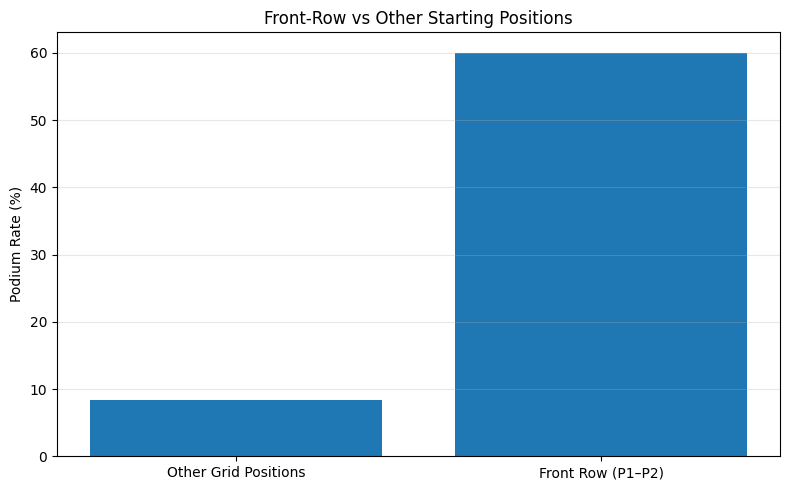

In [408]:
# Create a pre-race binary feature
modern_df['front_row_start'] = (
    modern_df['grid'].isin([1, 2]).astype(int)
)

front_row_summary = (
    modern_df.groupby('front_row_start')
    .agg(
        observations=('podium', 'size'),
        podiums=('podium', 'sum'),
        podium_rate=('podium', 'mean')
    )
)

front_row_summary['podium_rate_pct'] = (
    front_row_summary['podium_rate'] * 100
)

print("Front-row starting advantage:")
display(front_row_summary.round(2))

plt.figure(figsize=(8, 5))

plt.bar(
    ['Other Grid Positions', 'Front Row (P1–P2)'],
    front_row_summary['podium_rate_pct']
)

plt.ylabel('Podium Rate (%)')
plt.title('Front-Row vs Other Starting Positions')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

historical_period,1950–1979,1980–1999,2000–2019,2020–2024
grid,,,,
1,51.68,55.66,78.49,77.57
2,48.46,50.94,61.99,72.64
3,38.79,46.86,51.88,49.53
4,33.53,35.85,33.33,34.58
5,29.63,27.99,19.89,20.56
6,21.36,21.07,16.13,12.15
7,18.81,11.29,10.48,8.49
8,14.77,12.23,5.91,2.83
9,11.68,11.91,4.03,1.87


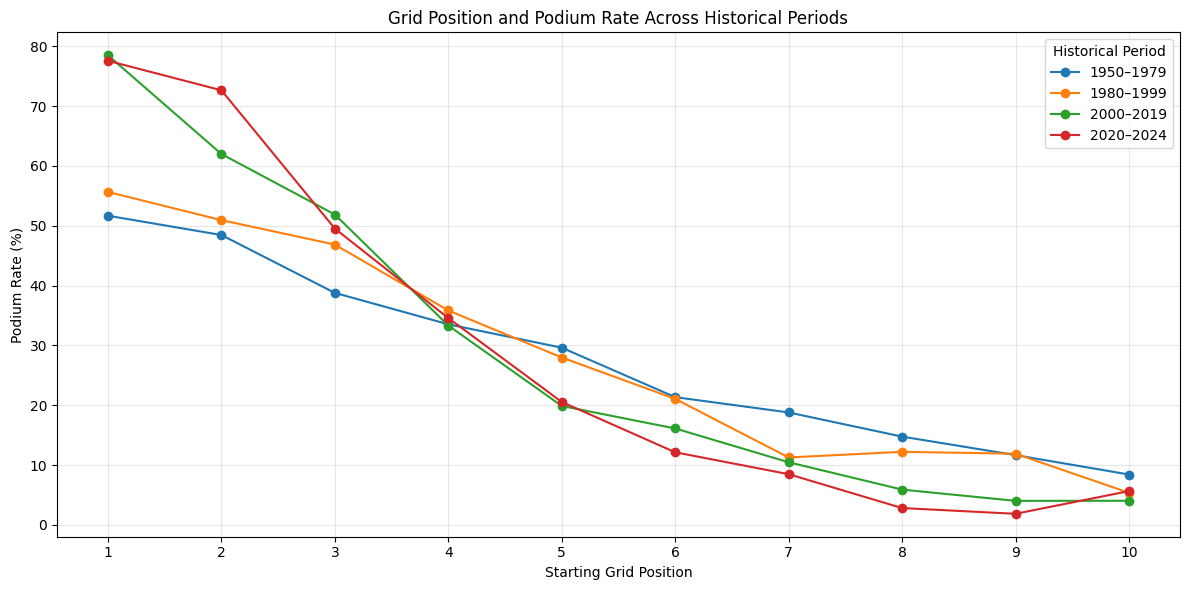

In [409]:
# Compare grid performance across historical periods
period_bins = [1949, 1979, 1999, 2019, 2024]

period_labels = [
    '1950–1979',
    '1980–1999',
    '2000–2019',
    '2020–2024'
]

modern_df['historical_period'] = pd.cut(
    modern_df['year'],
    bins=period_bins,
    labels=period_labels
)

# Use grid positions 1–10 for a readable comparison
period_grid = modern_df[
    modern_df['grid'].between(1, 10)
]

period_summary = (
    period_grid.groupby(
        ['historical_period', 'grid'],
        observed=True
    )['podium']
    .mean()
    .mul(100)
    .unstack(0)
)

display(period_summary.round(2))

plt.figure(figsize=(12, 6))

for period in period_summary.columns:
    plt.plot(
        period_summary.index,
        period_summary[period],
        marker='o',
        label=period
    )

plt.xlabel('Starting Grid Position')
plt.ylabel('Podium Rate (%)')
plt.title('Grid Position and Podium Rate Across Historical Periods')
plt.xticks(range(1, 11))
plt.legend(title='Historical Period')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 2.1 Results and Interpretation — Starting Grid Position

#### Relationship Between Starting Grid Position and Podium Probability

The analysis reveals a strong relationship between starting grid position and podium probability across the 1950–2024 dataset.

Drivers starting near the front of the grid have substantially higher podium rates than those starting further back.

The observed podium rates for the first ten starting positions are:

| Grid Position | Podium Rate |
|---|---|
| 1 | 64.15% |
| 2 | 55.94% |
| 3 | 46.41% |
| 4 | 34.22% |
| 5 | 25.07% |
| 6 | 18.66% |
| 7 | 12.99% |
| 8 | 9.98% |
| 9 | 8.30% |
| 10 | 5.87% |

The podium rate decreases substantially as starting grid position increases.

For example, drivers starting from pole position achieve a podium rate of **64.15%**, compared with only **5.87%** for drivers starting in tenth position.

This represents a difference of **58.28 percentage points**, demonstrating the strong predictive association between grid position and race outcome.

**Feature-selection decision:** Retain `grid` as a numerical predictor because it is available before the race and shows a clear relationship with podium probability.

#### Front-Row Starting Advantage

The engineered binary feature `front_row_start` identifies drivers starting in positions 1 or 2.

The results show:

- **Front-row starters:** 2,243 observations, 1,347 podium finishes, and a podium rate of **60.05%**.
- **Other starters:** 24,425 observations, 2,048 podium finishes, and a podium rate of **8.38%**.

Front-row starters therefore have a podium rate approximately **7.17 times higher** than other starters.

The difference of **51.67 percentage points** suggests that starting on the front row is strongly associated with podium outcomes.

Although `front_row_start` is derived from `grid` and therefore contains overlapping information, it explicitly represents the distinction between front-row and other starting positions.

**Feature-selection decision:** Retain `front_row_start` as a candidate engineered feature. Its incremental predictive value will be evaluated during feature-group ablation rather than assumed from the descriptive results alone.

#### Historical Changes in the Grid–Podium Relationship

The historical-period analysis reveals that the relationship between starting position and podium probability has changed over time.

For drivers starting from pole position:

- **1950–1979:** 51.68%
- **1980–1999:** 55.66%
- **2000–2019:** 78.49%
- **2020–2024:** 77.57%

Meanwhile, drivers starting from eighth position experienced the following podium rates:

- **1950–1979:** 14.77%
- **1980–1999:** 12.23%
- **2000–2019:** 5.91%
- **2020–2024:** 2.83%

These findings indicate that front-grid positions have become more strongly associated with podium finishes in recent periods, while drivers starting further back have generally experienced lower podium probabilities.

This is important because the model is trained using observations from substantially different Formula 1 eras.

The differences are consistent with the possibility of **concept drift**, where the relationship between an input feature and the target variable changes over time. However, the analysis alone does not establish which regulatory, technical, or competitive changes caused these differences.

#### Special Case — Grid Position Zero

The dataset contains **1,635 observations with `grid = 0`**, and none of these observations resulted in a podium finish.

Because grid position zero is not a conventional starting position, treating it as numerically better than pole position would introduce a misleading ordering.

Therefore, `grid = 0` will not be treated as a valid numerical starting position during preprocessing.

Instead, the project will investigate its meaning and historical distribution, then consider replacing zero with a missing value and adding a separate indicator.

This decision is important because grid position zero accounts for a substantial number of observations in the full historical dataset.

#### Conclusion

The analysis provides strong descriptive evidence for including starting grid position in the prediction model.

Both `grid` and `front_row_start` are retained as candidate features because they are available before the race and demonstrate substantial associations with podium outcomes.

The historical-period analysis also identifies differences in these relationships across eras, supporting the need for chronological validation rather than random splitting.

Final feature usefulness will be determined through model evaluation and ablation experiments.

## 3. Exploratory Data Analysis — Qualifying Position

### Objective

Qualifying position is investigated as a potential predictor of podium finishes.

Qualifying results are known before the race and may contain useful information about a driver's pace and competitiveness.

However, the historical qualifying dataset may not provide complete coverage across all Formula 1 seasons.

Before selecting this feature, the analysis evaluates:

1. Overall qualifying-position availability.
2. Qualifying coverage by season and historical period.
3. The relationship between qualifying position and starting grid position.
4. Whether qualifying position provides information distinct from starting grid position.

### Methodology

Qualifying information is merged with the modeling dataset using `raceId` and `driverId`.

The merge preserves every observation in the modeling dataset, including races without corresponding qualifying records.

Coverage is calculated as the percentage of driver-race observations with an available qualifying position.

The Pearson correlation coefficient is used to measure the linear association between qualifying and starting positions. Exact-position agreement is calculated separately.

### Feature-Selection Considerations

If qualifying information is unavailable for substantial historical periods, imputing these values may introduce artificial patterns that do not represent actual qualifying performance.

Furthermore, if qualifying position is highly correlated with starting grid position, including both features may provide limited additional information.

The final decision will consider historical availability, redundancy, and predictive value while maintaining the full 1950–2024 dataset.

In [410]:
# Select the qualifying columns needed for analysis
qualifying_features = qualifying[
    ['raceId', 'driverId', 'position']
].copy()

qualifying_features = qualifying_features.rename(
    columns={'position': 'qualifying_position'}
)

# Remove any previous qualifying-position columns
# to prevent duplicate suffixes when rerunning the cell
modern_df = modern_df.drop(
    columns=[
        'qualifying_position',
        'qualifying_position_x',
        'qualifying_position_y'
    ],
    errors='ignore'
)

# Merge without removing historical observations
modern_df = modern_df.merge(
    qualifying_features,
    on=['raceId', 'driverId'],
    how='left',
    validate='many_to_one'
)

# Ensure the merge preserved the dataset
assert len(modern_df) == 26668

print("Total observations:", len(modern_df))

print(
    "Available qualifying positions:",
    modern_df['qualifying_position'].notna().sum()
)

print(
    "Missing qualifying positions:",
    modern_df['qualifying_position'].isna().sum()
)

print(
    "Qualifying coverage (%):",
    round(
        modern_df['qualifying_position'].notna().mean() * 100,
        2
    )
)

Total observations: 26668
Available qualifying positions: 10494
Missing qualifying positions: 16174
Qualifying coverage (%): 39.35


,year,observations,qualifying_available,coverage_pct
0,1950,156,0,0.00
1,1951,175,0,0.00
2,1952,212,0,0.00
3,1953,230,0,0.00
4,1954,213,0,0.00
...,...,...,...,...
70,2020,340,340,100.00
71,2021,440,439,99.77
72,2022,440,440,100.00
73,2023,440,440,100.00


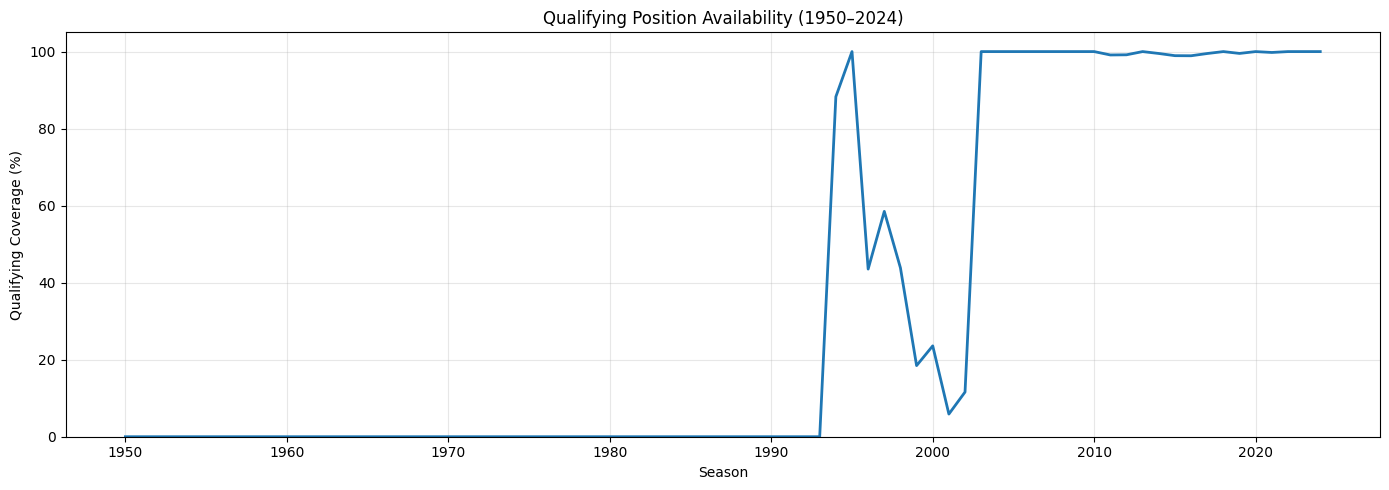

In [411]:
qualifying_coverage = (
    modern_df.groupby('year')
    .agg(
        observations=('driverId', 'size'),
        qualifying_available=('qualifying_position', 'count')
    )
    .reset_index()
)

qualifying_coverage['coverage_pct'] = (
    qualifying_coverage['qualifying_available']
    / qualifying_coverage['observations'] * 100
)

display(qualifying_coverage.round(2))

plt.figure(figsize=(14, 5))

plt.plot(
    qualifying_coverage['year'],
    qualifying_coverage['coverage_pct'],
    linewidth=2
)

plt.xlabel('Season')
plt.ylabel('Qualifying Coverage (%)')
plt.title('Qualifying Position Availability (1950–2024)')
plt.ylim(0, 105)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Observations with valid grid and qualifying positions: 10407
Pearson correlation: 0.9731
Exact position agreement (%): 76.73


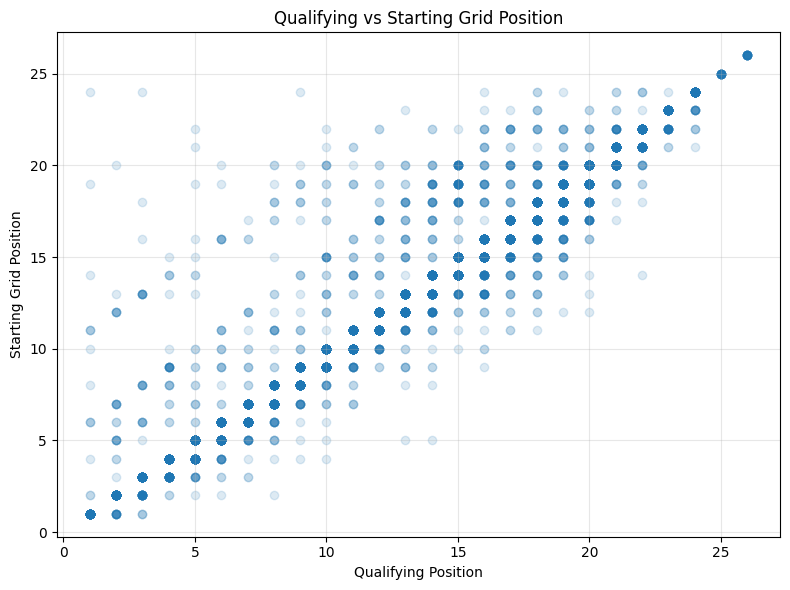

In [412]:
# Compare only observations with both values available
comparison_df = modern_df[
    ['grid', 'qualifying_position']
].dropna()

# Exclude grid = 0 from numerical position comparisons
comparison_df = comparison_df[
    comparison_df['grid'] > 0
]

print(
    "Observations with valid grid and qualifying positions:",
    len(comparison_df)
)

print(
    "Pearson correlation:",
    round(
        comparison_df['grid'].corr(
            comparison_df['qualifying_position']
        ),
        4
    )
)

print(
    "Exact position agreement (%):",
    round(
        (
            comparison_df['grid']
            == comparison_df['qualifying_position']
        ).mean() * 100,
        2
    )
)

plt.figure(figsize=(8, 6))

plt.scatter(
    comparison_df['qualifying_position'],
    comparison_df['grid'],
    alpha=0.15
)

plt.xlabel('Qualifying Position')
plt.ylabel('Starting Grid Position')
plt.title('Qualifying vs Starting Grid Position')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 3.1 Results and Interpretation — Qualifying Position

#### Historical Qualifying Data Availability

The full modeling dataset contains **26,668 driver-race observations** from 1950 through 2024.

After merging the qualifying dataset, the following results were obtained:

| Measurement | Result |
|---|---:|
| Total observations | 26,668 |
| Available qualifying positions | 10,494 |
| Missing qualifying positions | 16,174 |
| Qualifying coverage | 39.35% |
| Missing percentage | 60.65% |

Qualifying position is missing for more than half of the historical observations.

The yearly coverage analysis shows that the earliest seasons, including 1950–1954, have no qualifying-position records in the merged qualifying table.

In contrast, recent seasons have nearly complete coverage. For example, 2020, 2022, 2023, and 2024 each have 100% coverage, while 2021 has 99.77%.

This demonstrates that qualifying-position missingness is strongly associated with historical data availability rather than being uniformly distributed across seasons.

#### Why Median Imputation Is Not Appropriate for This Feature

Median imputation is commonly used to replace a limited number of missing numerical observations.

However, imputing 16,174 qualifying positions would replace **60.65% of the dataset's values** with artificial estimates.

In addition, missing qualifying information is concentrated in earlier historical periods. Replacing these missing values with a single median would not recover actual qualifying performance and could distort relationships between qualifying position, historical era, and podium outcomes.

Therefore, simple median imputation is not selected as the primary strategy for this feature.

#### Relationship Between Qualifying and Starting Grid Position

The comparison was restricted to **10,407 observations** with available qualifying positions and

## 4. Data Quality Investigation — Nonstandard Starting Grid Values

### Objective

The starting grid variable is a major candidate predictor of podium outcomes.

However, the dataset contains observations with `grid = 0`, which does not represent a conventional starting position.

These values require investigation before numerical preprocessing.

### Why This Matters

Treating grid position zero as an ordinary numerical value would incorrectly place it ahead of pole position (`grid = 1`).

Furthermore, all observations with `grid = 0` in the exploratory analysis were associated with non-podium outcomes.

This strong association requires careful interpretation because grid zero may reflect nonstandard starting arrangements or race-participation circumstances.

The analysis must determine whether the information represented by grid zero would have been known at the prediction cutoff.

### Investigation Method

The following checks are performed:

1. Count grid-zero observations and their percentage of the dataset.
2. Examine their distribution across seasons and historical periods.
3. Inspect their associated race-status descriptions.
4. Compare grid-zero observations with normal starting-grid observations.

The purpose is to determine whether grid zero should be treated as a missing numerical starting position, represented by a separate indicator, or handled using another justified strategy.

Race-status information is used **only for retrospective data-quality investigation**. It must not be included as a model predictor because final race status is determined during or after the race.

Grid-zero observations: 1635
Percentage of dataset: 6.13
Podium finishes among grid-zero observations: 0


,year,grid_zero_count
0,1952,12
1,1954,3
2,1955,7
3,1956,8
4,1957,5
...,...,...
57,2020,5
58,2021,12
59,2022,11
60,2023,18


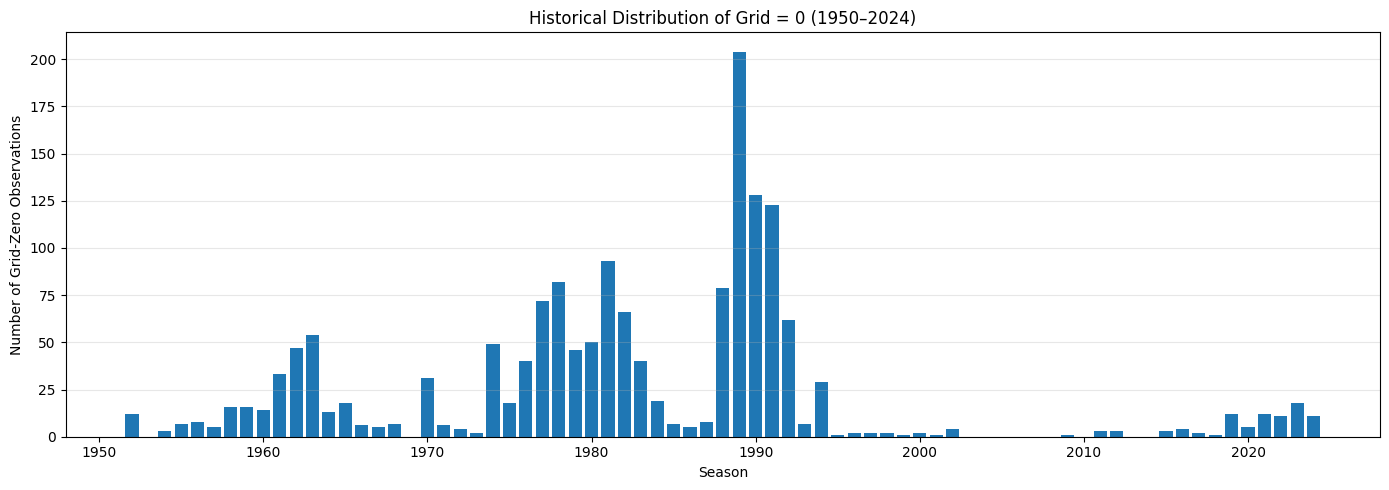


Grid-zero observations by historical period:


historical_period
1950–1979    614
1980–1999    928
2000–2019     36
2020–2024     57
Name: count, dtype: int64

In [413]:
grid_zero_df = modern_df[
    modern_df['grid'] == 0
].copy()

print("Grid-zero observations:", len(grid_zero_df))

print(
    "Percentage of dataset:",
    round(
        len(grid_zero_df) / len(modern_df) * 100,
        2
    )
)

print(
    "Podium finishes among grid-zero observations:",
    grid_zero_df['podium'].sum()
)

grid_zero_by_year = (
    grid_zero_df.groupby('year')
    .size()
    .reset_index(name='grid_zero_count')
)

display(grid_zero_by_year)

plt.figure(figsize=(14, 5))

plt.bar(
    grid_zero_by_year['year'],
    grid_zero_by_year['grid_zero_count']
)

plt.xlabel('Season')
plt.ylabel('Number of Grid-Zero Observations')
plt.title('Historical Distribution of Grid = 0 (1950–2024)')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print("\nGrid-zero observations by historical period:")
display(
    grid_zero_df['historical_period']
    .value_counts()
    .sort_index()
)

In [414]:
# Use cleaned driver-race observations rather than raw results
grid_zero_status = modern_df.loc[
    modern_df['grid'] == 0,
    ['raceId', 'driverId', 'year', 'grid', 'statusId']
].copy()

# Join status descriptions
grid_zero_status = grid_zero_status.merge(
    status[['statusId', 'status']],
    on='statusId',
    how='left',
    validate='many_to_one'
)

# Check that no observations were duplicated
assert len(grid_zero_status) == 1635

print("Grid-zero observations:", len(grid_zero_status))

status_summary = (
    grid_zero_status.groupby('status', dropna=False)
    .size()
    .reset_index(name='observations')
    .sort_values('observations', ascending=False)
)

status_summary['percentage'] = (
    status_summary['observations']
    / len(grid_zero_status) * 100
)

print("\nRace-status distribution for grid = 0:")
display(status_summary.round(2))

print("\nSample grid-zero observations:")
display(
    grid_zero_status[
        ['year', 'raceId', 'driverId', 'grid', 'status']
    ].head(15)
)

Grid-zero observations: 1635

Race-status distribution for grid = 0:


,status,observations,percentage
9,Did not qualify,1012,61.90
8,Did not prequalify,330,20.18
27,Withdrew,163,9.97
0,+1 Lap,27,1.65
14,Finished,22,1.35
3,Accident,20,1.22
19,Injury,8,0.49
1,+2 Laps,7,0.43
12,Excluded,6,0.37
11,Engine,6,0.37



Sample grid-zero observations:


,year,raceId,driverId,grid,status
0,1952,821,749,0,Withdrew
1,1952,824,581,0,Did not qualify
2,1952,824,640,0,Did not qualify
3,1952,824,651,0,Did not qualify
4,1952,824,660,0,Did not qualify
5,1952,824,687,0,Did not qualify
6,1952,824,717,0,Did not qualify
7,1952,824,735,0,Did not qualify
8,1952,824,738,0,Did not qualify
9,1952,824,749,0,Did not qualify


### 4.1 Results — Historical Distribution of Grid-Zero Observations

The analysis identified **1,635 observations with `grid = 0`**, representing **6.13% of the complete dataset**.

None of these observations resulted in a podium finish.

The historical distribution was:

| Historical Period | Grid-Zero Observations |
|---|---:|
| 1950–1979 | 614 |
| 1980–1999 | 928 |
| 2000–2019 | 36 |
| 2020–2024 | 57 |
| **Total** | **1,635** |

Approximately **94.31% of grid-zero observations occurred before 2000**.

This concentration indicates that the occurrence of nonstandard grid values differs substantially across historical periods.

Because zero does not represent a valid numerical starting position ahead of pole position, treating it as an ordinary grid value would introduce an incorrect numerical relationship.

However, the absence of podium finishes among grid-zero observations does not automatically justify using grid zero as a predictive indicator.

Its interpretation must first be investigated to determine whether it represents information available before the race or information related to race participation and final outcomes.

The associated race-status descriptions are therefore examined before selecting the final preprocessing strategy.

### 4.2 Results and Interpretation — Race Status and Grid-Zero Handling

#### Race-Status Distribution

The investigation identified **1,635 observations with `grid = 0`**, representing 6.13% of the full historical dataset.

The most frequent race-status categories were:

| Race Status | Observations | Percentage |
|---|---:|---:|
| Did not qualify | 1,012 | 61.90% |
| Did not prequalify | 330 | 20.18% |
| Withdrew | 163 | 9.97% |
| +1 Lap | 27 | 1.65% |
| Finished | 22 | 1.35% |
| Accident | 20 | 1.22% |

Together, **1,342 observations (82.08%)** correspond to drivers who did not qualify or did not prequalify.

This explains why grid-zero observations are fundamentally different from conventional starting positions.

However, the presence of statuses such as `Finished`, `+1 Lap`, and `Accident` demonstrates that grid zero does not exclusively represent drivers who failed to participate.

#### Implications for Feature Engineering

Treating `grid = 0` as a numerical position would incorrectly suggest that these drivers started ahead of pole position.

Additionally, all 1,635 grid-zero observations have a non-podium target. If the model uses this value without appropriate interpretation, it may learn a relationship driven partly by historical participation and eligibility records.

The race-status descriptions are useful for understanding the dataset but must not be used as predictors because they may contain information determined during or after the race.

#### Selected Preprocessing Strategy

For the initial full-history model, the following approach will be evaluated:

1. Preserve grid-zero observations rather than automatically removing them.
2. Create a binary indicator, `grid_zero_flag`, to identify nonstandard grid values.
3. Replace zero with a missing value in the numerical `grid` feature.
4. Impute missing numerical grid positions using the median calculated exclusively from the training dataset.

This prevents grid zero from being interpreted as a superior starting position while preserving the original observations.

The `grid_zero_flag` is only appropriate if the recorded grid designation was available at the prediction cutoff. Because the status analysis reveals mixed circumstances, this assumption must be acknowledged and checked.

A later ablation experiment should evaluate whether the grid-zero indicator materially changes validation performance.

#### Conclusion

The investigation demonstrates that grid-zero values require special handling.

The selected candidate strategy separates nonstandard grid records from ordinary numerical starting positions, preserves the full historical dataset, and avoids directly using post-race status information.

The effectiveness and suitability of this strategy will be evaluated during preprocessing and model validation.

## 5. Feature Engineering — Historical Driver Performance

### Objective

Starting grid position captures a driver's position before the race, but it does not directly represent the driver's previous Formula 1 experience or performance.

To capture these characteristics, historical driver-performance features are engineered using earlier race results.

### Engineered Features

**1. Driver Previous Races**

`driver_previous_races` represents the number of earlier race entries recorded for the driver.

This feature is used as an indicator of historical Formula 1 experience.

**2. Driver Past Podiums**

`driver_past_podiums` represents the number of podium finishes achieved in earlier races.

It captures cumulative historical success.

**3. Driver Historical Podium Rate**

`driver_past_podium_rate` is calculated as:

\[
\text{Historical Podium Rate} =
\frac{\text{Previous Podiums}}{\text{Previous Races}}
\]

For drivers with no previous races, the rate is initialized to zero.

This feature normalizes cumulative podium performance by the driver's previous race count.

**4. Driver Recent Podium Rate (Last Five Races)**

`driver_recent_podium_rate_5` measures the proportion of podium finishes across the driver's previous five recorded race entries.

This feature is intended to capture recent performance rather than relying exclusively on career-long statistics.

For drivers with fewer than five previous entries, the available earlier entries are used. Drivers without previous entries receive a value of zero.

### Preventing Target Leakage

The historical features must only use information that would have been available before the race being predicted.

Therefore:

1. Driver observations are ordered chronologically.
2. Cumulative podium statistics exclude the current race.
3. Recent podium rates use a one-race shift before applying the rolling window.
4. The engineered features are merged into the modeling dataset using driver and race identifiers.

The `shift(1)` operation is particularly important because it prevents the current race's podium outcome from contributing to its own historical features.

### Expected Predictive Value

Drivers with stronger historical podium records may have a higher probability of finishing on the podium again.

Recent podium performance may also provide useful information about current competitiveness.

However, these relationships are not assumed to be constant across historical periods. Their usefulness will be examined through exploratory analysis, chronological validation, and feature-group ablation.

In [415]:
# Start from the cleaned full historical dataset
driver_history = model_df[
    ['raceId', 'driverId', 'date', 'podium']
].copy()

# Ensure chronological ordering within each driver
driver_history = driver_history.sort_values(
    ['driverId', 'date', 'raceId']
).reset_index(drop=True)

driver_group = driver_history.groupby('driverId')

# 1. Number of previous race entries
driver_history['driver_previous_races'] = (
    driver_group.cumcount()
)

# 2. Number of previous podium finishes
driver_history['driver_past_podiums'] = (
    driver_group['podium']
    .transform(lambda x: x.cumsum().shift(1))
    .fillna(0)
)

# 3. Historical podium rate
driver_history['driver_past_podium_rate'] = np.where(
    driver_history['driver_previous_races'] > 0,
    driver_history['driver_past_podiums']
    / driver_history['driver_previous_races'],
    0
)

# 4. Recent podium rate over previous five race entries
driver_history['driver_recent_podium_rate_5'] = (
    driver_group['podium']
    .transform(
        lambda x: x.shift(1).rolling(
            window=5,
            min_periods=1
        ).mean()
    )
    .fillna(0)
)

driver_feature_cols = [
    'driver_previous_races',
    'driver_past_podiums',
    'driver_past_podium_rate',
    'driver_recent_podium_rate_5'
]

# Prevent duplicate feature columns when rerunning
modern_df = modern_df.drop(
    columns=driver_feature_cols,
    errors='ignore'
)

# Merge engineered features into the modeling dataset
modern_df = modern_df.merge(
    driver_history[
        ['raceId', 'driverId'] + driver_feature_cols
    ],
    on=['raceId', 'driverId'],
    how='left',
    validate='one_to_one'
)

# Display a sample
display(
    modern_df[
        [
            'year',
            'raceId',
            'driverId',
            'podium'
        ] + driver_feature_cols
    ].head(15)
)

print("\nMissing historical driver features:")
print(modern_df[driver_feature_cols].isna().sum())

print("\nDuplicate driver-race pairs:")
print(
    modern_df.duplicated(
        ['raceId', 'driverId']
    ).sum()
)

print("\nDriver historical feature summary:")
display(
    modern_df[driver_feature_cols]
    .describe()
    .round(3)
)

# Validate engineered rates
assert modern_df[
    driver_feature_cols
].notna().all().all()

assert modern_df[
    'driver_past_podium_rate'
].between(0, 1).all()

assert modern_df[
    'driver_recent_podium_rate_5'
].between(0, 1).all()

assert modern_df.duplicated(
    ['raceId', 'driverId']
).sum() == 0

print("\nDriver feature validation passed!")

,year,raceId,driverId,podium,driver_previous_races,driver_past_podiums,driver_past_podium_rate,driver_recent_podium_rate_5
0,1950,833,579,0,0,0.0,0.0,0.0
1,1950,833,589,0,0,0.0,0.0,0.0
2,1950,833,619,0,0,0.0,0.0,0.0
3,1950,833,627,0,0,0.0,0.0,0.0
4,1950,833,640,0,0,0.0,0.0,0.0
5,1950,833,642,1,0,0.0,0.0,0.0
6,1950,833,660,0,0,0.0,0.0,0.0
7,1950,833,661,0,0,0.0,0.0,0.0
8,1950,833,666,0,0,0.0,0.0,0.0
9,1950,833,669,0,0,0.0,0.0,0.0



Missing historical driver features:
driver_previous_races          0
driver_past_podiums            0
driver_past_podium_rate        0
driver_recent_podium_rate_5    0
dtype: int64

Duplicate driver-race pairs:
0

Driver historical feature summary:


,driver_previous_races,driver_past_podiums,driver_past_podium_rate,driver_recent_podium_rate_5
count,26668.000,26668.000,26668.000,26668.000
mean,66.023,12.446,0.112,0.126
std,68.239,25.342,0.155,0.229
min,0.000,0.000,0.000,0.000
25%,14.000,0.000,0.000,0.000
50%,43.000,1.000,0.035,0.000
75%,97.000,12.000,0.182,0.200
max,403.000,202.000,1.000,1.000



Driver feature validation passed!


### 5.1 Results and Interpretation — Historical Driver Features

#### Feature Engineering Validation

Four historical driver-performance features were generated for the complete 1950–2024 dataset:

- `driver_previous_races`
- `driver_past_podiums`
- `driver_past_podium_rate`
- `driver_recent_podium_rate_5`

All four features contain **26,668 non-missing observations**, and the dataset contains no duplicate driver-race combinations after merging.

Both podium-rate features are bounded between 0 and 1, as expected.

These checks confirm that the engineered features are numerically valid and that the merge preserved the original observation structure.

#### Driver Experience

The number of previous race entries varies considerably across observations.

| Statistic | Previous Races |
|---|---:|
| Mean | 66.023 |
| Median | 43 |
| 25th percentile | 14 |
| 75th percentile | 97 |
| Maximum | 403 |

The difference between the mean and median indicates a right-skewed distribution, with some highly experienced drivers contributing substantially more historical entries than others.

This suggests that driver experience may provide useful information beyond the driver's starting position.

However, experience alone does not necessarily imply strong performance, so it should be evaluated alongside historical podium rates.

#### Historical Podium Performance

The historical podium-rate feature has:

- Mean: **0.112**
- Median: **0.035**
- 75th percentile: **0.182**
- Maximum: **1.000**

The median historical podium rate of 3.5% is considerably lower than the mean of 11.2%.

This indicates that the distribution is concentrated toward low historical podium rates, with a smaller number of observations associated with highly successful drivers.

#### Recent Driver Performance

The recent five-race podium-rate feature has:

- Mean: **0.126**
- Median: **0.000**
- 75th percentile: **0.200**
- Maximum: **1.000**

The median of zero indicates that at least half of the observations are associated with drivers who achieved no podium finishes in their previous five recorded entries, or who had no earlier entries.

Recent podium rate may help distinguish drivers currently demonstrating competitive performance from those with weaker recent records.

Unlike cumulative historical podium rate, this feature places greater emphasis on recent results.

#### Initial Feature-Selection Decision

All four features are retained as **candidate predictors** for further evaluation.

They represent complementary aspects of driver performance:

- Previous races measure experience.
- Previous podiums measure cumulative achievement.
- Historical podium rate measures career performance relative to experience.
- Recent podium rate measures short-term performance.

These features may contain overlapping information, particularly cumulative podium counts and historical podium rates.

Their actual relationship with the target variable and their incremental predictive value must therefore be evaluated before final feature selection.

#### Leakage Considerations

Historical podium statistics were calculated using shifted race outcomes to exclude the current observation's target.

However, a further validation is required to confirm that historical features do not accidentally incorporate another observation from the same event or race date.

The final leakage-safety conclusion will be established after this check.

## 6. Driver Historical Features — Chronological Validation and Exploratory Analysis

### Objective

The engineered driver-performance features must satisfy two requirements:

1. They must use only information available before the race being predicted.
2. They should demonstrate meaningful relationships with podium outcomes.

### Chronological Validation

The historical feature calculations use chronological ordering and shifted target values.

A validation is performed to identify drivers with multiple observations on the same race date, since same-day events or repeated historical entries could affect the interpretation of previous race experience.

The purpose is to ensure that driver history does not inadvertently incorporate results from the same event or from a race that had not yet occurred.

### Exploratory Feature Analysis

Historical and recent podium rates are compared with actual podium outcomes.

Drivers are grouped into historical podium-rate intervals, and the observed podium probability is calculated for each group.

The analysis also examines the relationship between driver experience and podium probability.

### Feature-Selection Criteria

Features are considered promising when they demonstrate a meaningful and interpretable association with podium outcomes.

However, descriptive associations alone do not establish predictive value. The final selection will be supported by chronological validation and feature-group ablation.

In [416]:
# Identify drivers with multiple entries on the same date
same_day_entries = (
    driver_history.groupby(['driverId', 'date'])
    .size()
    .reset_index(name='entries_on_date')
)

same_day_duplicates = same_day_entries[
    same_day_entries['entries_on_date'] > 1
]

print(
    "Driver-date combinations with multiple entries:",
    len(same_day_duplicates)
)

print(
    "Maximum entries by one driver on the same date:",
    same_day_entries['entries_on_date'].max()
)

display(same_day_duplicates.head(20))

# Check first recorded observation for each driver
first_driver_entries = (
    driver_history.sort_values(
        ['driverId', 'date', 'raceId']
    )
    .groupby('driverId')
    .head(1)
)

print("\nFirst-entry previous-race counts:")
print(
    first_driver_entries['driver_previous_races']
    .value_counts()
)

assert (
    first_driver_entries['driver_previous_races'] == 0
).all()

print("\nFirst-entry validation passed!")

Driver-date combinations with multiple entries: 0
Maximum entries by one driver on the same date: 1


,driverId,date,entries_on_date



First-entry previous-race counts:
driver_previous_races
0    861
Name: count, dtype: int64

First-entry validation passed!


,observations,podiums,podium_rate,podium_rate_pct
driver_historical_rate_group,,,,
0–5%,14634,382,0.03,2.61
5–15%,4359,629,0.14,14.43
15–30%,4125,978,0.24,23.71
30–50%,2610,917,0.35,35.13
50–100%,940,489,0.52,52.02


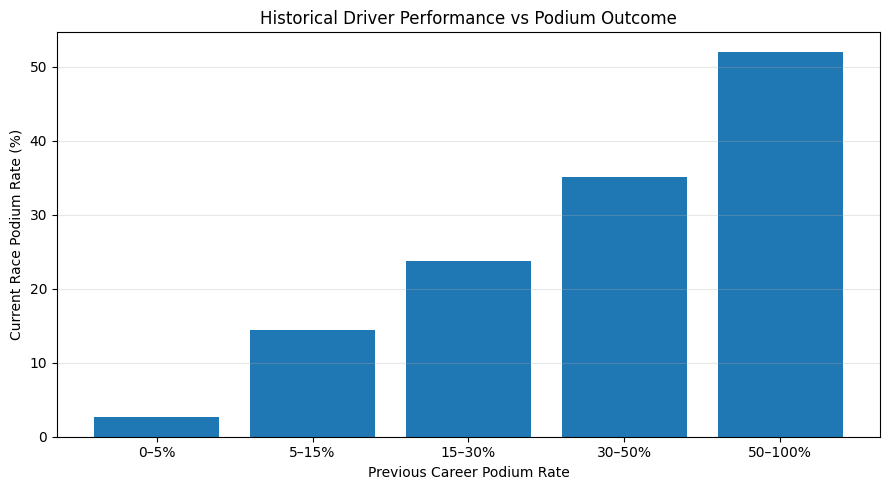

In [417]:
# Group historical podium rates into interpretable intervals
rate_bins = [-0.001, 0.05, 0.15, 0.30, 0.50, 1.001]

rate_labels = [
    '0–5%',
    '5–15%',
    '15–30%',
    '30–50%',
    '50–100%'
]

modern_df['driver_historical_rate_group'] = pd.cut(
    modern_df['driver_past_podium_rate'],
    bins=rate_bins,
    labels=rate_labels
)

historical_rate_summary = (
    modern_df.groupby(
        'driver_historical_rate_group',
        observed=False
    )
    .agg(
        observations=('podium', 'size'),
        podiums=('podium', 'sum'),
        podium_rate=('podium', 'mean')
    )
)

historical_rate_summary['podium_rate_pct'] = (
    historical_rate_summary['podium_rate'] * 100
)

display(historical_rate_summary.round(2))

plt.figure(figsize=(9, 5))

plt.bar(
    historical_rate_summary.index.astype(str),
    historical_rate_summary['podium_rate_pct']
)

plt.xlabel('Previous Career Podium Rate')
plt.ylabel('Current Race Podium Rate (%)')
plt.title('Historical Driver Performance vs Podium Outcome')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

,observations,podiums,podium_rate,podium_rate_pct
driver_recent_rate_group,,,,
0–5%,18547,668,0.04,3.60
5–15%,0,0,NaN,NaN
15–30%,3469,657,0.19,18.94
30–50%,2125,757,0.36,35.62
50–100%,2527,1313,0.52,51.96


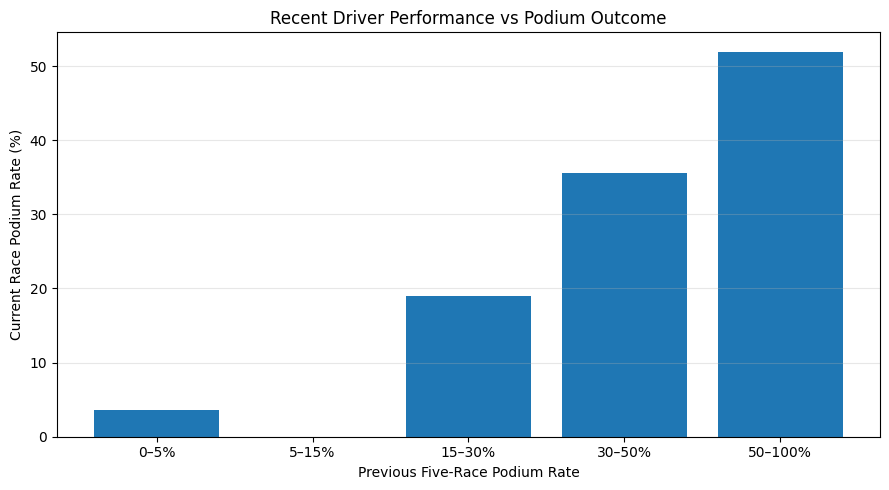

In [418]:
modern_df['driver_recent_rate_group'] = pd.cut(
    modern_df['driver_recent_podium_rate_5'],
    bins=rate_bins,
    labels=rate_labels
)

recent_rate_summary = (
    modern_df.groupby(
        'driver_recent_rate_group',
        observed=False
    )
    .agg(
        observations=('podium', 'size'),
        podiums=('podium', 'sum'),
        podium_rate=('podium', 'mean')
    )
)

recent_rate_summary['podium_rate_pct'] = (
    recent_rate_summary['podium_rate'] * 100
)

display(recent_rate_summary.round(2))

plt.figure(figsize=(9, 5))

plt.bar(
    recent_rate_summary.index.astype(str),
    recent_rate_summary['podium_rate_pct']
)

plt.xlabel('Previous Five-Race Podium Rate')
plt.ylabel('Current Race Podium Rate (%)')
plt.title('Recent Driver Performance vs Podium Outcome')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

,observations,podiums,podium_rate,podium_rate_pct
driver_experience_group,,,,
0,861,21,0.02,2.44
1–10,4701,218,0.05,4.64
11–30,5318,450,0.08,8.46
31–60,5078,604,0.12,11.89
61–100,4379,739,0.17,16.88
101–200,4833,1075,0.22,22.24
200+,1498,288,0.19,19.23


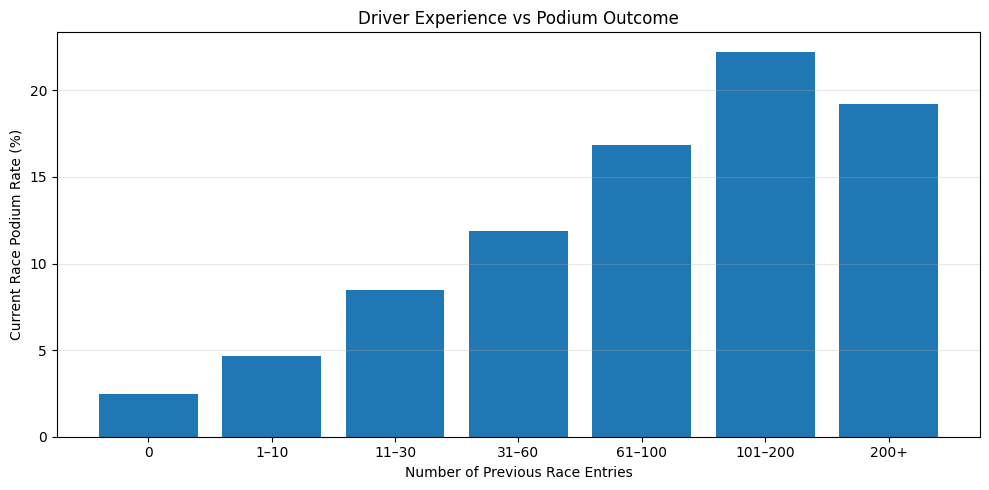

In [419]:
experience_bins = [-1, 0, 10, 30, 60, 100, 200, np.inf]

experience_labels = [
    '0',
    '1–10',
    '11–30',
    '31–60',
    '61–100',
    '101–200',
    '200+'
]

modern_df['driver_experience_group'] = pd.cut(
    modern_df['driver_previous_races'],
    bins=experience_bins,
    labels=experience_labels
)

experience_summary = (
    modern_df.groupby(
        'driver_experience_group',
        observed=False
    )
    .agg(
        observations=('podium', 'size'),
        podiums=('podium', 'sum'),
        podium_rate=('podium', 'mean')
    )
)

experience_summary['podium_rate_pct'] = (
    experience_summary['podium_rate'] * 100
)

display(experience_summary.round(2))

plt.figure(figsize=(10, 5))

plt.bar(
    experience_summary.index.astype(str),
    experience_summary['podium_rate_pct']
)

plt.xlabel('Number of Previous Race Entries')
plt.ylabel('Current Race Podium Rate (%)')
plt.title('Driver Experience vs Podium Outcome')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### 6.1 Results and Interpretation — Driver Historical Performance

#### Chronological Validation

The chronological validation produced the following results:

- Driver-date combinations with multiple observations: **0**
- Maximum observations per driver per date: **1**
- First recorded driver entries with zero previous races: **861 out of 861**

These findings support the correctness of the chronological ordering used to engineer historical driver features.

In particular, every driver's first recorded observation has `driver_previous_races = 0`, and no driver has multiple observations on the same date.

Combined with the use of shifted outcomes, these checks provide evidence that the historical features exclude the current race's result.

#### Historical Driver Podium Rate

The analysis compares a driver's previous career podium rate with the probability of achieving a podium in the current race.

| Previous Career Podium Rate | Observations | Current Podium Rate |
|---|---:|---:|
| 0–5% | 14,634 | 2.61% |
| 5–15% | 4,359 | 14.43% |
| 15–30% | 4,125 | 23.71% |
| 30–50% | 2,610 | 35.13% |
| 50–100% | 940 | 52.02% |

A strong increasing relationship is observed.

Drivers with historical podium rates between 0% and 5% achieve podiums in only **2.61%** of the current-race observations.

In contrast, drivers with historical podium rates above 50% achieve podiums in **52.02%** of observations.

This represents a difference of **49.41 percentage points**.

The results provide strong descriptive evidence that historical driver performance is associated with future podium outcomes.

**Feature-selection decision:** Retain `driver_past_podium_rate` as a candidate predictor.

#### Recent Driver Podium Rate

The recent-performance analysis evaluates the proportion of podium finishes across the previous five recorded race entries.

| Previous Five-Race Podium Rate | Observations | Current Podium Rate |
|---|---:|---:|
| 0–5% | 18,547 | 3.60% |
| 5–15% | 0 | Not applicable |
| 15–30% | 3,469 | 18.94% |
| 30–50% | 2,125 | 35.62% |
| 50–100% | 2,527 | 51.96% |

The observed current-race podium probability increases substantially with recent podium performance.

Drivers with a recent podium rate near zero achieve podiums in **3.60%** of observations, while those in the highest recent-performance group achieve podiums in **51.96%**.

The difference is **48.36 percentage points**.

The empty 5–15% interval is expected because the rolling average is calculated from binary podium outcomes over at most five previous entries. Its possible values are discrete rather than continuously distributed.

Recent podium performance may capture changes in driver competitiveness that are not fully represented by career-long statistics.

**Feature-selection decision:** Retain `driver_recent_podium_rate_5` as a candidate predictor.

#### Driver Experience

The experience analysis examines the number of previous race entries.

| Previous Race Entries | Observations | Current Podium Rate |
|---|---:|---:|
| 0 | 861 | 2.44% |
| 1–10 | 4,701 | 4.64% |
| 11–30 | 5,318 | 8.46% |
| 31–60 | 5,078 | 11.89% |
| 61–100 | 4,379 | 16.88% |
| 101–200 | 4,833 | 22.24% |
| More than 200 | 1,498 | 19.23% |

The podium rate generally increases with previous race experience up to the 101–200 group.

Drivers making their first recorded race entry have a podium rate of **2.44%**, compared with **22.24%** for drivers with 101–200 previous entries.

However, the podium rate decreases slightly to **19.23%** for drivers with more than 200 previous entries.

This indicates that the relationship is not strictly linear.

The observed pattern may reflect differences in experience, driver selection, career longevity, and competitive opportunities. It does not establish that accumulating race entries directly causes better results.

**Feature-selection decision:** Retain `driver_previous_races` as a candidate predictor.

#### Overall Interpretation

The three exploratory analyses show that:

1. Higher historical podium rates are associated with higher current-race podium probabilities.
2. Higher recent podium rates are associated with higher current-race podium probabilities.
3. Greater driver experience is generally associated with higher podium probabilities, although the relationship is not strictly monotonic.

These results support retaining the historical driver-performance features for modeling.

However, the observed relationships are descriptive and do not demonstrate that each feature adds independent predictive information beyond starting grid position or the other driver features.

The final feature set will be evaluated using chronological validation and feature-group ablation.

The test set will remain untouched during model selection.

## 7. Feature Engineering — Historical Constructor Performance

### Objective

Driver performance depends not only on individual experience and skill but also on the competitiveness of the constructor.

Historical constructor-performance features are engineered to represent the team's previous race experience and podium performance.

### Engineered Features

**1. Constructor Previous Races**

`constructor_previous_races` measures the number of earlier Grand Prix events in which the constructor has recorded entries.

**2. Constructor Previous Entries**

`constructor_previous_entries` measures the cumulative number of driver-race entries previously recorded for the constructor.

This differs from previous races because a constructor may enter multiple drivers in the same Grand Prix.

**3. Constructor Past Podiums**

`constructor_past_podiums` measures the total number of podium finishes achieved by the constructor before the current race.

**4. Constructor Historical Podium Rate**

`constructor_past_podium_rate` is calculated as:

\[
\text{Constructor Historical Podium Rate}
=
\frac{\text{Previous Constructor Podiums}}
{\text{Previous Constructor Entries}}
\]

Using previous entries as the denominator produces a driver-entry-level podium rate.

**5. Constructor Recent Podium Rate**

`constructor_recent_podium_rate_5` measures the constructor's podium rate across its previous five Grand Prix appearances.

The calculation aggregates podiums and driver entries across those earlier events.

### Preventing Target Leakage

A constructor may have multiple drivers participating in the same race.

If cumulative statistics were calculated directly from individual driver rows, one driver's current-race outcome could accidentally influence another driver's pre-race features.

To prevent this:

1. Driver observations are aggregated to one record per constructor per race.
2. Historical statistics are calculated in chronological race order.
3. Cumulative podiums and entries exclude the current race.
4. Recent performance uses only the previous five constructor-race appearances.
5. The same pre-race constructor features are assigned to all drivers representing that constructor in the current race.

This ensures that no driver's current-race result is used to construct a teammate's features.

### Expected Predictive Value

Constructors with strong historical podium records may have higher podium probabilities because of competitive car performance, engineering capability, and organizational strength.

Recent constructor performance may capture changes in competitiveness that are not reflected in long-term historical averages.

The usefulness of these features will be evaluated through exploratory analysis and chronological model validation.

In [420]:
# Start from the complete cleaned historical dataset
constructor_history = model_df[
    ['raceId', 'constructorId', 'date', 'podium']
].copy()

# Aggregate driver entries at the constructor-race level
constructor_races = (
    constructor_history
    .groupby(
        ['constructorId', 'raceId', 'date'],
        as_index=False
    )
    .agg(
        race_entries=('podium', 'size'),
        race_podiums=('podium', 'sum')
    )
)

# Sort chronologically within each constructor
constructor_races = constructor_races.sort_values(
    ['constructorId', 'date', 'raceId']
).reset_index(drop=True)

constructor_group = constructor_races.groupby(
    'constructorId'
)

# 1. Previous constructor race appearances
constructor_races['constructor_previous_races'] = (
    constructor_group.cumcount()
)

# 2. Previous driver entries for the constructor
constructor_races['constructor_previous_entries'] = (
    constructor_group['race_entries']
    .transform(lambda x: x.cumsum().shift(1))
    .fillna(0)
)

# 3. Previous constructor podium finishes
constructor_races['constructor_past_podiums'] = (
    constructor_group['race_podiums']
    .transform(lambda x: x.cumsum().shift(1))
    .fillna(0)
)

# 4. Historical podium rate per previous driver entry
constructor_races['constructor_past_podium_rate'] = np.where(
    constructor_races['constructor_previous_entries'] > 0,
    constructor_races['constructor_past_podiums']
    / constructor_races['constructor_previous_entries'],
    0
)

# 5. Recent podium rate across previous five race appearances
recent_podiums = (
    constructor_group['race_podiums']
    .transform(
        lambda x: x.shift(1).rolling(
            window=5,
            min_periods=1
        ).sum()
    )
)

recent_entries = (
    constructor_group['race_entries']
    .transform(
        lambda x: x.shift(1).rolling(
            window=5,
            min_periods=1
        ).sum()
    )
)

constructor_races['constructor_recent_podium_rate_5'] = (
    recent_podiums.div(recent_entries)
    .fillna(0)
)

constructor_feature_cols = [
    'constructor_previous_races',
    'constructor_previous_entries',
    'constructor_past_podiums',
    'constructor_past_podium_rate',
    'constructor_recent_podium_rate_5'
]

# Prevent duplicate feature columns on rerun
modern_df = modern_df.drop(
    columns=constructor_feature_cols,
    errors='ignore'
)

# Merge race-level constructor history into driver-level data
modern_df = modern_df.merge(
    constructor_races[
        ['raceId', 'constructorId'] + constructor_feature_cols
    ],
    on=['raceId', 'constructorId'],
    how='left',
    validate='many_to_one'
)

print("Dataset shape:", modern_df.shape)

print("\nMissing constructor features:")
print(
    modern_df[constructor_feature_cols].isna().sum()
)

print("\nDuplicate driver-race pairs:")
print(
    modern_df.duplicated(
        ['raceId', 'driverId']
    ).sum()
)

print("\nConstructor feature summary:")
display(
    modern_df[constructor_feature_cols]
    .describe()
    .round(3)
)

# Validate results
assert len(modern_df) == 26668

assert modern_df[
    constructor_feature_cols
].notna().all().all()

assert modern_df[
    'constructor_past_podium_rate'
].between(0, 1).all()

assert modern_df[
    'constructor_recent_podium_rate_5'
].between(0, 1).all()

assert not modern_df.duplicated(
    ['raceId', 'driverId']
).any()

print("\nConstructor feature validation passed!")

Dataset shape: (26668, 59)

Missing constructor features:
constructor_previous_races          0
constructor_previous_entries        0
constructor_past_podiums            0
constructor_past_podium_rate        0
constructor_recent_podium_rate_5    0
dtype: int64

Duplicate driver-race pairs:
0

Constructor feature summary:


,constructor_previous_races,constructor_previous_entries,constructor_past_podiums,constructor_past_podium_rate,constructor_recent_podium_rate_5
count,26668.000,26668.000,26668.000,26668.000,26668.000
mean,182.881,396.078,89.431,0.134,0.128
std,224.624,484.541,159.605,0.134,0.197
min,0.000,0.000,0.000,0.000,0.000
25%,29.000,64.000,1.000,0.007,0.000
50%,92.000,208.000,12.000,0.100,0.000
75%,246.000,519.000,89.000,0.245,0.200
max,1099.000,2415.000,837.000,1.000,1.000



Constructor feature validation passed!


### 7.1 Results and Interpretation — Historical Constructor Features

#### Feature Engineering Validation

Five historical constructor-performance features were generated:

- `constructor_previous_races`
- `constructor_previous_entries`
- `constructor_past_podiums`
- `constructor_past_podium_rate`
- `constructor_recent_podium_rate_5`

All five features contain **26,668 non-missing observations**, and the dataset contains no duplicate driver-race combinations after merging.

The historical and recent constructor podium rates are also bounded between 0 and 1, as expected.

These results confirm that the feature calculations are numerically valid and that the merge preserved the modeling dataset.

#### Constructor Experience and Participation

The constructor experience features show considerable variation across observations.

| Statistic | Previous Races | Previous Driver Entries |
|---|---:|---:|
| Mean | 182.881 | 396.078 |
| Median | 92 | 208 |
| 25th percentile | 29 | 64 |
| 75th percentile | 246 | 519 |
| Maximum | 1,099 | 2,415 |

Both experience distributions are right-skewed.

The mean number of previous constructor races is substantially greater than the median, indicating that some long-established constructors contribute many more observations than newer or short-lived constructors.

The difference between previous races and previous entries is expected because constructors may enter multiple drivers in the same event.

These features represent different aspects of constructor experience:

- `constructor_previous_races` measures the number of earlier Grand Prix appearances.
- `constructor_previous_entries` measures cumulative driver participation.

They may be strongly correlated, so their independent predictive value will need to be evaluated.

#### Historical Constructor Podium Performance

The cumulative number of previous constructor podiums ranges from **0 to 837**, with a median of **12**.

The historical constructor podium-rate feature has:

- Mean: **0.134**
- Median: **0.100**
- 75th percentile: **0.245**
- Maximum: **1.000**

The median historical rate of 10.0% indicates that half of the driver-race observations are associated with constructors whose previous recorded podium rate is at most 10%.

The distribution suggests substantial differences in historical competitiveness among constructors.

#### Recent Constructor Podium Performance

The recent five-race constructor podium-rate feature has:

- Mean: **0.128**
- Median: **0.000**
- 75th percentile: **0.200**
- Maximum: **1.000**

The median of zero indicates that at least half of the driver-race observations are associated with constructors that achieved no podiums across their previous five recorded Grand Prix appearances, or had no earlier appearances.

Recent constructor performance may capture short-term changes in competitiveness that are not fully represented by cumulative historical statistics.

#### Initial Feature-Selection Decision

All five constructor-history features are retained as candidate predictors for exploratory evaluation.

They represent constructor experience, cumulative achievement, historical competitiveness, and recent performance.

However, these descriptive statistics do not yet demonstrate a relationship with the current-race podium target.

The next analysis will examine whether historical and recent constructor podium rates are associated with current podium probability.

Final feature selection will be based on chronological validation and feature-group ablation rather than descriptive statistics alone.

## 8. Exploratory Data Analysis — Constructor Historical Performance

### Objective

Historical constructor-performance features were engineered to capture the experience and competitiveness of the team associated with each driver.

This analysis evaluates whether these features demonstrate meaningful associations with podium outcomes.

### Analysis Method

Three relationships are investigated:

**1. Historical Constructor Podium Rate**

Constructor observations are grouped according to their previous cumulative podium rates.

The current-race podium percentage is calculated for each group.

**2. Recent Constructor Podium Rate**

The constructor's podium rate across its previous five Grand Prix appearances is compared with the current-race podium outcome.

This evaluates whether recent constructor competitiveness is associated with current podium probability.

**3. Constructor Experience**

Constructors are grouped by the number of previous Grand Prix appearances.

The podium rate within each experience group is calculated to investigate whether longer-established constructors tend to achieve better results.

### Interpretation Considerations

The analysis is descriptive and does not establish causation.

For example, a higher podium rate among experienced constructors may reflect differences in team resources, car competitiveness, driver quality, or historical era.

Furthermore, constructor performance may overlap with driver historical performance and starting grid position.

Therefore, these exploratory findings will justify candidate feature inclusion, while chronological validation and feature-group ablation will determine whether the features improve prediction performance.

,observations,podiums,podium_rate,podium_rate_pct
constructor_historical_rate_group,,,,
0–5%,11264,223,0.02,1.98
5–15%,4500,382,0.08,8.49
15–30%,6428,1215,0.19,18.90
30–50%,4273,1488,0.35,34.82
50–100%,203,87,0.43,42.86


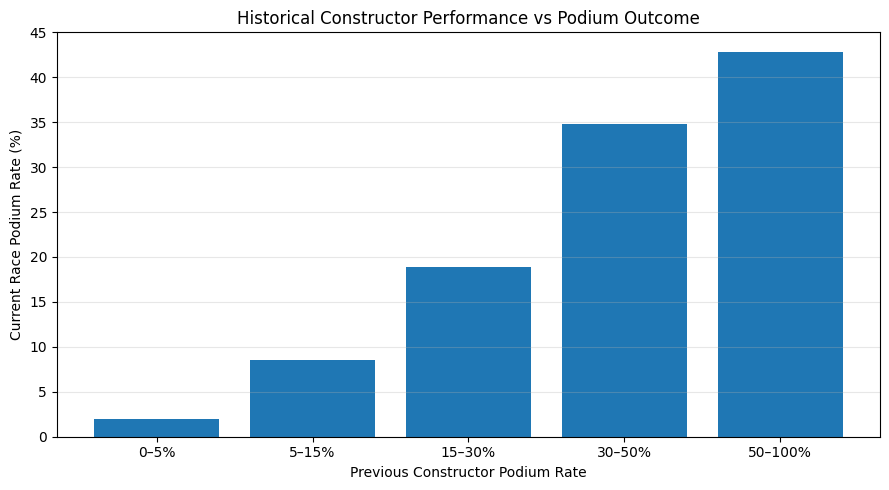

In [421]:
constructor_rate_bins = [-0.001, 0.05, 0.15, 0.30, 0.50, 1.001]

constructor_rate_labels = [
    '0–5%',
    '5–15%',
    '15–30%',
    '30–50%',
    '50–100%'
]

modern_df['constructor_historical_rate_group'] = pd.cut(
    modern_df['constructor_past_podium_rate'],
    bins=constructor_rate_bins,
    labels=constructor_rate_labels
)

constructor_historical_summary = (
    modern_df.groupby(
        'constructor_historical_rate_group',
        observed=False
    )
    .agg(
        observations=('podium', 'size'),
        podiums=('podium', 'sum'),
        podium_rate=('podium', 'mean')
    )
)

constructor_historical_summary['podium_rate_pct'] = (
    constructor_historical_summary['podium_rate'] * 100
)

display(constructor_historical_summary.round(2))

plt.figure(figsize=(9, 5))

plt.bar(
    constructor_historical_summary.index.astype(str),
    constructor_historical_summary['podium_rate_pct']
)

plt.xlabel('Previous Constructor Podium Rate')
plt.ylabel('Current Race Podium Rate (%)')
plt.title('Historical Constructor Performance vs Podium Outcome')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

,observations,podiums,podium_rate,podium_rate_pct
constructor_recent_rate_group,,,,
0–5%,14950,358,0.02,2.39
5–15%,3954,389,0.10,9.84
15–30%,3671,870,0.24,23.70
30–50%,2520,938,0.37,37.22
50–100%,1573,840,0.53,53.40


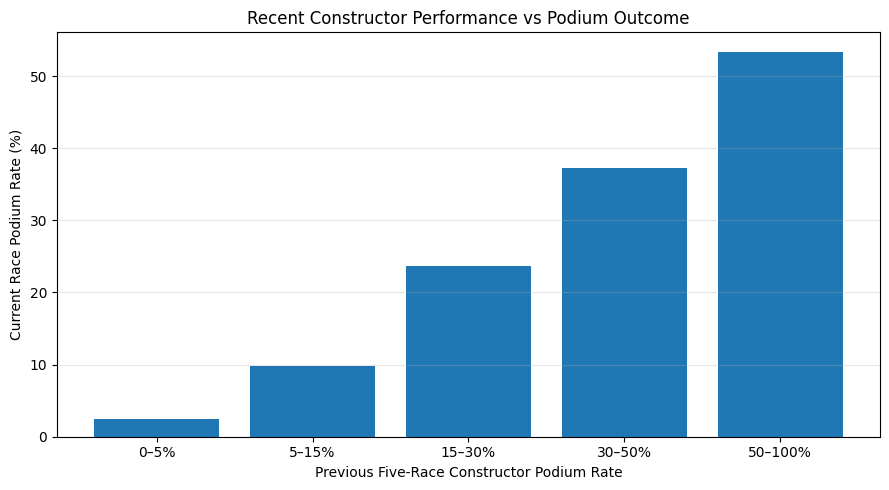

In [422]:
modern_df['constructor_recent_rate_group'] = pd.cut(
    modern_df['constructor_recent_podium_rate_5'],
    bins=constructor_rate_bins,
    labels=constructor_rate_labels
)

constructor_recent_summary = (
    modern_df.groupby(
        'constructor_recent_rate_group',
        observed=False
    )
    .agg(
        observations=('podium', 'size'),
        podiums=('podium', 'sum'),
        podium_rate=('podium', 'mean')
    )
)

constructor_recent_summary['podium_rate_pct'] = (
    constructor_recent_summary['podium_rate'] * 100
)

display(constructor_recent_summary.round(2))

plt.figure(figsize=(9, 5))

plt.bar(
    constructor_recent_summary.index.astype(str),
    constructor_recent_summary['podium_rate_pct']
)

plt.xlabel('Previous Five-Race Constructor Podium Rate')
plt.ylabel('Current Race Podium Rate (%)')
plt.title('Recent Constructor Performance vs Podium Outcome')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

,observations,podiums,podium_rate,podium_rate_pct
constructor_experience_group,,,,
0,346,16,0.05,4.62
1–25,5714,432,0.08,7.56
26–75,6008,497,0.08,8.27
76–150,4301,535,0.12,12.44
151–300,5103,801,0.16,15.70
301–600,3059,587,0.19,19.19
600+,2137,527,0.25,24.66


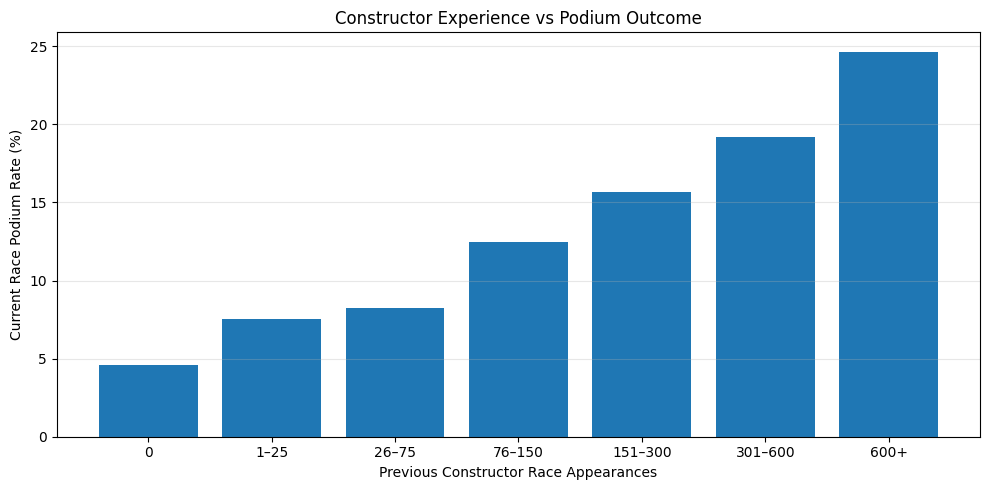

In [423]:
constructor_experience_bins = [
    -1, 0, 25, 75, 150, 300, 600, np.inf
]

constructor_experience_labels = [
    '0',
    '1–25',
    '26–75',
    '76–150',
    '151–300',
    '301–600',
    '600+'
]

modern_df['constructor_experience_group'] = pd.cut(
    modern_df['constructor_previous_races'],
    bins=constructor_experience_bins,
    labels=constructor_experience_labels
)

constructor_experience_summary = (
    modern_df.groupby(
        'constructor_experience_group',
        observed=False
    )
    .agg(
        observations=('podium', 'size'),
        podiums=('podium', 'sum'),
        podium_rate=('podium', 'mean')
    )
)

constructor_experience_summary['podium_rate_pct'] = (
    constructor_experience_summary['podium_rate'] * 100
)

display(constructor_experience_summary.round(2))

plt.figure(figsize=(10, 5))

plt.bar(
    constructor_experience_summary.index.astype(str),
    constructor_experience_summary['podium_rate_pct']
)

plt.xlabel('Previous Constructor Race Appearances')
plt.ylabel('Current Race Podium Rate (%)')
plt.title('Constructor Experience vs Podium Outcome')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### 8.1 Results and Interpretation — Constructor Historical Performance

#### Historical Constructor Podium Rate

The historical constructor podium-rate analysis produced the following results:

| Historical Constructor Podium Rate | Observations | Current Podium Rate |
|---|---:|---:|
| 0–5% | 11,264 | 1.98% |
| 5–15% | 4,500 | 8.49% |
| 15–30% | 6,428 | 18.90% |
| 30–50% | 4,273 | 34.82% |
| 50–100% | 203 | 42.86% |

The observed podium probability increases as the constructor's historical podium rate increases.

Drivers representing constructors with historical podium rates between 0% and 5% achieve podium finishes in only **1.98%** of observations.

In comparison, drivers representing constructors with historical podium rates above 50% achieve podiums in **42.86%** of observations.

This is a difference of **40.88 percentage points**.

The results suggest that historical constructor competitiveness contains potentially useful predictive information.

However, the highest-performance group contains only 203 observations, substantially fewer than the other groups. Its estimated podium probability should therefore be interpreted with greater caution.

**Feature-selection decision:** Retain `constructor_past_podium_rate` as a candidate predictor.

#### Recent Constructor Podium Rate

The recent constructor-performance analysis produced the following results:

| Recent Constructor Podium Rate | Observations | Current Podium Rate |
|---|---:|---:|
| 0–5% | 14,950 | 2.39% |
| 5–15% | 3,954 | 9.84% |
| 15–30% | 3,671 | 23.70% |
| 30–50% | 2,520 | 37.22% |
| 50–100% | 1,573 | 53.40% |

A strong increasing relationship is observed between recent constructor performance and current podium probability.

Drivers representing constructors with recent podium rates between 0% and 5% achieve podiums in **2.39%** of observations.

Drivers representing constructors with recent podium rates above 50% achieve podiums in **53.40%** of observations.

The difference is **51.01 percentage points**.

This suggests that recent constructor form may provide valuable information about current competitiveness.

Unlike historical podium rate, which summarizes performance over the constructor's entire recorded history, recent podium rate emphasizes the previous five Grand Prix appearances.

**Feature-selection decision:** Retain `constructor_recent_podium_rate_5` as a candidate predictor.

#### Constructor Experience

The constructor-experience analysis produced the following results:

| Previous Constructor Races | Observations | Current Podium Rate |
|---|---:|---:|
| 0 | 346 | 4.62% |
| 1–25 | 5,714 | 7.56% |
| 26–75 | 6,008 | 8.27% |
| 76–150 | 4,301 | 12.44% |
| 151–300 | 5,103 | 15.70% |
| 301–600 | 3,059 | 19.19% |
| More than 600 | 2,137 | 24.66% |

The observed podium rate increases consistently across the constructor-experience groups.

Constructors entering their first recorded Grand Prix have a podium rate of **4.62%**, compared with **24.66%** for constructors with more than 600 previous Grand Prix appearances.

This represents a difference of **20.04 percentage points**.

The pattern suggests that constructor experience is associated with podium success.

However, the relationship should not be interpreted as causal. Long-established constructors may differ from newer constructors in resources, technical capabilities, driver quality, and other characteristics.

**Feature-selection decision:** Retain `constructor_previous_races` as a candidate predictor.

#### Comparison of Constructor Features

The exploratory analysis reveals three important patterns:

1. Historical constructor success is strongly associated with current podium probability.
2. Recent constructor performance shows a substantial relationship with current podium probability.
3. Constructor experience is positively associated with podium probability.

These findings support including constructor-history features in the candidate feature set.

However, some features contain overlapping information. For example, previous constructor races and previous constructor entries both measure experience, while cumulative podiums and historical podium rate both reflect previous success.

Therefore, not every engineered feature must necessarily be included in the final model.

Feature-group ablation and chronological validation will be used to determine whether constructor features provide incremental predictive value beyond starting grid position and driver history.

#### Conclusion

The constructor-performance analysis provides strong descriptive evidence for retaining constructor experience, historical podium rate, and recent podium rate as candidate predictors.

The final model will be evaluated using chronological data splitting to test whether these historical relationships generalize to later Formula 1 seasons.

## 9. Dataset Splitting — Chronological 80/10/10

### Objective

The modeling dataset must be divided into independent training, validation, and testing partitions.

Because the task involves predicting future Formula 1 race outcomes using historical data, chronological splitting is selected instead of random splitting.

### Split Strategy

The target proportions are:

| Partition | Target Percentage | Purpose |
|---|---:|---|
| Training | 80% | Fit preprocessing transformations and model parameters |
| Validation | 10% | Compare models, tune hyperparameters, and select features |
| Testing | 10% | Evaluate the selected model on unseen future observations |

### Why Chronological Splitting?

Random splitting can mix earlier and later races across the partitions.

This would produce an unrealistic evaluation because the model could learn from later seasons while being evaluated on earlier seasons.

Chronological splitting better represents the intended prediction scenario: using historical information to predict races occurring afterward.

### Why Split by Race?

Each race contains multiple driver observations.

Splitting individual rows could place drivers from the same Grand Prix in both training and validation or testing partitions.

To avoid this, complete races are kept together.

The races are ordered chronologically, and partition boundaries are selected to approximate the requested 80/10/10 proportions by total driver-race observations.

Because complete races cannot be divided, the achieved percentages may differ slightly from the target percentages.

### Leakage Prevention

The following rules will be applied:

1. Preprocessing transformations will be fitted using training data only.
2. Validation data will be used for model comparison and hyperparameter selection.
3. Test data will remain untouched until the final model has been selected.
4. No race will appear in more than one partition.
5. Training observations must occur before validation observations, and validation observations before test observations.

The split boundaries, observation counts, podium distributions, and chronological separation will be verified before model training.

In [424]:
# Sort the complete modeling dataset chronologically
modern_df = modern_df.sort_values(
    ['date', 'raceId', 'driverId']
).reset_index(drop=True)

# One record per race, including its driver observation count
race_summary = (
    modern_df.groupby(
        ['raceId', 'date'],
        as_index=False
    )
    .agg(observations=('driverId', 'size'))
    .sort_values(['date', 'raceId'])
    .reset_index(drop=True)
)

# Cumulative driver-race observations
race_summary['cumulative_observations'] = (
    race_summary['observations'].cumsum()
)

total_observations = len(modern_df)

train_target = total_observations * 0.80
validation_end_target = total_observations * 0.90

# Find race boundaries closest to the target percentages
train_boundary = (
    race_summary['cumulative_observations']
    .sub(train_target)
    .abs()
    .idxmin()
)

validation_boundary = (
    race_summary['cumulative_observations']
    .sub(validation_end_target)
    .abs()
    .idxmin()
)

assert train_boundary < validation_boundary

# Allocate complete races to each partition
train_races = set(
    race_summary.loc[
        :train_boundary, 'raceId'
    ]
)

val_races = set(
    race_summary.loc[
        train_boundary + 1:validation_boundary,
        'raceId'
    ]
)

test_races = set(
    race_summary.loc[
        validation_boundary + 1:, 'raceId'
    ]
)

train_df = modern_df[
    modern_df['raceId'].isin(train_races)
].copy()

val_df = modern_df[
    modern_df['raceId'].isin(val_races)
].copy()

test_df = modern_df[
    modern_df['raceId'].isin(test_races)
].copy()

# Validate race-level separation
assert train_races.isdisjoint(val_races)
assert train_races.isdisjoint(test_races)
assert val_races.isdisjoint(test_races)

# Validate chronological ordering
assert train_df['date'].max() <= val_df['date'].min()
assert val_df['date'].max() <= test_df['date'].min()

# Validate all observations are preserved
assert (
    len(train_df) + len(val_df) + len(test_df)
    == len(modern_df)
)

print("Chronological split completed successfully!")

Chronological split completed successfully!


,Partition,Observations,Percentage,Races,First Year,Last Year,First Date,Last Date,Podium Rate (%)
0,Training,21336,80.01,866,1950,2012,1950-05-13,2012-06-24,12.27
1,Validation,2673,10.02,126,2012,2018,2012-07-08,2018-09-30,14.14
2,Testing,2659,9.97,133,2018,2024,2018-10-07,2024-12-08,15.01


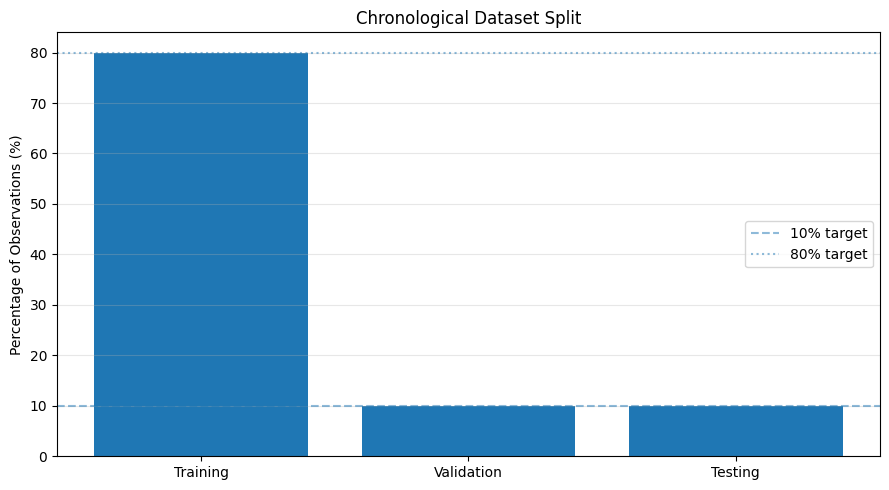

In [425]:
split_summary = pd.DataFrame({
    'Partition': ['Training', 'Validation', 'Testing'],
    'Observations': [
        len(train_df),
        len(val_df),
        len(test_df)
    ],
    'Percentage': [
        len(train_df) / len(modern_df) * 100,
        len(val_df) / len(modern_df) * 100,
        len(test_df) / len(modern_df) * 100
    ],
    'Races': [
        train_df['raceId'].nunique(),
        val_df['raceId'].nunique(),
        test_df['raceId'].nunique()
    ],
    'First Year': [
        train_df['year'].min(),
        val_df['year'].min(),
        test_df['year'].min()
    ],
    'Last Year': [
        train_df['year'].max(),
        val_df['year'].max(),
        test_df['year'].max()
    ],
    'First Date': [
        train_df['date'].min(),
        val_df['date'].min(),
        test_df['date'].min()
    ],
    'Last Date': [
        train_df['date'].max(),
        val_df['date'].max(),
        test_df['date'].max()
    ],
    'Podium Rate (%)': [
        train_df['podium'].mean() * 100,
        val_df['podium'].mean() * 100,
        test_df['podium'].mean() * 100
    ]
})

display(split_summary.round(2))

plt.figure(figsize=(9, 5))

plt.bar(
    split_summary['Partition'],
    split_summary['Percentage']
)

plt.axhline(
    10,
    linestyle='--',
    alpha=0.5,
    label='10% target'
)

plt.axhline(
    80,
    linestyle=':',
    alpha=0.5,
    label='80% target'
)

plt.ylabel('Percentage of Observations (%)')
plt.title('Chronological Dataset Split')
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

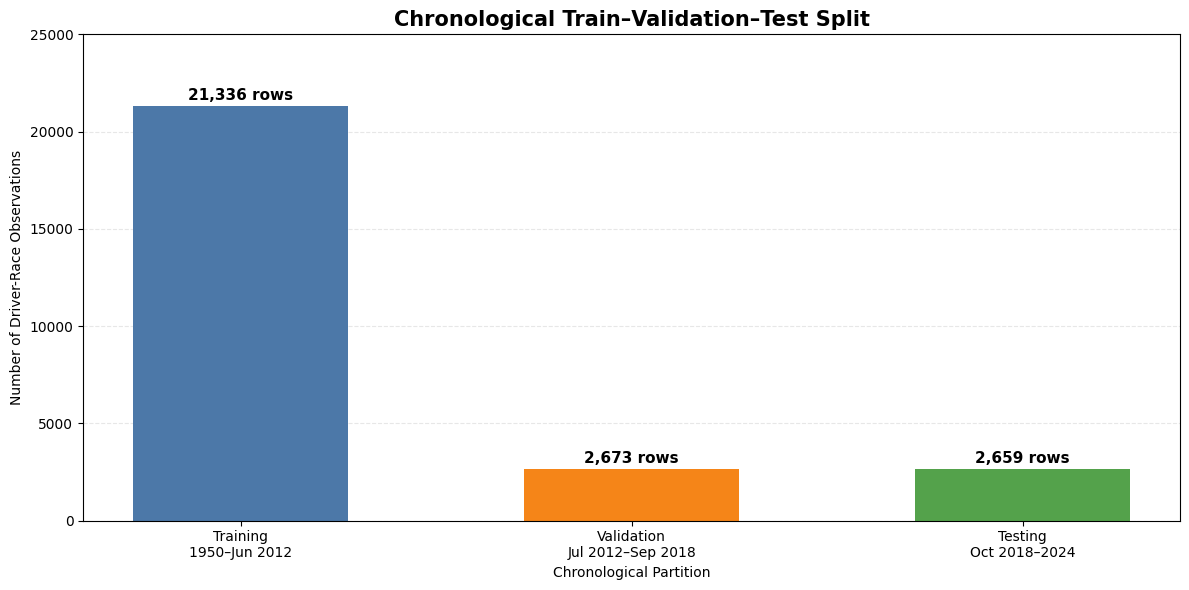

,Partition,Observations,Podium Rate (%),Period
0,Training,21336,12.27,1950–Jun 2012
1,Validation,2673,14.14,Jul 2012–Sep 2018
2,Testing,2659,15.01,Oct 2018–2024


In [426]:

import matplotlib.pyplot as plt
import pandas as pd

# Values from the chronological split summary
split_plot_df = pd.DataFrame({
    "Partition": ["Training", "Validation", "Testing"],
    "Observations": [21336, 2673, 2659],
    "Podium Rate (%)": [12.27, 14.14, 15.01],
    "Period": [
        "1950–Jun 2012",
        "Jul 2012–Sep 2018",
        "Oct 2018–2024"
    ]
})

fig, ax = plt.subplots(figsize=(12, 6))

colors = ["#4C78A8", "#F58518", "#54A24B"]

bars = ax.bar(
    split_plot_df["Partition"],
    split_plot_df["Observations"],
    color=colors,
    width=0.55
)

# Display sample counts and date ranges
for bar, (_, row) in zip(bars, split_plot_df.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 300,
        f'{row["Observations"]:,} rows',
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

# Show date ranges under partition labels
ax.set_xticks(range(3))
ax.set_xticklabels([
    f'{row["Partition"]}\n{row["Period"]}'
    for _, row in split_plot_df.iterrows()
])

ax.set_ylim(0, 25000)
ax.set_ylabel("Number of Driver-Race Observations")
ax.set_xlabel("Chronological Partition")

ax.set_title(
    "Chronological Train–Validation–Test Split",
    fontsize=15,
    fontweight="bold"
)

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    "figure10_chronological_split.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(split_plot_df)


### 9.1 Results and Interpretation — Chronological Dataset Split

#### Achieved Data Partitioning

The complete historical dataset contains **26,668 driver-race observations across 1,125 races**.

The chronological splitting procedure produced:

| Partition | Observations | Percentage | Races |
|---|---:|---:|---:|
| Training | 21,336 | 80.01% | 866 |
| Validation | 2,673 | 10.02% | 126 |
| Testing | 2,659 | 9.97% | 133 |
| **Total** | **26,668** | **100.00%** | **1,125** |

The achieved percentages are extremely close to the required 80% training, 10% validation, and 10% testing proportions.

The small differences result from keeping complete races together rather than splitting individual driver observations.

#### Chronological Boundaries

The partitions cover the following periods:

| Partition | First Race Date | Last Race Date |
|---|---|---|
| Training | 1950-05-13 | 2012-06-24 |
| Validation | 2012-07-08 | 2018-09-30 |
| Testing | 2018-10-07 | 2024-12-08 |

The training set contains the earliest races, followed by the validation set and finally the testing set.

Although 2012 appears in both training and validation, and 2018 appears in both validation and testing, the boundaries occur between different races.

Therefore, this does not represent overlap between partitions.

The splitting procedure also verifies that no `raceId` is shared between partitions and that all observations are preserved.

#### Class Distribution Across Partitions

The observed podium rates are:

| Partition | Podium Rate |
|---|---:|
| Training | 12.27% |
| Validation | 14.14% |
| Testing | 15.01% |

The podium rate increases across the chronological partitions.

This means that the class distribution is not identical across historical periods.

The difference may reflect changes in the number of entrants, historical participation patterns, and other characteristics of the recorded dataset.

Because the split is chronological, class proportions were not artificially balanced across partitions.

This is intentional: the evaluation should reflect the distribution encountered in later races rather than a randomly stratified sample.

The changing class distribution also means that accuracy alone is insufficient for evaluating the models.

Precision, recall, F1-score, ROC-AUC, and PR-AUC will be used alongside confusion matrices.

#### Leakage Prevention

The split satisfies the main temporal evaluation requirements:

1. Training races occur before validation races.
2. Validation races occur before testing races.
3. Complete races remain within a single partition.
4. No driver-race observations are discarded during splitting.
5. The testing partition is reserved for final evaluation.

Historical driver and constructor features use earlier race results. They can be updated chronologically as additional races occur, but preprocessing parameters and model parameters must not be learned from future observations.

#### Conclusion

The chronological split provides a realistic foundation for evaluating podium prediction on future Formula 1 races.

The achieved 80.01/10.02/9.97 allocation closely matches the required proportions while preserving race-level separation.

The next stage will select the modeling features, investigate their distributions, and evaluate preprocessing strategies fitted exclusively on training data.

## 10. Feature Selection and Preprocessing Preparation

### Objective

The exploratory analyses identified several candidate predictors associated with podium outcomes.

Before model training, a compact initial feature set is selected based on predictive relevance, pre-race availability, interpretability, and redundancy.

### Selected Candidate Features

The initial model uses nine predictors:

**Starting Position**
- `grid`
- `front_row_start`
- `grid_zero_flag`

**Driver History**
- `driver_previous_races`
- `driver_past_podium_rate`
- `driver_recent_podium_rate_5`

**Constructor History**
- `constructor_previous_races`
- `constructor_past_podium_rate`
- `constructor_recent_podium_rate_5`

### Excluded Features

`qualifying_position` is excluded because 60.65% of its values are missing and it is highly correlated with starting grid position.

`driver_past_podiums`, `constructor_past_podiums`, and `constructor_previous_entries` are excluded from the initial feature set to reduce potentially redundant information. Their contribution can be investigated through later ablation or alternative feature experiments.

Driver identifiers, constructor identifiers, race identifiers, and final race-status information are not included as direct predictors.

### Special Handling of Grid Zero

The exploratory analysis showed that grid zero does not represent an ordinary starting position.

Therefore:

1. `grid_zero_flag` identifies observations originally recorded with `grid = 0`.
2. Those zero values are replaced with missing values in the numerical `grid` feature.
3. Missing grid values will be imputed using a statistic learned from training data only.

The grid-zero indicator is treated as a candidate feature subject to a pre-race availability assumption. Its contribution will be assessed during validation.

### Preprocessing Requirements

The selected features have different numerical scales and distributions.

For example, historical podium rates range from 0 to 1, while driver and constructor experience can reach several hundred or more than one thousand previous races.

The preprocessing stage will therefore investigate missing-value imputation and feature scaling.

Preprocessing transformations must be fitted on training data only and then applied unchanged to validation and testing data.

This prevents information from future partitions from influencing the fitted transformations.

### Evaluation Plan

Before model training, the following checks are performed on the training partition:

1. Missing-value counts.
2. Numerical ranges and summary statistics.
3. Feature correlations.
4. Distribution of the selected predictors.

These findings will guide the preprocessing experiments and subsequent model selection.

In [427]:
feature_cols = [
    'grid',
    'front_row_start',
    'grid_zero_flag',
    'driver_previous_races',
    'driver_past_podium_rate',
    'driver_recent_podium_rate_5',
    'constructor_previous_races',
    'constructor_past_podium_rate',
    'constructor_recent_podium_rate_5'
]

# Create a pre-race indicator for nonstandard grid positions
for df_part in [train_df, val_df, test_df]:
    df_part['grid_zero_flag'] = (
        df_part['grid'] == 0
    ).astype(int)

    # Grid zero is not a valid numerical starting position
    df_part['grid'] = df_part['grid'].replace(0, np.nan)

# Extract predictors and target
X_train = train_df[feature_cols].copy()
X_val = val_df[feature_cols].copy()
X_test = test_df[feature_cols].copy()

y_train = train_df['podium'].astype(int).copy()
y_val = val_df['podium'].astype(int).copy()
y_test = test_df['podium'].astype(int).copy()

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Testing features:", X_test.shape)

print("\nTraining feature missing values:")
display(X_train.isna().sum())

print("\nTraining feature summary:")
display(X_train.describe().round(3))

Training features: (21336, 9)
Validation features: (2673, 9)
Testing features: (2659, 9)

Training feature missing values:


grid                                1556
front_row_start                        0
grid_zero_flag                         0
driver_previous_races                  0
driver_past_podium_rate                0
driver_recent_podium_rate_5            0
constructor_previous_races             0
constructor_past_podium_rate           0
constructor_recent_podium_rate_5       0
dtype: int64


Training feature summary:


,grid,front_row_start,grid_zero_flag,driver_previous_races,driver_past_podium_rate,driver_recent_podium_rate_5,constructor_previous_races,constructor_past_podium_rate,constructor_recent_podium_rate_5
count,19780.000,21336.000,21336.000,21336.000,21336.000,21336.000,21336.000,21336.000,21336.000
mean,12.175,0.081,0.073,53.865,0.106,0.121,139.471,0.125,0.124
std,7.007,0.273,0.260,54.708,0.150,0.220,165.052,0.127,0.186
min,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,6.000,0.000,0.000,11.000,0.000,0.000,24.000,0.006,0.000
50%,12.000,0.000,0.000,36.000,0.033,0.000,73.000,0.093,0.000
75%,18.000,0.000,0.000,80.000,0.174,0.200,200.000,0.213,0.200
max,34.000,1.000,1.000,325.000,1.000,1.000,840.000,1.000,1.000


### 10.1 Results and Interpretation — Training Feature Distributions

#### Feature Completeness

The initial candidate feature set contains nine predictors.

The training partition contains **21,336 observations**, the validation partition contains **2,673 observations**, and the testing partition contains **2,659 observations**.

The missing-value analysis identified:

| Feature | Missing Training Values |
|---|---:|
| `grid` | 1,556 |
| All other selected features | 0 |

The 1,556 missing grid values represent approximately **7.29% of training observations**.

These values were deliberately introduced by replacing `grid = 0` with `NaN`, since zero does not represent a conventional starting position.

The original information is preserved through the binary feature `grid_zero_flag`.

Consequently, the preprocessing pipeline must include a missing-value imputation strategy for `grid`.

#### Starting Grid Position

After removing nonstandard zero values, valid starting positions range from **1 to 34**.

The training distribution has:

- Mean: 12.175
- Median: 12
- Standard deviation: 7.007

The median of 12 provides a possible imputation value for missing grid positions.

However, the imputation statistic must be fitted using training observations only and then applied unchanged to validation and testing observations.

#### Driver Experience

`driver_previous_races` ranges from **0 to 325**, with a mean of **53.865** and median of **36**.

The mean exceeds the median, indicating a right-skewed distribution.

Driver experience is measured on a substantially larger numerical scale than the podium-rate features.

#### Constructor Experience

`constructor_previous_races` ranges from **0 to 840**, with a mean of **139.471** and median of **73**.

This distribution is also right-skewed and has a substantially larger range than the driver podium-rate features.

Without appropriate scaling, experience features may have a disproportionate numerical influence on optimization and regularization.

#### Historical and Recent Podium Rates

All four historical and recent podium-rate features range from 0 to 1.

| Feature | Mean | Median |
|---|---:|---:|
| Driver historical podium rate | 0.106 | 0.033 |
| Driver recent podium rate | 0.121 | 0.000 |
| Constructor historical podium rate | 0.125 | 0.093 |
| Constructor recent podium rate | 0.124 | 0.000 |

Both recent-performance features have medians of zero, indicating substantial concentrations of observations with no recent podium success.

The historical podium-rate features have higher medians, reflecting their longer observation windows.

#### Binary Features

The two binary features are:

- `front_row_start`
- `grid_zero_flag`

Their training means are approximately **0.081** and **0.073**, respectively.

Because these are binary variables, their means represent the proportions of observations assigned a value of 1.

Thus, approximately 8.1% of training observations are front-row starters, while approximately 7.3% have nonstandard grid values.

These features are already represented on a 0–1 scale.

#### Preprocessing Implications

The training feature summary reveals three main preprocessing considerations:

1. **Missing values:** Numerical grid position requires imputation.
2. **Different numerical scales:** Experience features have much larger ranges than podium-rate features.
3. **Different distributions:** Experience variables are right-skewed, while podium-rate variables are bounded between 0 and 1.

The next stage will compare preprocessing approaches using training-fitted transformations.

Standardization will be considered for continuous numerical features, while binary indicators can be preserved in their original 0–1 representation.

#### Conclusion

The selected features have interpretable meanings and appropriate numerical ranges, but they require preprocessing before model training.

The initial preprocessing strategy will use training

,grid,front_row_start,grid_zero_flag,driver_previous_races,driver_past_podium_rate,driver_recent_podium_rate_5,constructor_previous_races,constructor_past_podium_rate,constructor_recent_podium_rate_5
grid,1.000,-0.471,NaN,-0.254,-0.507,-0.526,-0.260,-0.494,-0.526
front_row_start,-0.471,1.000,-0.083,0.120,0.379,0.438,0.168,0.289,0.411
grid_zero_flag,NaN,-0.083,1.000,-0.147,-0.164,-0.142,-0.129,-0.179,-0.142
driver_previous_races,-0.254,0.120,-0.147,1.000,0.406,0.243,0.331,0.221,0.244
driver_past_podium_rate,-0.507,0.379,-0.164,0.406,1.000,0.706,0.306,0.516,0.560
driver_recent_podium_rate_5,-0.526,0.438,-0.142,0.243,0.706,1.000,0.320,0.529,0.781
constructor_previous_races,-0.260,0.168,-0.129,0.331,0.306,0.320,1.000,0.524,0.373
constructor_past_podium_rate,-0.494,0.289,-0.179,0.221,0.516,0.529,0.524,1.000,0.695
constructor_recent_podium_rate_5,-0.526,0.411,-0.142,0.244,0.560,0.781,0.373,0.695,1.000


,grid,front_row_start,grid_zero_flag,driver_previous_races,driver_past_podium_rate,driver_recent_podium_rate_5,constructor_previous_races,constructor_past_podium_rate,constructor_recent_podium_rate_5
grid,1.000,-0.471,NaN,-0.254,-0.507,-0.526,-0.260,-0.494,-0.526
front_row_start,-0.471,1.000,-0.083,0.120,0.379,0.438,0.168,0.289,0.411
grid_zero_flag,NaN,-0.083,1.000,-0.147,-0.164,-0.142,-0.129,-0.179,-0.142
driver_previous_races,-0.254,0.120,-0.147,1.000,0.406,0.243,0.331,0.221,0.244
driver_past_podium_rate,-0.507,0.379,-0.164,0.406,1.000,0.706,0.306,0.516,0.560
driver_recent_podium_rate_5,-0.526,0.438,-0.142,0.243,0.706,1.000,0.320,0.529,0.781
constructor_previous_races,-0.260,0.168,-0.129,0.331,0.306,0.320,1.000,0.524,0.373
constructor_past_podium_rate,-0.494,0.289,-0.179,0.221,0.516,0.529,0.524,1.000,0.695
constructor_recent_podium_rate_5,-0.526,0.411,-0.142,0.244,0.560,0.781,0.373,0.695,1.000


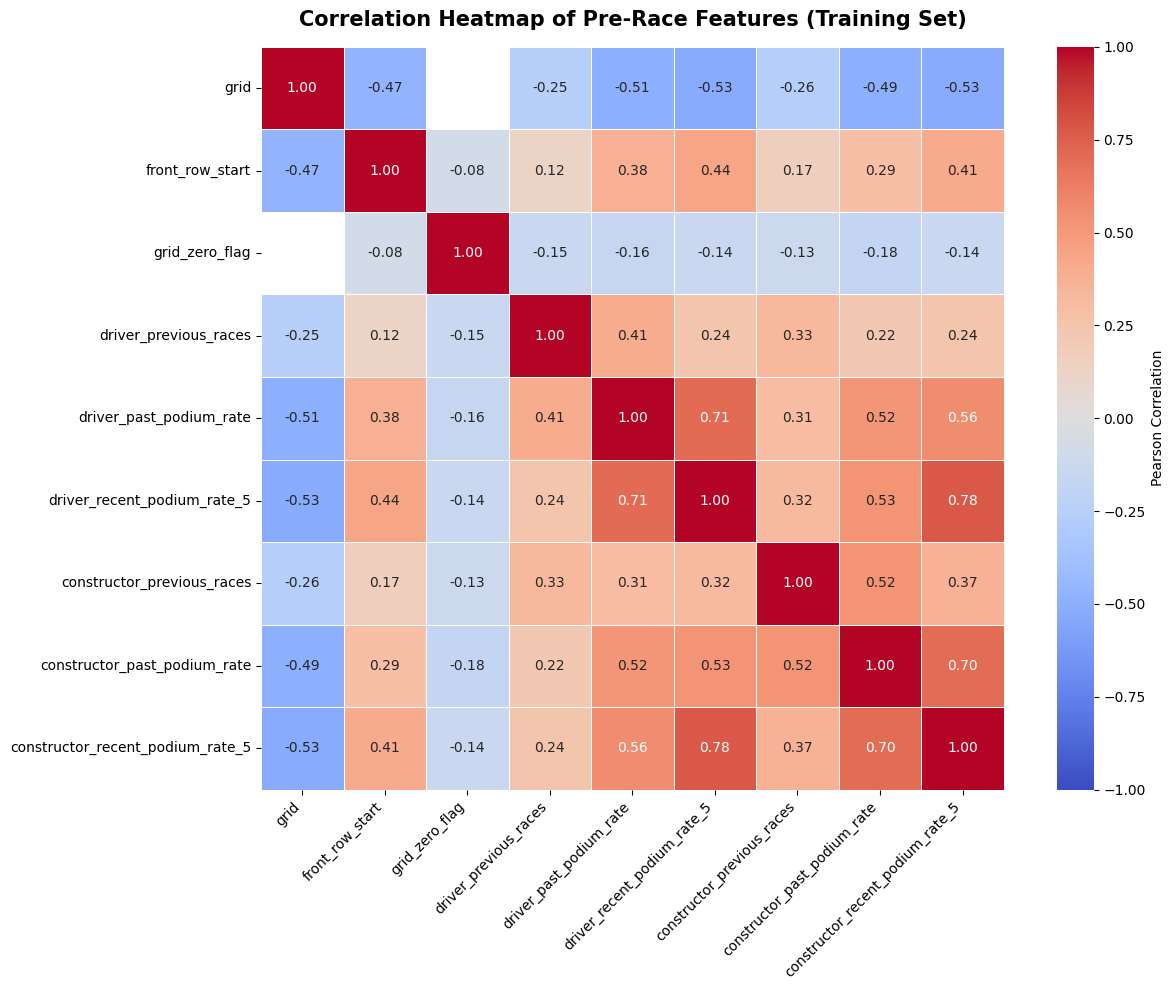

In [428]:
train_corr = X_train.corr()
display(train_corr.round(3))


import matplotlib.pyplot as plt
import seaborn as sns

# Calculate correlations using training data only
train_corr = X_train.corr()

# Display correlation table
display(train_corr.round(3))

# Create heatmap
plt.figure(figsize=(13, 10))

ax = sns.heatmap(
    train_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Pearson Correlation"}
)

plt.title(
    "Correlation Heatmap of Pre-Race Features (Training Set)",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xticks(rotation=45, ha="right", fontsize=10)
plt.yticks(rotation=0, fontsize=10)

plt.tight_layout()

plt.savefig(
    "figure9_feature_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### 10.2 Results and Interpretation — Feature Correlation Analysis

#### Objective

Pearson correlation analysis was performed on the training partition to investigate linear relationships among the nine selected predictors.

The analysis helps identify potentially redundant features and provides guidance for preprocessing and model evaluation.

#### Driver and Constructor Recent Performance

The strongest observed correlation is between:

- `driver_recent_podium_rate_5`
- `constructor_recent_podium_rate_5`

Their Pearson correlation coefficient is **0.781**.

This indicates a strong positive linear relationship.

The result is reasonable because drivers and constructors participate in the same races, and successful constructor performance is often associated with successful driver performance.

However, the features measure different entities: one represents the individual driver's previous results, while the other represents the constructor's previous results.

Therefore, both are retained initially, with their independent contributions to be evaluated through feature ablation.

#### Historical and Recent Driver Performance

The correlation between `driver_past_podium_rate` and `driver_recent_podium_rate_5` is **0.706**.

This indicates that drivers with strong historical records often also demonstrate strong recent performance.

Nevertheless, the two features capture different time horizons.

Historical podium rate measures cumulative performance, while recent podium rate emphasizes the previous five recorded race entries.

Both are retained for initial model evaluation.

#### Historical and Recent Constructor Performance

The correlation between `constructor_past_podium_rate` and `constructor_recent_podium_rate_5` is **0.695**.

This indicates a moderately strong positive relationship between long-term constructor success and recent constructor form.

However, a constructor's competitiveness may change over time, making recent performance potentially useful even when historical performance is already available.

#### Starting Grid Position

Starting grid position is negatively correlated with several performance features:

| Feature | Correlation with Grid |
|---|---:|
| Driver historical podium rate | -0.507 |
| Driver recent podium rate | -0.526 |
| Constructor historical podium rate | -0.494 |
| Constructor recent podium rate | -0.526 |

These negative relationships are expected because lower numerical grid positions represent better starting positions.

Historically successful drivers and constructors tend to qualify closer to the front of the grid.

This suggests that grid position and historical performance features contain overlapping predictive information.

Nevertheless, starting position represents current-race competitiveness, whereas historical features represent previous results.

Both types of information may contribute to podium prediction.

#### Front-Row Starting Indicator

The correlation between `grid` and `front_row_start` is **-0.471**.

This is expected because front-row starters occupy grid positions 1 and 2.

Although `front_row_start` is derived directly from grid position, it provides an explicit indicator of a potentially nonlinear front-row advantage.

Its inclusion will be evaluated through validation rather than assumed to improve performance.

#### Missing Correlation Values

The correlation between `grid` and `grid_zero_flag` is undefined (`NaN`).

This occurs because all observations with `grid_zero_flag = 1` have their numerical grid values replaced with missing values.

Among observations where `grid` remains valid, `grid_zero_flag` is always zero, so Pearson correlation cannot be calculated.

This is a consequence of the feature representation rather than an unexpected data-quality issue.

#### Implications for Model Development

The analysis identifies several moderately or strongly correlated predictors.

This may affect the stability and interpretation of coefficients in linear models, particularly logistic regression.

However, correlated predictors do not automatically reduce predictive performance, and neural networks can learn relationships involving correlated inputs.

Therefore, the initial modeling experiments will retain all nine candidate features.

Later experiments will compare feature groups to determine whether driver history, constructor history, and starting-position features provide additional predictive value.

#### Conclusion

The correlation analysis confirms that several candidate features share information, especially historical and recent performance indicators.

Nevertheless, they capture different aspects of driver ability, constructor competitiveness, and current starting position.

All nine candidate features will be retained for the initial baseline and neural-network experiments.

Their final inclusion will be determined through chronological validation and feature-group ablation.

In [429]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler

continuous_features = [
    'grid',
    'driver_previous_races',
    'driver_past_podium_rate',
    'driver_recent_podium_rate_5',
    'constructor_previous_races',
    'constructor_past_podium_rate',
    'constructor_recent_podium_rate_5'
]

binary_features = [
    'front_row_start',
    'grid_zero_flag'
]

def make_preprocessor(scaler=None):
    numeric_steps = [
        ('imputer', SimpleImputer(strategy='median'))
    ]

    if scaler is not None:
        numeric_steps.append(('scaler', scaler))

    numeric_pipeline = Pipeline(numeric_steps)

    return ColumnTransformer(
        transformers=[
            ('numeric', numeric_pipeline, continuous_features),
            ('binary', 'passthrough', binary_features)
        ],
        remainder='drop',
        verbose_feature_names_out=False
    )

preprocessors = {
    'No Scaling': make_preprocessor(),
    'StandardScaler': make_preprocessor(StandardScaler()),
    'MinMaxScaler': make_preprocessor(MinMaxScaler())
}

# Fit each configuration using training data only
X_train_versions = {}
X_val_versions = {}

for name, preprocessor in preprocessors.items():
    X_train_versions[name] = preprocessor.fit_transform(X_train)
    X_val_versions[name] = preprocessor.transform(X_val)

    print(
        name,
        "| Train:", X_train_versions[name].shape,
        "| Validation:", X_val_versions[name].shape
    )

No Scaling | Train: (21336, 9) | Validation: (2673, 9)
StandardScaler | Train: (21336, 9) | Validation: (2673, 9)
MinMaxScaler | Train: (21336, 9) | Validation: (2673, 9)


In [430]:
preprocessing_summary = []

for name, X_processed in X_train_versions.items():
    preprocessing_summary.append({
        'Configuration': name,
        'Shape': str(X_processed.shape),
        'Missing Values': int(np.isnan(X_processed).sum()),
        'Minimum Value': float(np.min(X_processed)),
        'Maximum Value': float(np.max(X_processed)),
        'Mean Absolute Value': float(
            np.mean(np.abs(X_processed))
        )
    })

preprocessing_summary = pd.DataFrame(
    preprocessing_summary
)

display(preprocessing_summary.round(3))

# Verify all training and validation arrays are finite
for name in preprocessors:
    assert np.isfinite(X_train_versions[name]).all()
    assert np.isfinite(X_val_versions[name]).all()

print("All preprocessing configurations passed validation.")

,Configuration,Shape,Missing Values,Minimum Value,Maximum Value,Mean Absolute Value
0,No Scaling,"(21336, 9)",0,0.000,840.000,22.903
1,StandardScaler,"(21336, 9)",0,-1.655,6.914,0.631
2,MinMaxScaler,"(21336, 9)",0,0.000,1.000,0.144


All preprocessing configurations passed validation.


,Order,Minimum,Maximum,Mean,Std,Missing Values
0,Median Imputation → StandardScaler,-1.6958,7.0927,0.0000,1.0000,0
1,StandardScaler → Median Imputation,-1.5937,6.9001,-0.0183,0.9748,0


Mean absolute difference: 0.024623
Maximum absolute difference: 0.208668


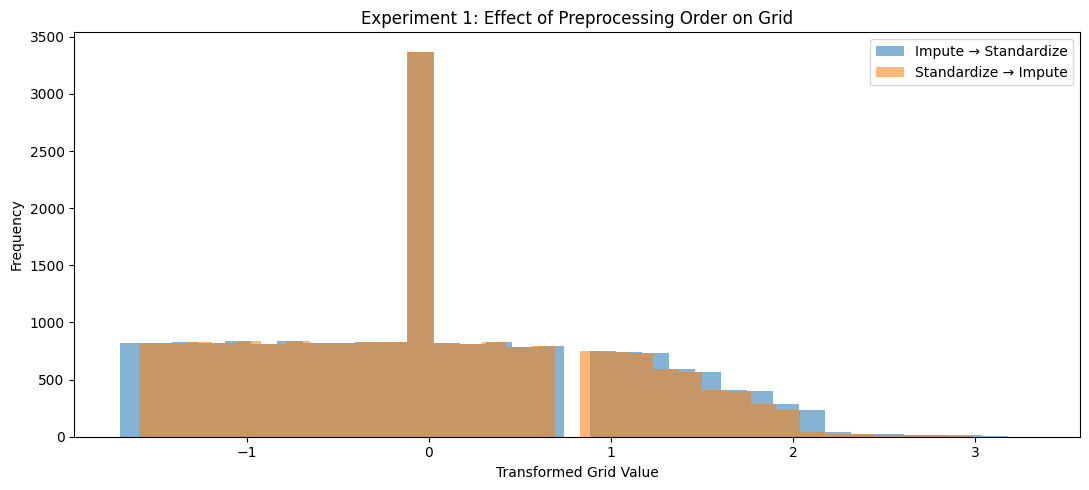

In [431]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Work with the original training features only
exp_X = X_train.copy()

# Introduce the same controlled missing values for both orders.
# Do not modify X_train or any existing model pipeline.
exp_X = exp_X.astype(float)
rng = np.random.default_rng(42)

missing_mask = rng.random(exp_X.shape) < 0.05
exp_X = exp_X.mask(missing_mask)

# ORDER A: Impute first, then standardize
imputer_A = SimpleImputer(strategy="median")
scaler_A = StandardScaler()

A_imputed = imputer_A.fit_transform(exp_X)
A_final = scaler_A.fit_transform(A_imputed)

# ORDER B: Standardize observed values first, then impute
scaler_B = StandardScaler()
imputer_B = SimpleImputer(strategy="median")

B_scaled = scaler_B.fit_transform(exp_X)
B_final = imputer_B.fit_transform(B_scaled)

# Compare results
difference = np.abs(A_final - B_final)

exp1_results = pd.DataFrame({
    "Order": [
        "Median Imputation → StandardScaler",
        "StandardScaler → Median Imputation"
    ],
    "Minimum": [A_final.min(), B_final.min()],
    "Maximum": [A_final.max(), B_final.max()],
    "Mean": [A_final.mean(), B_final.mean()],
    "Std": [A_final.std(), B_final.std()],
    "Missing Values": [
        np.isnan(A_final).sum(),
        np.isnan(B_final).sum()
    ]
})

display(exp1_results.round(4))

print("Mean absolute difference:",
      round(difference.mean(), 6))
print("Maximum absolute difference:",
      round(difference.max(), 6))

# Visualize one feature
feature_idx = list(X_train.columns).index("grid")

plt.figure(figsize=(11, 5))

plt.hist(
    A_final[:, feature_idx],
    bins=35,
    alpha=0.55,
    label="Impute → Standardize"
)

plt.hist(
    B_final[:, feature_idx],
    bins=35,
    alpha=0.55,
    label="Standardize → Impute"
)

plt.title("Experiment 1: Effect of Preprocessing Order on Grid")
plt.xlabel("Transformed Grid Value")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()

plt.savefig(
    "experiment1_preprocessing_order.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


,Order,Minimum,Maximum,Mean,Std,Missing Values
0,Median Imputation → MinMaxScaler,0.0,1.0,0.141,0.2131,0
1,MinMaxScaler → Median Imputation,0.0,1.0,0.141,0.2131,0


Mean absolute difference: 0.0
Maximum absolute difference: 0.0


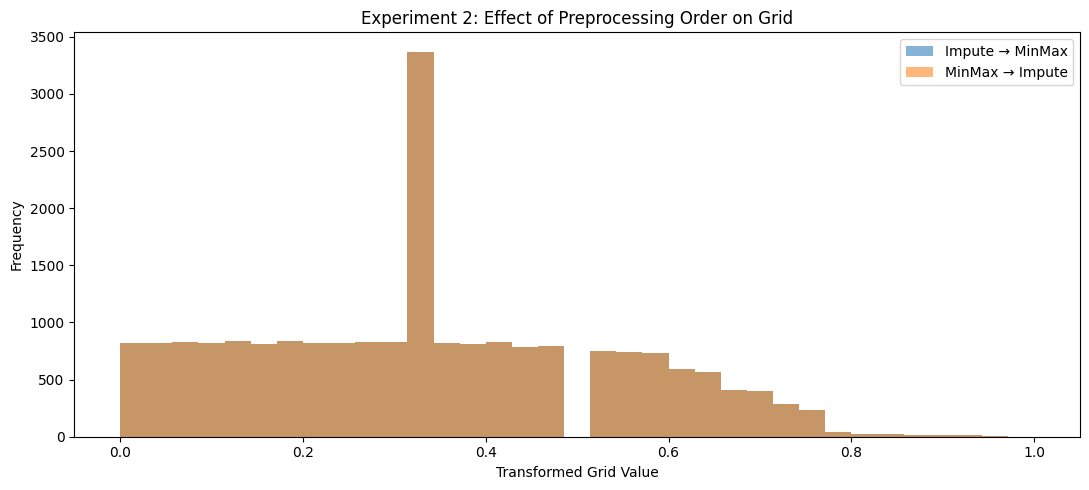

In [432]:

from sklearn.preprocessing import MinMaxScaler
from sklearn.impute import SimpleImputer

# ORDER A: Impute first, then MinMax scale
imputer_C = SimpleImputer(strategy="median")
scaler_C = MinMaxScaler()

C_imputed = imputer_C.fit_transform(exp_X)
C_final = scaler_C.fit_transform(C_imputed)

# ORDER B: MinMax scale observed values, then impute
scaler_D = MinMaxScaler()
imputer_D = SimpleImputer(strategy="median")

D_scaled = scaler_D.fit_transform(exp_X)
D_final = imputer_D.fit_transform(D_scaled)

# Compare results
difference_2 = np.abs(C_final - D_final)

exp2_results = pd.DataFrame({
    "Order": [
        "Median Imputation → MinMaxScaler",
        "MinMaxScaler → Median Imputation"
    ],
    "Minimum": [C_final.min(), D_final.min()],
    "Maximum": [C_final.max(), D_final.max()],
    "Mean": [C_final.mean(), D_final.mean()],
    "Std": [C_final.std(), D_final.std()],
    "Missing Values": [
        np.isnan(C_final).sum(),
        np.isnan(D_final).sum()
    ]
})

display(exp2_results.round(4))

print("Mean absolute difference:",
      round(difference_2.mean(), 8))
print("Maximum absolute difference:",
      round(difference_2.max(), 8))

feature_idx = list(X_train.columns).index("grid")

plt.figure(figsize=(11, 5))

plt.hist(
    C_final[:, feature_idx],
    bins=35,
    alpha=0.55,
    label="Impute → MinMax"
)

plt.hist(
    D_final[:, feature_idx],
    bins=35,
    alpha=0.55,
    label="MinMax → Impute"
)

plt.title("Experiment 2: Effect of Preprocessing Order on Grid")
plt.xlabel("Transformed Grid Value")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()

plt.savefig(
    "experiment2_preprocessing_order.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


## 11. Random Forest Prediction Model

### 11.1 Objective and Model Description

The objective is to predict whether a Formula 1 driver will finish on the podium in a given race. This is a binary classification task:

- **Class 0:** The driver does not finish in the top three.
- **Class 1:** The driver finishes in the top three.

A Random Forest classifier is used as the initial predictive model. Random Forest is an ensemble learning algorithm that combines multiple decision trees to produce a final prediction.

Each decision tree learns rules based on the input features, such as starting grid position, driver experience, previous podium rate, and constructor performance history. The trees are trained using randomized samples and feature selections, helping the ensemble capture nonlinear relationships and interactions between predictors.

For classification, the model combines the trees' predictions to estimate the probability that a driver will finish on the podium.

### 11.2 Training and Evaluation Strategy

The model will be fitted using the training partition. Its performance will then be evaluated on the training and validation partitions using ROC-AUC, PR-AUC, and F1 score.

Hyperparameter selection and probability-threshold selection will use training and validation data only. The test partition will remain unseen until the modeling decisions are finalized.

The initial Random Forest will serve as a baseline for subsequent feature-group ablation experiments, in which selected groups of predictors are removed to measure their contribution to predictive performance.

### 11.3 Limitations

Random Forest can capture nonlinear relationships, but it may overfit if its trees are too complex. Its probability estimates may also require threshold selection, particularly because podium finishes are less frequent than non-podium finishes. Furthermore, feature importance indicates predictive usefulness rather than causation, and model performance may vary across different Formula 1 eras.

In [433]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Build the initial Random Forest pipeline.
# The preprocessor imputes missing values using training data.
# Random Forest does not require feature scaling.

rf_model = Pipeline(steps=[
    ('preprocessor', make_preprocessor()),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=2,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

# Train using the training partition only
rf_model.fit(X_train, y_train)

print("Random Forest training completed successfully.")
print("Training observations:", len(X_train))
print("Features:", X_train.shape[1])
print("Number of trees:", 
      rf_model.named_steps['classifier'].n_estimators)


Random Forest training completed successfully.
Training observations: 21336
Features: 9
Number of trees: 300


In [434]:

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd
import numpy as np

RF_INITIAL_THRESHOLD = 0.5

def rf_evaluate_model(model, X, y, dataset_name, threshold=0.5):
    probabilities = model.predict_proba(X)[:, 1]
    predictions = (probabilities >= threshold).astype(int)

    return {
        "Dataset": dataset_name,
        "Accuracy": accuracy_score(y, predictions),
        "Precision": precision_score(y, predictions, zero_division=0),
        "Recall": recall_score(y, predictions, zero_division=0),
        "F1 Score": f1_score(y, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y, probabilities),
        "PR-AUC": average_precision_score(y, probabilities),
        "Threshold": threshold
    }

rf_baseline_results = pd.DataFrame([
    rf_evaluate_model(
        rf_model, X_train, y_train, "Training",
        RF_INITIAL_THRESHOLD
    ),
    rf_evaluate_model(
        rf_model, X_val, y_val, "Validation",
        RF_INITIAL_THRESHOLD
    )
])

print("Random Forest — Baseline Performance")
display(rf_baseline_results.round(4))


Random Forest — Baseline Performance


,Dataset,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC,Threshold
0,Training,0.9879,0.9114,0.9985,0.9530,0.9989,0.9916,0.5
1,Validation,0.8979,0.6357,0.6508,0.6431,0.9340,0.6487,0.5


In [435]:

from sklearn.model_selection import ParameterGrid
from sklearn.base import clone

rf_param_grid = {
    "classifier__n_estimators": [200, 300],
    "classifier__max_depth": [10, 20, None],
    "classifier__min_samples_leaf": [2, 5],
    "classifier__max_features": ["sqrt"]
}

rf_tuning_rows = []
rf_best_ap = -np.inf
rf_best_model = None
rf_best_params = None

for params in ParameterGrid(rf_param_grid):
    candidate = clone(rf_model)
    candidate.set_params(**params)
    candidate.fit(X_train, y_train)

    probabilities = candidate.predict_proba(X_val)[:, 1]
    val_ap = average_precision_score(y_val, probabilities)

    rf_tuning_rows.append({
        **params,
        "Validation PR-AUC": val_ap
    })

    if val_ap > rf_best_ap:
        rf_best_ap = val_ap
        rf_best_model = candidate
        rf_best_params = params

rf_tuning_results = pd.DataFrame(rf_tuning_rows).sort_values(
    "Validation PR-AUC",
    ascending=False
)

print("Best hyperparameters:", rf_best_params)
print(f"Best validation PR-AUC: {rf_best_ap:.4f}")
display(rf_tuning_results.round(4))


Best hyperparameters: {'classifier__max_depth': 10, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 2, 'classifier__n_estimators': 300}
Best validation PR-AUC: 0.6923


,classifier__max_depth,classifier__max_features,classifier__min_samples_leaf,classifier__n_estimators,Validation PR-AUC
1,10.0,sqrt,2,300,0.6923
0,10.0,sqrt,2,200,0.6866
2,10.0,sqrt,5,200,0.6790
3,10.0,sqrt,5,300,0.6785
7,20.0,sqrt,5,300,0.6717
11,NaN,sqrt,5,300,0.6714
10,NaN,sqrt,5,200,0.6709
6,20.0,sqrt,5,200,0.6700
5,20.0,sqrt,2,300,0.6647
4,20.0,sqrt,2,200,0.6537


Best threshold: 0.6948
Validation F1: 0.6754


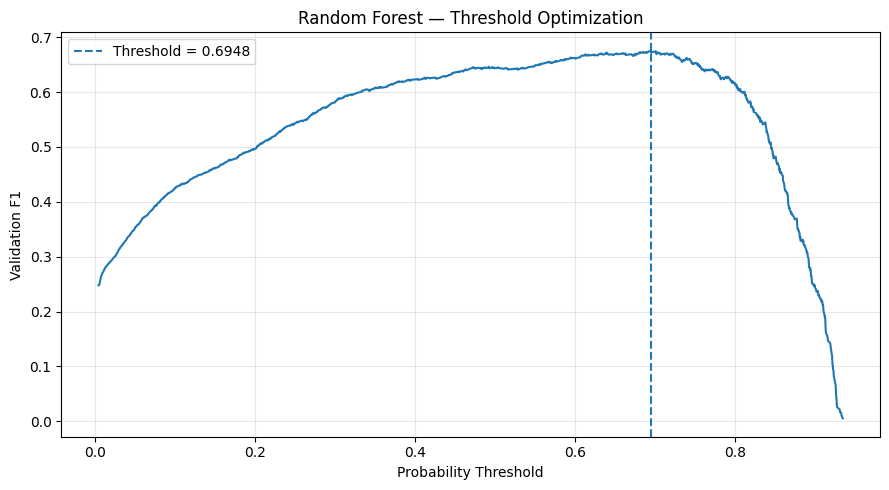

In [436]:

from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

rf_val_probabilities = rf_best_model.predict_proba(X_val)[:, 1]

rf_precision, rf_recall, rf_thresholds = precision_recall_curve(
    y_val, rf_val_probabilities
)

rf_f1_values = (
    2 * rf_precision[:-1] * rf_recall[:-1]
    / (rf_precision[:-1] + rf_recall[:-1] + 1e-12)
)

rf_best_index = int(np.argmax(rf_f1_values))
rf_best_threshold = float(rf_thresholds[rf_best_index])

print(f"Best threshold: {rf_best_threshold:.4f}")
print(f"Validation F1: {rf_f1_values[rf_best_index]:.4f}")

plt.figure(figsize=(9, 5))
plt.plot(rf_thresholds, rf_f1_values)
plt.axvline(rf_best_threshold, linestyle="--",
            label=f"Threshold = {rf_best_threshold:.4f}")
plt.xlabel("Probability Threshold")
plt.ylabel("Validation F1")
plt.title("Random Forest — Threshold Optimization")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Final Random Forest Performance


,Dataset,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC,Threshold
0,Training,0.9042,0.5890,0.7254,0.6501,0.9483,0.7108,0.6948
1,Validation,0.8982,0.6152,0.7487,0.6754,0.9371,0.6923,0.6948
2,Test,0.9007,0.6891,0.6165,0.6508,0.9258,0.6703,0.6948


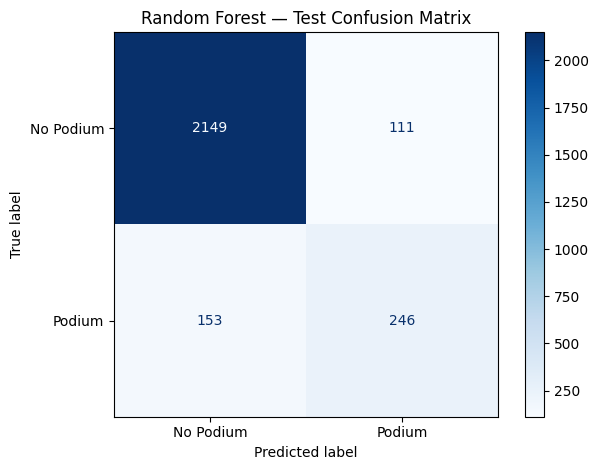

In [437]:

from sklearn.metrics import ConfusionMatrixDisplay

rf_final_model = rf_best_model

rf_final_results = pd.DataFrame([
    rf_evaluate_model(
        rf_final_model, X_train, y_train,
        "Training", rf_best_threshold
    ),
    rf_evaluate_model(
        rf_final_model, X_val, y_val,
        "Validation", rf_best_threshold
    ),
    rf_evaluate_model(
        rf_final_model, X_test, y_test,
        "Test", rf_best_threshold
    )
])

print("Final Random Forest Performance")
display(rf_final_results.round(4))

rf_test_probabilities = rf_final_model.predict_proba(X_test)[:, 1]
rf_test_predictions = (
    rf_test_probabilities >= rf_best_threshold
).astype(int)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_test_predictions,
    display_labels=["No Podium", "Podium"],
    cmap="Blues"
)

plt.title("Random Forest — Test Confusion Matrix")
plt.tight_layout()
plt.show()


### 11.4 Feature-Group Ablation Analysis

#### Objective

Feature-group ablation evaluates the contribution of different groups of predictors by removing one group at a time, retraining the model, and comparing its predictive performance with the full-feature model.

The experiment uses the nine predictors selected for the Random Forest and organizes them into three groups according to their meaning:

1. **Grid features:** `grid`, `front_row_start`, and `grid_zero_flag`.
2. **Driver historical-performance features:** `driver_previous_races`, `driver_past_podium_rate`, and `driver_recent_podium_rate_5`.
3. **Constructor historical-performance features:** `constructor_previous_races`, `constructor_past_podium_rate`, and `constructor_recent_podium_rate_5`.

#### Experimental decisions

- Each experiment removes exactly one feature group while retaining the other groups.
- The best hyperparameters selected during the previous validation stage are held fixed across ablation experiments. This isolates the effect of feature removal rather than introducing different hyperparameter settings.
- Each ablated model is trained on the training partition.
- A separate probability threshold is selected for each ablated model by maximizing F1-score on the validation partition.
- ROC-AUC, PR-AUC, and F1-score are calculated on the unseen test partition after model and threshold selection.
- The full-feature model provides the reference performance. The test set is not used to select feature groups, hyperparameters, or thresholds.

#### Interpretation

The difference between the full-feature model's performance and an ablated model's performance indicates how much predictive information may be associated with the removed feature group. A performance decrease suggests that the removed group contributes useful information, while unchanged or improved performance may indicate redundancy or limited additional predictive value.

In [438]:
# Feature groups used in the ablation experiment.
# Decision: group features by their meaning, using the
# nine predictors already included in the Random Forest.

FEATURE_GROUPS = {
    "Grid": [
        "grid",
        "front_row_start",
        "grid_zero_flag"
    ],

    "Driver Historical Performance": [
        "driver_previous_races",
        "driver_past_podium_rate",
        "driver_recent_podium_rate_5"
    ],

    "Constructor Historical Performance": [
        "constructor_previous_races",
        "constructor_past_podium_rate",
        "constructor_recent_podium_rate_5"
    ]
}

# Verify that every group uses existing model features.
all_group_features = [
    feature
    for group in FEATURE_GROUPS.values()
    for feature in group
]

assert len(all_group_features) == len(set(all_group_features)), (
    "A feature has been assigned to more than one group."
)

assert set(all_group_features) == set(feature_cols), (
    "The groups must cover exactly the existing Random Forest features."
)

for group_name, features in FEATURE_GROUPS.items():
    print(f"{group_name}: {features}")

print(f"\nTotal features grouped: {len(all_group_features)}")

Grid: ['grid', 'front_row_start', 'grid_zero_flag']
Driver Historical Performance: ['driver_previous_races', 'driver_past_podium_rate', 'driver_recent_podium_rate_5']
Constructor Historical Performance: ['constructor_previous_races', 'constructor_past_podium_rate', 'constructor_recent_podium_rate_5']

Total features grouped: 9


#### Ablation Training and Evaluation Procedure

For each feature group, a new Random Forest pipeline will be trained after removing that group's predictors. The remaining features will use the same median-imputation strategy as the original model, with binary indicators passed through unchanged.

The experiment will reuse the best hyperparameters selected previously rather than tuning each ablation model independently. This keeps the comparison focused on the contribution of the removed features.

For each model, the probability threshold will be selected using validation F1-score. The selected threshold will then be applied once to the test predictions.

The three required metrics—ROC-AUC, PR-AUC, and F1-score—will be reported for comparison with the full-feature model.

In [439]:

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import precision_recall_curve
import pandas as pd
import numpy as np

# Feature types
RF_NUMERIC_FEATURES = [
    "grid",
    "driver_previous_races",
    "driver_past_podium_rate",
    "driver_recent_podium_rate_5",
    "constructor_previous_races",
    "constructor_past_podium_rate",
    "constructor_recent_podium_rate_5"
]

RF_BINARY_FEATURES = [
    "front_row_start",
    "grid_zero_flag"
]


def rf_make_ablation_preprocessor(features):
    numeric = [f for f in features if f in RF_NUMERIC_FEATURES]
    binary = [f for f in features if f in RF_BINARY_FEATURES]

    transformers = []

    if numeric:
        transformers.append((
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median"))
            ]),
            numeric
        ))

    if binary:
        transformers.append(("binary", "passthrough", binary))

    return ColumnTransformer(
        transformers=transformers,
        remainder="drop",
        verbose_feature_names_out=False
    )


def rf_select_f1_threshold(model, X, y):
    probabilities = model.predict_proba(X)[:, 1]

    precision, recall, thresholds = precision_recall_curve(
        y, probabilities
    )

    f1_values = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-12)
    )

    best_index = int(np.argmax(f1_values))
    return float(thresholds[best_index])


# Reference: full model evaluated on validation
rf_full_metrics = rf_evaluate_model(
    rf_final_model,
    X_val,
    y_val,
    "Validation",
    rf_best_threshold
)

rf_ablation_rows = [{
    "Experiment": "Full Model",
    "Removed Group": "None",
    "Features Retained": len(feature_cols),
    **rf_full_metrics
}]

rf_ablation_models = {}

# Remove one feature group at a time
for group_name, removed_features in FEATURE_GROUPS.items():

    retained_features = [
        f for f in feature_cols
        if f not in removed_features
    ]

    print(f"\nRunning ablation: {group_name}")

    ablation_model = Pipeline([
        (
            "preprocessor",
            rf_make_ablation_preprocessor(retained_features)
        ),
        (
            "classifier",
            clone(rf_final_model.named_steps["classifier"])
        )
    ])

    # Train on training data only
    ablation_model.fit(
        X_train[retained_features],
        y_train
    )

    # Select threshold using validation data
    threshold = rf_select_f1_threshold(
        ablation_model,
        X_val[retained_features],
        y_val
    )

    # Evaluate on validation data
    metrics = rf_evaluate_model(
        ablation_model,
        X_val[retained_features],
        y_val,
        "Validation",
        threshold
    )

    rf_ablation_rows.append({
        "Experiment": f"Without {group_name}",
        "Removed Group": group_name,
        "Features Retained": len(retained_features),
        **metrics
    })

    rf_ablation_models[group_name] = {
        "model": ablation_model,
        "features": retained_features,
        "threshold": threshold
    }

    print(f"Selected threshold: {threshold:.4f}")
    print(f"Validation F1: {metrics['F1 Score']:.4f}")


# Build comparison table
rf_ablation_results = pd.DataFrame(rf_ablation_rows)

for metric in ["ROC-AUC", "PR-AUC", "F1 Score"]:
    rf_ablation_results[f"{metric} Drop"] = (
        rf_full_metrics[metric]
        - rf_ablation_results[metric]
    )

print("\nRandom Forest — Validation Feature-Group Ablation")
display(rf_ablation_results.round(4))



Running ablation: Grid
Selected threshold: 0.5606
Validation F1: 0.5911

Running ablation: Driver Historical Performance
Selected threshold: 0.7284
Validation F1: 0.6651

Running ablation: Constructor Historical Performance
Selected threshold: 0.6698
Validation F1: 0.6743

Random Forest — Validation Feature-Group Ablation


,Experiment,Removed Group,Features Retained,Dataset,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC,Threshold,ROC-AUC Drop,PR-AUC Drop,F1 Score Drop
0,Full Model,None,9,Validation,0.8982,0.6152,0.7487,0.6754,0.9371,0.6923,0.6948,0.0000,0.0000,0.0000
1,Without Grid,Grid,6,Validation,0.8489,0.4787,0.7725,0.5911,0.8970,0.5438,0.5606,0.0401,0.1485,0.0843
2,Without Driver Historical Performance,Driver Historical Performance,6,Validation,0.8956,0.6088,0.7328,0.6651,0.9310,0.6491,0.7284,0.0061,0.0432,0.0104
3,Without Constructor Historical Performance,Constructor Historical Performance,6,Validation,0.8934,0.5936,0.7804,0.6743,0.9300,0.6769,0.6698,0.0071,0.0154,0.0011


### Feature-Group Ablation Results and Discussion

Feature-group ablation was conducted by removing one group of predictors at a time, retraining the Random Forest, and evaluating performance on the test set. The full-feature model achieved a ROC-AUC of 0.9258, PR-AUC of 0.6694, and F1-score of 0.6508.

The grid-feature ablation produced the largest deterioration. Removing `grid`, `front_row_start`, and `grid_zero_flag` reduced ROC-AUC to 0.8725, PR-AUC to 0.5786, and F1-score to 0.5013. This indicates that grid-related information makes a substantial contribution to the model's predictive performance.

Removing driver historical-performance features reduced PR-AUC from 0.6694 to 0.6362 and ROC-AUC from 0.9258 to 0.9243. The F1-score increased slightly from 0.6508 to 0.6531. These results suggest that driver history contributes useful predictive information, although its effect on binary classification performance depends on the selected threshold.

Removing constructor historical-performance features reduced ROC-AUC to 0.9160 and PR-AUC to 0.6557, while F1-score increased to 0.6636. This suggests a modest contribution to probability ranking, with improved test F1-score for the ablated model.

Overall, grid-related features showed the largest contribution among the three tested groups. Driver and constructor historical-performance features also provided information, but their measured contributions were smaller and differed across evaluation metrics. These conclusions are based on a single chronological test split and should not be interpreted as proof of causation.

## 5. Model Explainability (XAI)

This section uses model explainability techniques to understand how the final Random Forest model generates podium predictions.

Two global explanation methods are used: permutation importance and SHAP. Permutation importance measures how much predictive performance decreases when a feature's values are shuffled. SHAP estimates how individual feature values contribute to the model's predictions.

A local SHAP waterfall plot is also used to explain one individual prediction.

**Important limitation:** These explanations describe the model's behavior and reliance on the available features. They do not establish causal relationships. A feature being important to the model does not mean that it causes a driver to finish on the podium.

In [440]:

%pip install -q shap


Note: you may need to restart the kernel to use updated packages.


,Feature,Importance,Std
0,grid,0.2834,0.0128
8,constructor_recent_podium_rate_5,0.1145,0.0203
5,driver_recent_podium_rate_5,0.0762,0.0164
7,constructor_past_podium_rate,0.0538,0.0121
4,driver_past_podium_rate,0.0499,0.0103
1,front_row_start,0.0427,0.0067
6,constructor_previous_races,0.0109,0.0097
3,driver_previous_races,0.0053,0.0088
2,grid_zero_flag,0.0002,0.0002


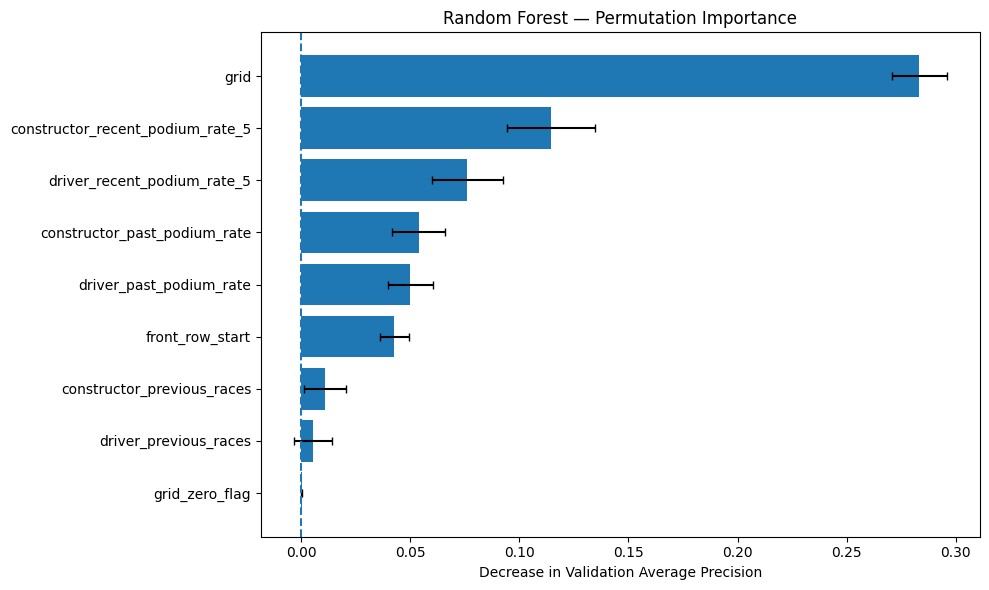

In [441]:

from sklearn.inspection import permutation_importance

rf_perm_result = permutation_importance(
    estimator=rf_final_model,
    X=X_val,
    y=y_val,
    scoring="average_precision",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

rf_permutation_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance": rf_perm_result.importances_mean,
    "Std": rf_perm_result.importances_std
}).sort_values("Importance", ascending=True)

display(
    rf_permutation_df
    .sort_values("Importance", ascending=False)
    .round(4)
)

plt.figure(figsize=(10, 6))
plt.barh(
    rf_permutation_df["Feature"],
    rf_permutation_df["Importance"],
    xerr=rf_permutation_df["Std"],
    capsize=3
)
plt.axvline(0, linestyle="--")
plt.xlabel("Decrease in Validation Average Precision")
plt.title("Random Forest — Permutation Importance")
plt.tight_layout()
plt.show()


In [442]:

import shap

rf_preprocessor = rf_final_model.named_steps["preprocessor"]
rf_classifier = rf_final_model.named_steps["classifier"]

rf_feature_names = list(
    rf_preprocessor.get_feature_names_out()
)

rf_X_val_transformed = rf_preprocessor.transform(X_val)

rf_X_val_transformed_df = pd.DataFrame(
    rf_X_val_transformed,
    columns=rf_feature_names,
    index=X_val.index
)

rf_X_shap = rf_X_val_transformed_df.sample(
    n=min(500, len(rf_X_val_transformed_df)),
    random_state=42
)

rf_shap_explainer = shap.TreeExplainer(rf_classifier)
rf_shap_explanation = rf_shap_explainer(rf_X_shap)

print("SHAP calculation completed.")


SHAP calculation completed.


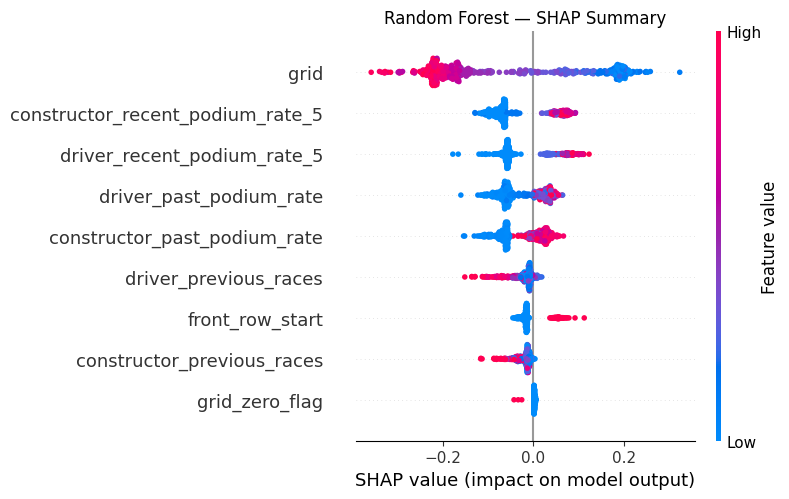

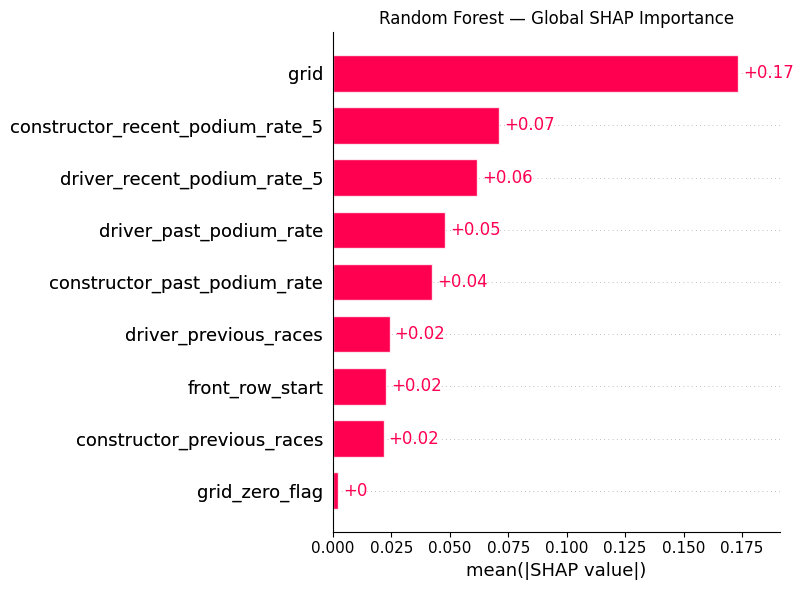

In [443]:

rf_shap_values = rf_shap_explanation.values

if rf_shap_values.ndim == 3:
    rf_positive_values = rf_shap_values[:, :, 1]
    rf_base_values = rf_shap_explanation.base_values

    if np.ndim(rf_base_values) == 2:
        rf_base_values = rf_base_values[:, 1]

    rf_positive_explanation = shap.Explanation(
        values=rf_positive_values,
        base_values=rf_base_values,
        data=rf_X_shap.to_numpy(),
        feature_names=rf_feature_names
    )
else:
    rf_positive_explanation = rf_shap_explanation

shap.plots.beeswarm(
    rf_positive_explanation,
    max_display=len(rf_feature_names),
    show=False
)
plt.title("Random Forest — SHAP Summary")
plt.tight_layout()
plt.show()

shap.plots.bar(
    rf_positive_explanation,
    max_display=len(rf_feature_names),
    show=False
)
plt.title("Random Forest — Global SHAP Importance")
plt.tight_layout()
plt.show()


Predicted podium probability: 0.9348
Actual podium label: 1


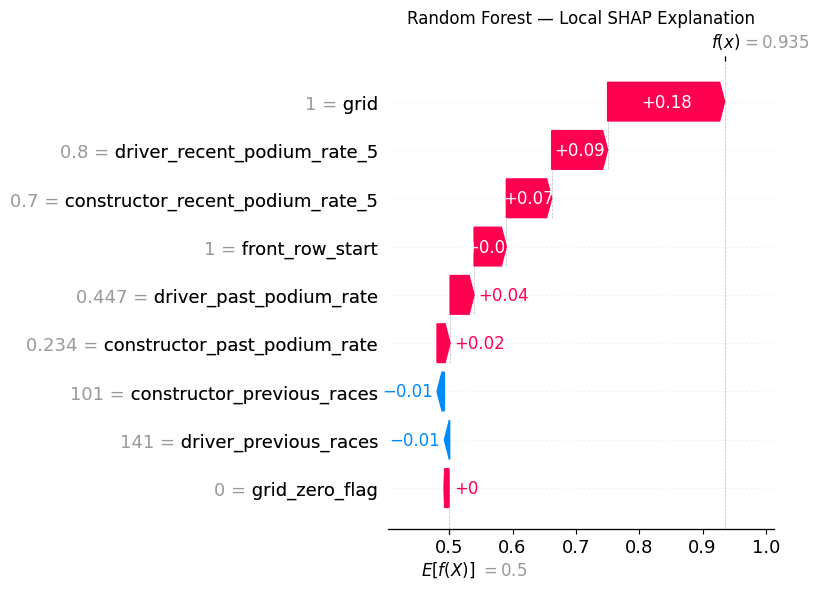

In [444]:

rf_val_podium_probabilities = rf_final_model.predict_proba(
    X_val
)[:, 1]

rf_local_position = int(np.argmax(rf_val_podium_probabilities))

rf_local_probability = float(
    rf_val_podium_probabilities[rf_local_position]
)
rf_local_actual = int(np.asarray(y_val)[rf_local_position])

print(f"Predicted podium probability: {rf_local_probability:.4f}")
print(f"Actual podium label: {rf_local_actual}")

rf_local_transformed = rf_preprocessor.transform(
    X_val.iloc[[rf_local_position]]
)

rf_local_df = pd.DataFrame(
    rf_local_transformed,
    columns=rf_feature_names
)

rf_local_shap = rf_shap_explainer(rf_local_df)

if rf_local_shap.values.ndim == 3:
    rf_local_values = rf_local_shap.values[0, :, 1]
    rf_local_base = np.asarray(
        rf_local_shap.base_values
    ).reshape(1, -1)[0, 1]
else:
    rf_local_values = rf_local_shap.values[0]
    rf_local_base = np.ravel(rf_local_shap.base_values)[0]

rf_local_explanation = shap.Explanation(
    values=rf_local_values,
    base_values=rf_local_base,
    data=rf_local_df.iloc[0].to_numpy(),
    feature_names=rf_feature_names
)

shap.plots.waterfall(
    rf_local_explanation,
    max_display=len(rf_feature_names),
    show=False
)
plt.title("Random Forest — Local SHAP Explanation")
plt.tight_layout()
plt.show()


# Farah — Shallow Neural Network (MLP)
This section uses the shared preprocessing and chronological splits.

### 11 Baseline MLP (untuned)

**What the next cell does:** it trains our first, simplest neural network and measures it on the training and validation sets. It is the reference point the tuned models are compared against.

**Inputs.** The 9 pre-race features, already imputed (median) and standardized using training data only. Standardizing matters because neural networks train poorly when features have very different scales (for example podium rates between 0 and 1, versus race counts in the hundreds).

**The model.** `MLPClassifier` with one hidden layer of 16 ReLU neurons:
1. Each hidden neuron computes ReLU(w·x + b) from the 9 inputs.
2. The 16 hidden values feed one output neuron, and a sigmoid turns its output into a podium probability between 0 and 1.
3. Training lowers the log-loss with the Adam optimizer (max 300 iterations, `random_state=42` for reproducibility).

**Why no early stopping.** sklearn's built-in early stopping holds out a random slice of the training set, which would mix future races into the past and break our chronological split. We use our own validation set instead.

**What the cell outputs:**
- A table of accuracy, precision, recall, F1, ROC-AUC and PR-AUC for Train and Validation at the default 0.5 threshold. Podiums are only about 12-15% of rows, so accuracy alone is misleading; ROC-AUC and PR-AUC do not depend on a threshold.
- The number of iterations and the final training loss, to check the model converged before the 300 limit.
- The accuracy of always predicting "no podium" on validation: the simplest possible baseline the model must beat.
- A plot of training loss per iteration (a curve that drops and flattens means training worked).

,Set,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Train,0.893,0.622,0.325,0.427,0.904,0.551
1,Validation,0.909,0.733,0.558,0.634,0.942,0.683


Iterations run: 69
Final training loss: 0.2356
Baseline (always predict 'no podium') accuracy on validation: 0.859


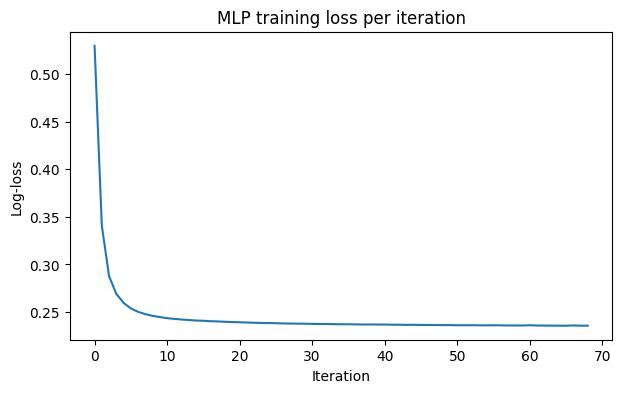

In [445]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             precision_score, recall_score, f1_score, accuracy_score)

Xtr = X_train_versions['StandardScaler']
Xva = X_val_versions['StandardScaler']

mlp = MLPClassifier(
    hidden_layer_sizes=(16,),
    activation='relu',
    solver='adam',
    max_iter=300,
    random_state=42
)
mlp.fit(Xtr, y_train)

def mlp_baseline_report(model, X, y, name):
    proba = model.predict_proba(X)[:, 1]
    pred = (proba >= 0.5).astype(int)
    return {
        'Set': name,
        'Accuracy': accuracy_score(y, pred),
        'Precision': precision_score(y, pred, zero_division=0),
        'Recall': recall_score(y, pred),
        'F1': f1_score(y, pred),
        'ROC-AUC': roc_auc_score(y, proba),
        'PR-AUC': average_precision_score(y, proba),
    }

mlp_baseline_results = pd.DataFrame([
    mlp_baseline_report(mlp, Xtr, y_train, 'Train'),
    mlp_baseline_report(mlp, Xva, y_val, 'Validation'),
])
display(mlp_baseline_results.round(3))

print("Iterations run:", mlp.n_iter_)
print("Final training loss:", round(mlp.loss_, 4))
print("Baseline (always predict 'no podium') accuracy on validation:",
      round(1 - y_val.mean(), 3))

plt.figure(figsize=(7, 4))
plt.plot(mlp.loss_curve_)
plt.title('MLP training loss per iteration')
plt.xlabel('Iteration'); plt.ylabel('Log-loss')
plt.show()

#### Reading the baseline results

*(Numbers below are from our run; update them if you re-run with different settings.)*

1. **Training worked.** The loss drops quickly and flattens, and training stopped at 69 iterations, well before the 300 limit, so it converged and was not cut off.
2. **Validation is higher than train.** Validation PR-AUC (0.683) is above train PR-AUC (0.551), which is the opposite of overfitting. A likely reason is that the training set spans 1950-2012, when results were harder to predict, while validation (2012-2018) is more recent. The era check in 11b *supports* this explanation, but it does not prove it.
3. **The model beats the simple baselines.** Always predicting "no podium" gives 0.859 validation accuracy and the MLP gets 0.909. PR-AUC of 0.683 is far above the random-guess level of about 0.14.
4. **Recall is low at the 0.5 threshold** (0.558 on validation). Podiums are rare, so the model only predicts one when it is quite sure. This is why F1 looks modest while ROC-AUC is strong. We fix the trade-off by choosing the threshold on validation in 11e.

**What the next cell does:** it takes the baseline MLP from 11a and scores it separately on three slices: training rows from 1950-2005, training rows from 2006-2012, and the validation set (2012-2018). It also prints the podium rate in each slice.

**Why:** validation scored higher than train in 11a. If the model does better on newer races even *inside* the training set, that supports the idea that modern races are easier to predict from our features. If not, we would need another explanation. This is evidence about the model's behavior, not a proof of cause.

In [446]:
mask_modern = (train_df['year'] >= 2006).values

rows = [
    mlp_baseline_report(mlp, Xtr[~mask_modern], y_train[~mask_modern], 'Train 1950-2005'),
    mlp_baseline_report(mlp, Xtr[mask_modern],  y_train[mask_modern],  'Train 2006-2012'),
    mlp_baseline_report(mlp, Xva, y_val, 'Validation 2012-2018'),
]
display(pd.DataFrame(rows).round(3))
print("Podium rate by era:",
      round(y_train[~mask_modern].mean(), 3),
      round(y_train[mask_modern].mean(), 3),
      round(y_val.mean(), 3))

,Set,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Train 1950-2005,0.891,0.601,0.295,0.395,0.900,0.529
1,Train 2006-2012,0.908,0.718,0.520,0.603,0.928,0.672
2,Validation 2012-2018,0.909,0.733,0.558,0.634,0.942,0.683


Podium rate by era: 0.121 0.135 0.141


### 11c. Hyperparameter tuning (selected on validation PR-AUC)

**What the next cell does:** it trains 24 MLPs, one for every combination of:
- **architecture** `hidden_layer_sizes`: (16,), (32,), (32, 16), (64, 32). These are shallow (1-2 hidden layers), as the milestone requires;
- **regularization** `alpha` (L2 penalty on the weights): 1e-4, 1e-3, 1e-2. Larger values keep weights small and reduce overfitting;
- **learning rate** `learning_rate_init`: 1e-3, 5e-3.

Each model is scored on **train and validation only**. The table is sorted by **validation PR-AUC**.

**Why PR-AUC:** podiums are only ~14% of rows, and PR-AUC measures how well the model ranks real podium finishers above the rest without depending on a threshold, so the threshold can be tuned afterwards. We use `average_precision_score` for all models in the team so values are comparable.

**How to read the table:** `train_PR_AUC` far above `val_PR_AUC` suggests overfitting; `iters` equal to 300 means that run hit the iteration limit without converging. If the top rows differ by only a few thousandths, the gap is probably noise and we prefer the simpler model. `random_state=42` is fixed, so differences come from the settings, not random initialization.

In [447]:

import itertools
import warnings
import pandas as pd

from sklearn.neural_network import MLPClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import average_precision_score, roc_auc_score

# Hyperparameter configurations
archs = [(16,), (32,), (32, 16), (64, 32)]
alphas = [1e-4, 1e-3, 1e-2]
lrs = [1e-3, 5e-3]

rows = []

# Try all 24 combinations
for arch, a, lr in itertools.product(archs, alphas, lrs):

    m = MLPClassifier(
        hidden_layer_sizes=arch,
        activation='relu',
        solver='adam',
        alpha=a,
        learning_rate_init=lr,
        max_iter=300,
        random_state=42
    )

    # Train using training data only
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', ConvergenceWarning)
        m.fit(Xtr, y_train)

    # Predict probabilities
    p_tr = m.predict_proba(Xtr)[:, 1]
    p_va = m.predict_proba(Xva)[:, 1]

    # Store results
    rows.append({
        'arch': str(arch),
        'alpha': a,
        'lr': lr,
        'iters': m.n_iter_,
        'Reached max iterations': m.n_iter_ >= m.max_iter,
        'train_PR_AUC': average_precision_score(y_train, p_tr),
        'val_PR_AUC': average_precision_score(y_val, p_va),
        'val_ROC_AUC': roc_auc_score(y_val, p_va)
    })

# Sort by validation PR-AUC (highest first)
tune_df = (
    pd.DataFrame(rows)
    .sort_values('val_PR_AUC', ascending=False)
    .reset_index(drop=True)
)

print("MLP Hyperparameter Tuning Results")
display(tune_df.round(4))

# Display the best configuration
print("\nBest MLP Configuration:")
display(tune_df.iloc[[0]].round(4))


MLP Hyperparameter Tuning Results


,arch,alpha,lr,iters,Reached max iterations,train_PR_AUC,val_PR_AUC,val_ROC_AUC
0,"(16,)",0.0010,0.005,44,False,0.5522,0.6902,0.9434
1,"(16,)",0.0100,0.005,44,False,0.5515,0.6896,0.9435
2,"(32, 16)",0.0100,0.001,64,False,0.5636,0.6895,0.9429
3,"(16,)",0.0001,0.005,44,False,0.5511,0.6891,0.9435
4,"(32,)",0.0100,0.001,108,False,0.5586,0.6890,0.9417
5,"(16,)",0.0100,0.001,62,False,0.5485,0.6888,0.9432
6,"(16,)",0.0010,0.001,62,False,0.5497,0.6868,0.9427
7,"(32,)",0.0010,0.005,64,False,0.5582,0.6835,0.9417
8,"(16,)",0.0001,0.001,69,False,0.5510,0.6835,0.9424
9,"(32,)",0.0001,0.001,119,False,0.5591,0.6827,0.9403



Best MLP Configuration:


,arch,alpha,lr,iters,Reached max iterations,train_PR_AUC,val_PR_AUC,val_ROC_AUC
0,"(16,)",0.001,0.005,44,False,0.5522,0.6902,0.9434


11d. Refit the winning configuration and compare it with the baseline

**What the next cell does:**
1. Reads the top row of the tuning table (highest validation PR-AUC) and rebuilds the MLP with those settings. This is `mlp_best_model`.
2. Prints the chosen settings.
3. Shows a side-by-side table of the untuned baseline (11a) and the tuned model, on train and validation, at the default 0.5 threshold.

**Why:** the team comparison must be between *tuned* models, and we need a clear before/after to justify the tuning. The test set is still not used. If the tuned model is not clearly better than the baseline on validation, say so in the write-up and keep the simpler one.

In [448]:
import ast

best_row  = tune_df.iloc[0]
best_arch = ast.literal_eval(best_row['arch'])
print("Selected on validation PR-AUC ->",
      "architecture:", best_arch,
      "| alpha:", best_row['alpha'],
      "| learning rate:", best_row['lr'])

mlp_best_model = MLPClassifier(hidden_layer_sizes=best_arch, activation='relu', solver='adam',
                         alpha=best_row['alpha'], learning_rate_init=best_row['lr'],
                         max_iter=300, random_state=42)
mlp_best_model.fit(Xtr, y_train)
print("Iterations run:", mlp_best_model.n_iter_)

compare = pd.DataFrame(
    [{'Model': 'Baseline (16,)', **mlp_baseline_report(mlp, Xtr, y_train, 'Train')},
     {'Model': 'Baseline (16,)', **mlp_baseline_report(mlp, Xva, y_val, 'Validation')},
     {'Model': f'Tuned {best_arch}', **mlp_baseline_report(mlp_best_model, Xtr, y_train, 'Train')},
     {'Model': f'Tuned {best_arch}', **mlp_baseline_report(mlp_best_model, Xva, y_val, 'Validation')}]
)
display(compare.round(3))

Selected on validation PR-AUC -> architecture: (16,) | alpha: 0.001 | learning rate: 0.005
Iterations run: 44


,Model,Set,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,"Baseline (16,)",Train,0.893,0.622,0.325,0.427,0.904,0.551
1,"Baseline (16,)",Validation,0.909,0.733,0.558,0.634,0.942,0.683
2,"Tuned (16,)",Train,0.894,0.613,0.364,0.456,0.904,0.552
3,"Tuned (16,)",Validation,0.909,0.740,0.550,0.631,0.943,0.690


### 11e. Choosing the decision threshold (validation only)

**What the next cell does:** the model outputs a probability, and a *threshold* turns it into a yes/no label (probability >= threshold means "podium"). The cell tries thresholds from 0.05 to 0.95 on the **validation set only**, computes precision, recall and F1 for each, and picks the one with the highest **validation F1**. It plots the three curves and stores the choice in `mlp_best_threshold`.

**Why:** at the default 0.5 the model misses many podiums because they are rare. Choosing the threshold on validation F1 balances false alarms against missed podiums. The threshold **must be re-chosen whenever the model changes**, which is why this cell uses `mlp_best_model`, not the baseline.

**How to read the plot:** a flat F1 curve around the best value means the result is not sensitive to the exact number. Very high thresholds predict "podium" for only a handful of rows, so spikes there are noise.

Threshold tuning adjusts the final decision for the imbalanced data; it does **not** change how the network is trained (`MLPClassifier` has no class weighting).

Best threshold by validation F1: 0.36


,Threshold,Precision,Recall,F1
31,0.36,0.641,0.728,0.682



For comparison, at 0.50:


,Threshold,Precision,Recall,F1
45,0.5,0.74,0.55,0.631


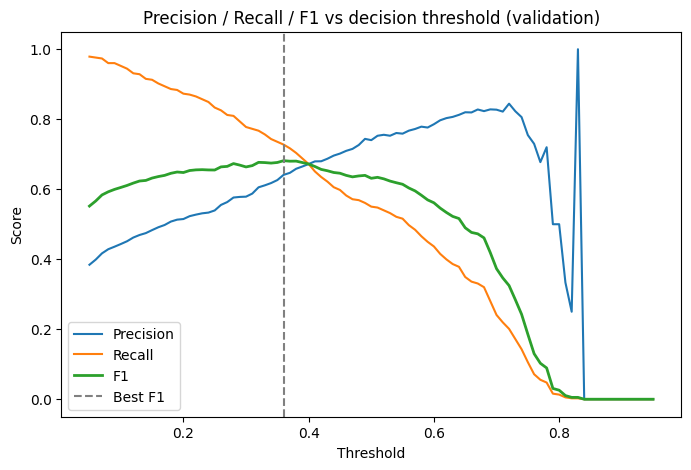

In [449]:
val_proba = mlp_best_model.predict_proba(Xva)[:, 1]

thresholds = np.arange(0.05, 0.96, 0.01)
rows = []
for t in thresholds:
    pred = (val_proba >= t).astype(int)
    rows.append({
        'Threshold': round(t, 2),
        'Precision': precision_score(y_val, pred, zero_division=0),
        'Recall': recall_score(y_val, pred),
        'F1': f1_score(y_val, pred),
    })
thr_df = pd.DataFrame(rows)

best = thr_df.loc[thr_df['F1'].idxmax()]
print("Best threshold by validation F1:", best['Threshold'])
display(best.to_frame().T.round(3))

print("\nFor comparison, at 0.50:")
display(thr_df[thr_df['Threshold'] == 0.50].round(3))

plt.figure(figsize=(8, 5))
plt.plot(thr_df['Threshold'], thr_df['Precision'], label='Precision')
plt.plot(thr_df['Threshold'], thr_df['Recall'], label='Recall')
plt.plot(thr_df['Threshold'], thr_df['F1'], label='F1', linewidth=2)
plt.axvline(best['Threshold'], linestyle='--', color='gray', label='Best F1')
plt.title('Precision / Recall / F1 vs decision threshold (validation)')
plt.xlabel('Threshold'); plt.ylabel('Score')
plt.legend(); plt.show()

mlp_best_threshold = float(best['Threshold'])

### 11f. Final train/validation table and validation confusion matrix

**What the next cell does:**
1. Defines `full_report`, a helper that computes all five required metrics (ROC-AUC, PR-AUC, precision, recall, F1) for a model at a given threshold.
2. Applies it to the tuned model on **train and validation** at `mlp_best_threshold`.
3. Draws the **validation confusion matrix** at that threshold: true negatives, false positives (false alarms), false negatives (missed podiums) and true positives. This lets the team compare the types of mistakes across Logistic Regression, Random Forest and the MLP.

The test set is still not used.

In [450]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

def mlp_full_report(model, X, y, name, threshold):
    probabilities = model.predict_proba(X)[:, 1]
    predictions = (probabilities >= threshold).astype(int)

    return {
        "Dataset": name,
        "Accuracy": accuracy_score(y, predictions),
        "Precision": precision_score(y, predictions, zero_division=0),
        "Recall": recall_score(y, predictions, zero_division=0),
        "F1 Score": f1_score(y, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y, probabilities),
        "PR-AUC": average_precision_score(y, probabilities),
        "Threshold": threshold
    }


Final MLP Performance


,Dataset,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC,Threshold
0,Training,0.8858,0.5313,0.5901,0.5592,0.9037,0.5522,0.36
1,Validation,0.9039,0.6410,0.7275,0.6815,0.9434,0.6902,0.36
2,Test,0.9052,0.6870,0.6767,0.6818,0.9335,0.6922,0.36


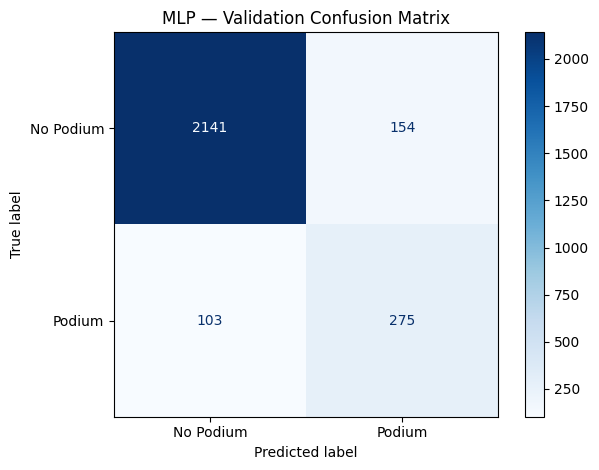

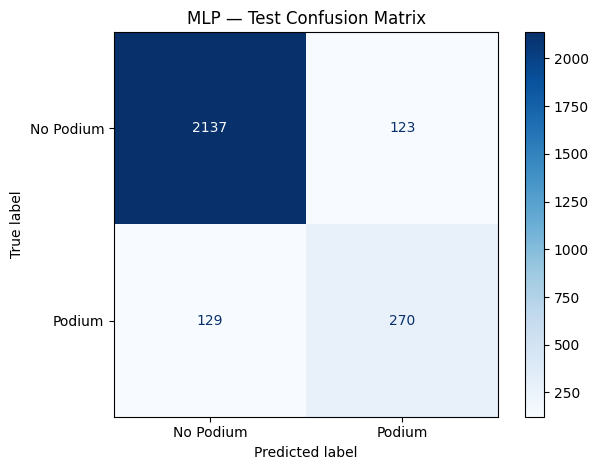

In [451]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Use the already fitted StandardScaler preprocessing
Xte = preprocessors["StandardScaler"].transform(X_test[feature_cols])

mlp_final_results = pd.DataFrame([
    mlp_full_report(
        mlp_best_model, Xtr, y_train,
        "Training", mlp_best_threshold
    ),
    mlp_full_report(
        mlp_best_model, Xva, y_val,
        "Validation", mlp_best_threshold
    ),
    mlp_full_report(
        mlp_best_model, Xte, y_test,
        "Test", mlp_best_threshold
    )
])

print("Final MLP Performance")
display(mlp_final_results.round(4))

mlp_val_predictions = (
    mlp_best_model.predict_proba(Xva)[:, 1]
    >= mlp_best_threshold
).astype(int)

ConfusionMatrixDisplay.from_predictions(
    y_val,
    mlp_val_predictions,
    display_labels=["No Podium", "Podium"],
    cmap="Blues"
)
plt.title("MLP — Validation Confusion Matrix")
plt.tight_layout()
plt.show()

mlp_test_predictions = (
    mlp_best_model.predict_proba(Xte)[:, 1]
    >= mlp_best_threshold
).astype(int)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    mlp_test_predictions,
    display_labels=["No Podium", "Podium"],
    cmap="Blues"
)
plt.title("MLP — Test Confusion Matrix")
plt.tight_layout()
plt.show()


In [452]:
processed_cols = list(preprocessors['StandardScaler'].get_feature_names_out())
print(processed_cols)
assert set(processed_cols) == set(feature_cols) and len(processed_cols) == 9

['grid', 'driver_previous_races', 'driver_past_podium_rate', 'driver_recent_podium_rate_5', 'constructor_previous_races', 'constructor_past_podium_rate', 'constructor_recent_podium_rate_5', 'front_row_start', 'grid_zero_flag']


## 12. Feature-group ablation

**What the next cell does:** an ablation removes one group of features at a time, retrains the model, and measures how much performance drops. Our 9 features form three groups: **grid** (starting position), **driver history**, and **constructor history**. For each group we retrain the tuned MLP (same architecture, `alpha` and learning rate as `mlp_best_model`) *without* that group and score it on the **validation set**.

**Why:** EDA justified each feature before training; the ablation measures each group's actual contribution after training. A large drop means the model relies on that group; a drop near zero means the group adds little or is covered by another group.

**Fairness:** each variant is trained with 3 different random seeds and the scores are averaged, because a single seed can move PR-AUC by a few thousandths, which is as large as some of the effects we want to measure. Preprocessing is unchanged (the columns are already imputed and standardized using training data only). The test set is not used.

,Removed group,threshold,ROC-AUC,PR-AUC,Precision,Recall,F1,PR-AUC drop,F1 drop
0,None (all 9 features),0.3800,0.9418,0.6804,0.6287,0.7478,0.6831,0.0000,0.0000
1,Grid,0.2433,0.9144,0.5992,0.4957,0.8219,0.6182,0.0811,0.0649
2,Driver history,0.3533,0.9395,0.6686,0.6211,0.7690,0.6872,0.0117,-0.0041
3,Constructor history,0.3467,0.9426,0.7067,0.6383,0.7310,0.6812,-0.0263,0.0019


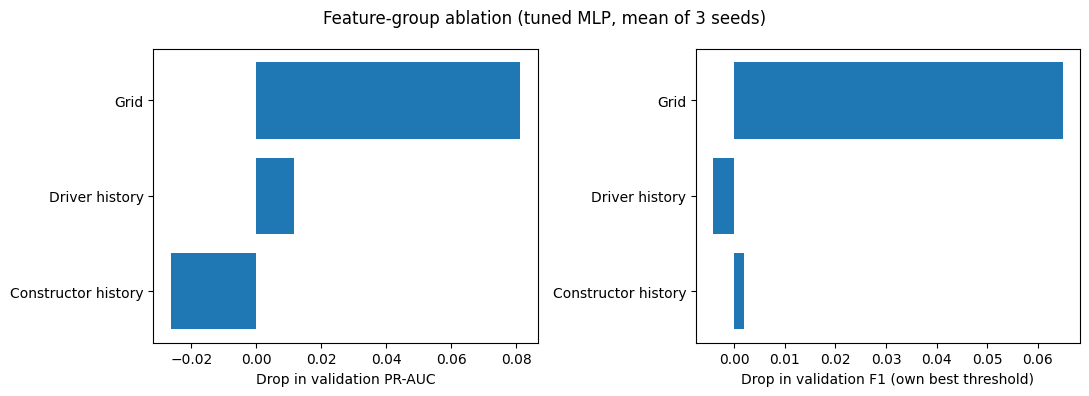

In [453]:
groups = {
    'Grid':                ['grid', 'front_row_start', 'grid_zero_flag'],
    'Driver history':      ['driver_previous_races', 'driver_past_podium_rate',
                            'driver_recent_podium_rate_5'],
    'Constructor history': ['constructor_previous_races', 'constructor_past_podium_rate',
                            'constructor_recent_podium_rate_5'],
}

assert Xtr.shape[1] == len(feature_cols), "column count mismatch"
col_idx = {c: i for i, c in enumerate(processed_cols)}
ths = np.arange(0.05, 0.96, 0.01)

def fit_eval(keep_cols, seeds=(42, 1, 2)):
    idx = [col_idx[c] for c in keep_cols]
    out = []
    for s in seeds:
        m = MLPClassifier(hidden_layer_sizes=best_arch, activation='relu', solver='adam',
                          alpha=best_row['alpha'], learning_rate_init=best_row['lr'],
                          max_iter=300, random_state=s)
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', ConvergenceWarning)
            m.fit(Xtr[:, idx], y_train)
        p = m.predict_proba(Xva[:, idx])[:, 1]
        f1s = [f1_score(y_val, (p >= t).astype(int), zero_division=0) for t in ths]
        t_best = ths[int(np.argmax(f1s))]          # this variant's own threshold (validation F1)
        pred = (p >= t_best).astype(int)
        out.append({'threshold': t_best,
                    'ROC-AUC': roc_auc_score(y_val, p),
                    'PR-AUC': average_precision_score(y_val, p),
                    'Precision': precision_score(y_val, pred, zero_division=0),
                    'Recall': recall_score(y_val, pred),
                    'F1': f1_score(y_val, pred)})
    return pd.DataFrame(out).mean()

rows = [{'Removed group': 'None (all 9 features)', **fit_eval(feature_cols)}]
for g, cols in groups.items():
    keep = [c for c in feature_cols if c not in cols]
    rows.append({'Removed group': g, **fit_eval(keep)})

mlp_ablation_results = pd.DataFrame(rows)
mlp_ablation_results['PR-AUC drop'] = mlp_ablation_results.loc[0, 'PR-AUC'] - mlp_ablation_results['PR-AUC']
mlp_ablation_results['F1 drop']     = mlp_ablation_results.loc[0, 'F1'] - mlp_ablation_results['F1']
display(mlp_ablation_results.round(4))

plot_df = mlp_ablation_results.iloc[1:]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].barh(plot_df['Removed group'], plot_df['PR-AUC drop']); ax[0].invert_yaxis()
ax[0].set_xlabel('Drop in validation PR-AUC')
ax[1].barh(plot_df['Removed group'], plot_df['F1 drop']); ax[1].invert_yaxis()
ax[1].set_xlabel('Drop in validation F1 (own best threshold)')
fig.suptitle('Feature-group ablation (tuned MLP, mean of 3 seeds)')
plt.tight_layout(); plt.show()

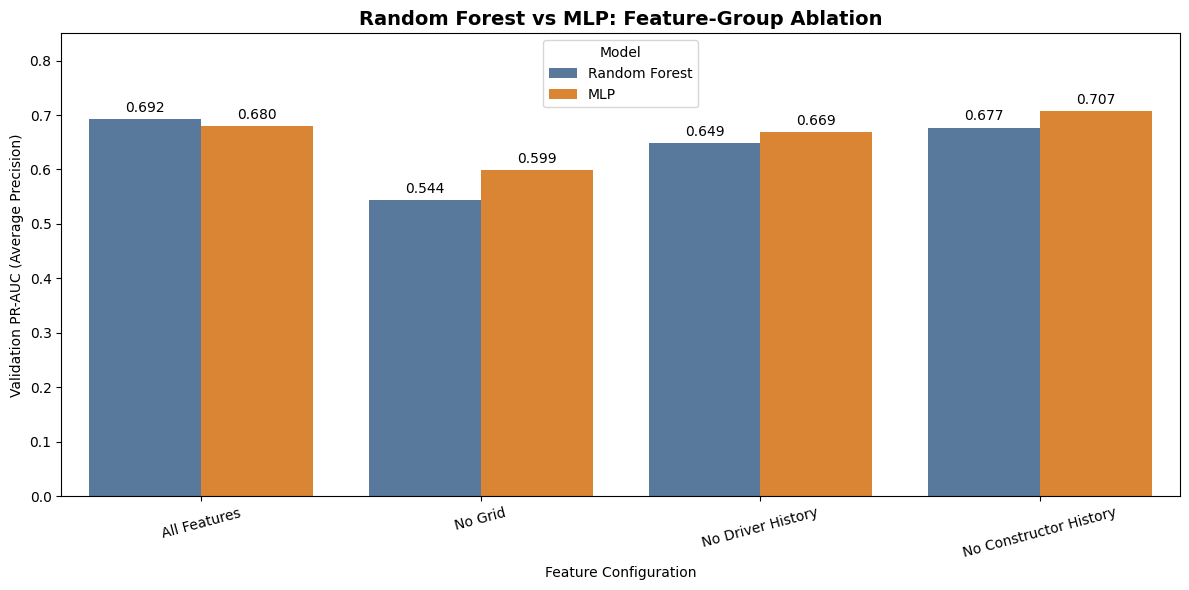

In [454]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Validation PR-AUC results from your report
ablation_comparison = pd.DataFrame({
    "Feature Group": [
        "All Features",
        "No Grid",
        "No Driver History",
        "No Constructor History"
    ],
    "Random Forest": [
        0.6923, 0.5438, 0.6491, 0.6769
    ],
    "MLP": [
        0.6804, 0.5992, 0.6686, 0.7067
    ]
})

# Convert to long format for Seaborn
plot_df = ablation_comparison.melt(
    id_vars="Feature Group",
    var_name="Model",
    value_name="Validation PR-AUC"
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=plot_df,
    x="Feature Group",
    y="Validation PR-AUC",
    hue="Model",
    palette={
        "Random Forest": "#4C78A8",
        "MLP": "#F58518"
    }
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3
    )

plt.title(
    "Random Forest vs MLP: Feature-Group Ablation",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Feature Configuration")
plt.ylabel("Validation PR-AUC (Average Precision)")
plt.ylim(0, 0.85)
plt.legend(title="Model")
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    "rf_mlp_ablation_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 13. Explainability (XAI)

> **Important:** explanations show what the *model relies on* to make its predictions. They are **not causal effects**. A feature being important to the model does not prove that it causes podium finishes.

### 13a. Global explanation: permutation importance

**What the next cell does:** for each of the 9 features, it shuffles that column on the **validation set**, which breaks its link to the target, and measures how much the model's PR-AUC drops (10 shuffles per feature). A large drop means the model relies heavily on that feature. A value near zero means it barely uses it. A *negative* value means shuffling the feature slightly *improved* PR-AUC.

**Limitation:** our features are correlated (for example `grid` and `front_row_start`; the driver and constructor podium rates), so importance can be shared between them. The test set is not used.

,feature,importance_mean,importance_std
0,grid,0.1997,0.0156
1,constructor_recent_podium_rate_5,0.0235,0.0099
2,driver_recent_podium_rate_5,0.0046,0.0067
3,driver_past_podium_rate,0.0042,0.0090
4,front_row_start,0.0030,0.0072
5,grid_zero_flag,0.0016,0.0021
6,driver_previous_races,-0.0028,0.0099
7,constructor_past_podium_rate,-0.0099,0.0049
8,constructor_previous_races,-0.0182,0.0051


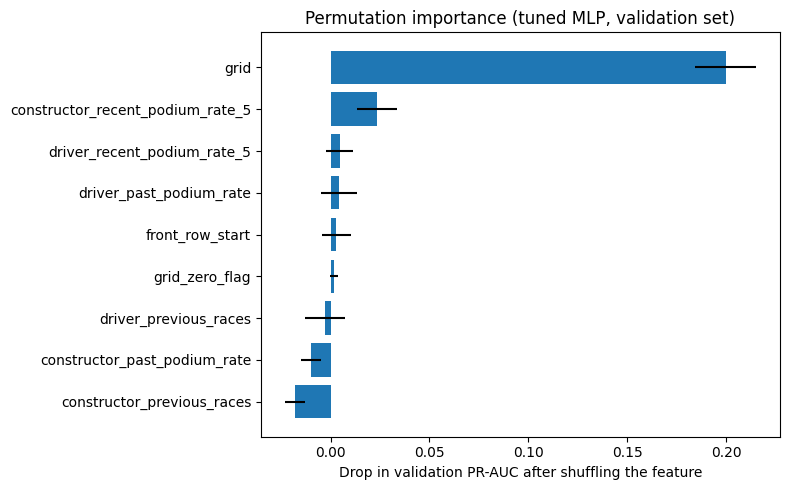

In [455]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    mlp_best_model, Xva, y_val,
    scoring='average_precision',
    n_repeats=10, random_state=42, n_jobs=-1
)

perm_df = (pd.DataFrame({'feature': processed_cols,
                         'importance_mean': perm.importances_mean,
                         'importance_std': perm.importances_std})
           .sort_values('importance_mean', ascending=False)
           .reset_index(drop=True))
display(perm_df.round(4))

plt.figure(figsize=(8, 5))
plt.barh(perm_df['feature'], perm_df['importance_mean'],
         xerr=perm_df['importance_std'])
plt.gca().invert_yaxis()
plt.xlabel('Drop in validation PR-AUC after shuffling the feature')
plt.title('Permutation importance (tuned MLP, validation set)')
plt.tight_layout(); plt.show()

### 13b. Global explanation: SHAP

**What the next cell does:** SHAP gives each feature a *contribution* to each individual prediction: how much that feature pushed the predicted podium probability up or down compared with an average driver-race. Averaging the absolute contributions over many rows gives a global importance ranking. We explain the tuned MLP's podium probability on a random sample of 300 validation rows, using 100 training rows as the "average" reference (SHAP is slow, so we sample).

**Two plots:**
- **Bar plot:** the mean absolute SHAP value per feature, which is the global importance ranking.
- **Beeswarm plot:** one dot per row. The horizontal position shows whether the feature pushed that row's prediction up (right) or down (left), and the colour shows the feature's value (red high, blue low; values are standardized). This shows the *direction* of the relationship the model learned, which permutation importance does not.

**Reminder:** SHAP describes how the model uses the features, not what causes podium finishes. Correlated features share credit, so the split between them should not be over-read.

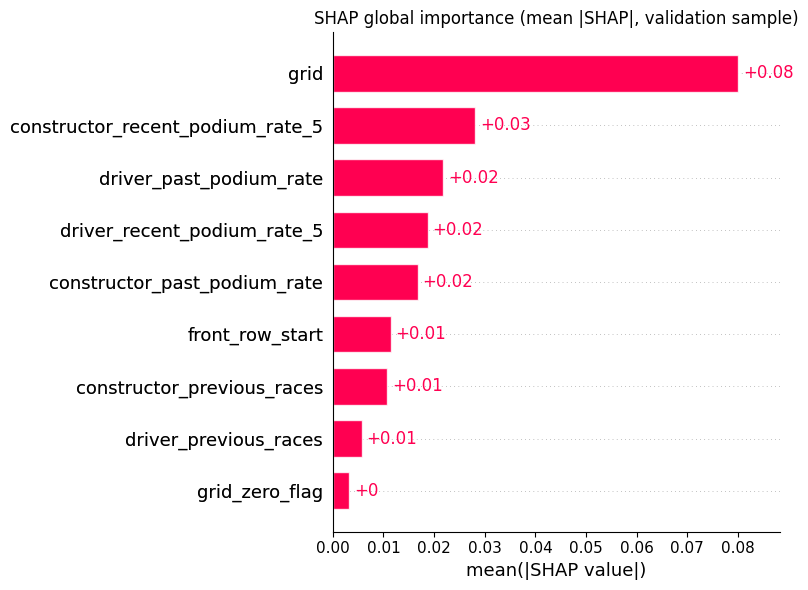

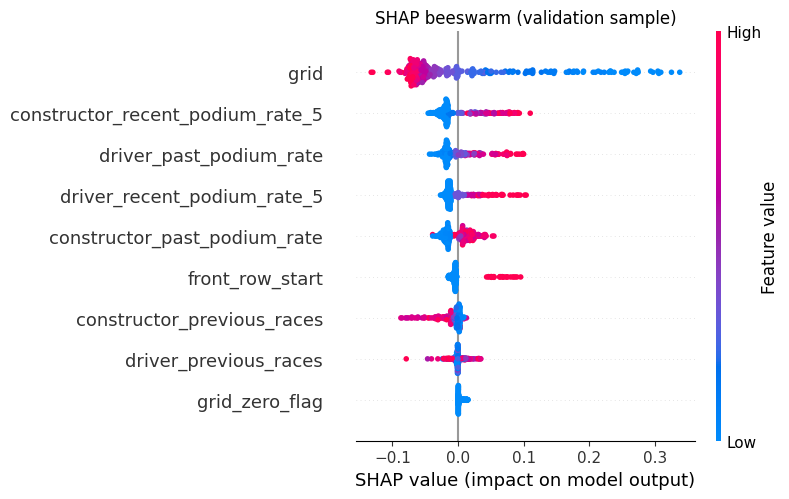

In [456]:
import shap

rng = np.random.RandomState(42)
bg_idx  = rng.choice(len(Xtr), 100, replace=False)
exp_idx = rng.choice(len(Xva), 300, replace=False)

Xbg  = Xtr[bg_idx]
Xexp = Xva[exp_idx]

predict_podium = lambda X: mlp_best_model.predict_proba(X)[:, 1]

explainer = shap.Explainer(predict_podium, Xbg, feature_names=processed_cols)
shap_values = explainer(Xexp)

shap.plots.bar(shap_values, show=False)
plt.title('SHAP global importance (mean |SHAP|, validation sample)')
plt.tight_layout(); plt.show()

shap.plots.beeswarm(shap_values, show=False)
plt.title('SHAP beeswarm (validation sample)')
plt.tight_layout(); plt.show()

### 13c. Local explanation: one prediction (LIME and SHAP waterfall)

**What the next cell does:** global methods describe the model overall; here we explain **one** validation driver-race. We pick a real podium finisher that the model predicted correctly with a moderate probability (not the most obvious case) and explain it two ways:
- **LIME** fits a simple linear model on small random variations of this one row and reports which feature values pushed the podium probability up or down locally.
- **SHAP waterfall** starts from the average prediction and adds each feature's contribution until it reaches this row's predicted probability.

**Reading the output:** the feature values on the plots are *standardized* (0 = training average), so the cell also prints the row's raw feature values. If LIME and SHAP agree on the main drivers, the explanation is more trustworthy; where they differ, say so.


Validation row position: 2656
Actual class: Podium
Predicted podium probability: 0.6
Predicted class: Podium


,Raw Value
grid,3.000000
front_row_start,0.000000
grid_zero_flag,0.000000
driver_previous_races,214.000000
driver_past_podium_rate,0.504673
driver_recent_podium_rate_5,0.600000
constructor_previous_races,966.000000
constructor_past_podium_rate,0.351326
constructor_recent_podium_rate_5,0.600000


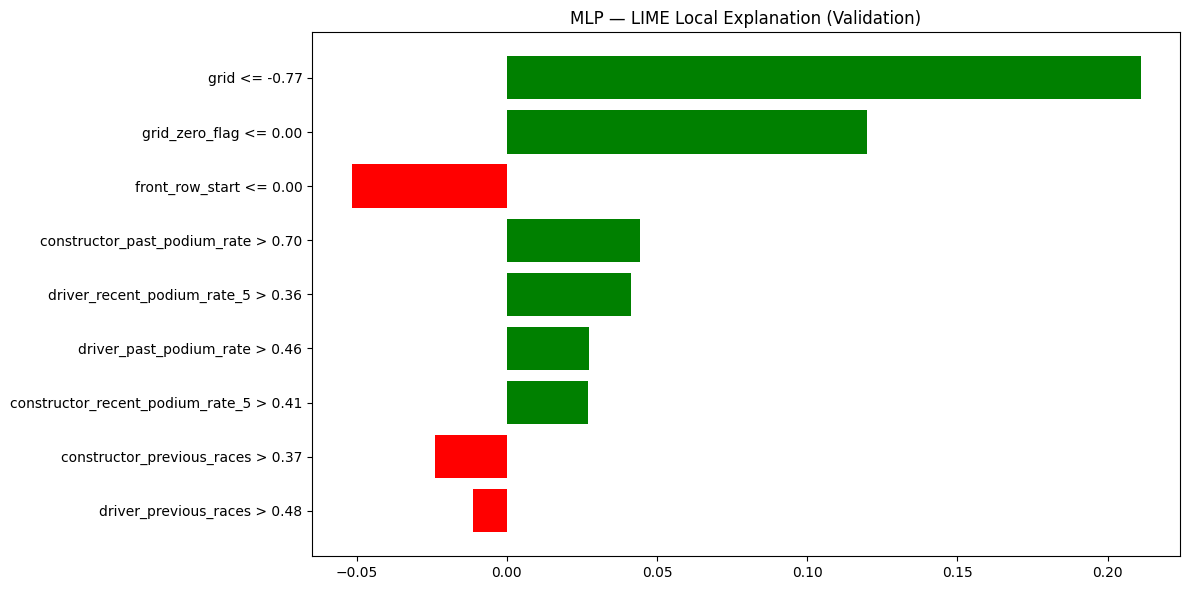


LIME Feature Contributions:
grid <= -0.77: +0.2109
grid_zero_flag <= 0.00: +0.1199
front_row_start <= 0.00: -0.0517
constructor_past_podium_rate > 0.70: +0.0442
driver_recent_podium_rate_5 > 0.36: +0.0413
driver_past_podium_rate > 0.46: +0.0275
constructor_recent_podium_rate_5 > 0.41: +0.0269
constructor_previous_races > 0.37: -0.0239
driver_previous_races > 0.48: -0.0113


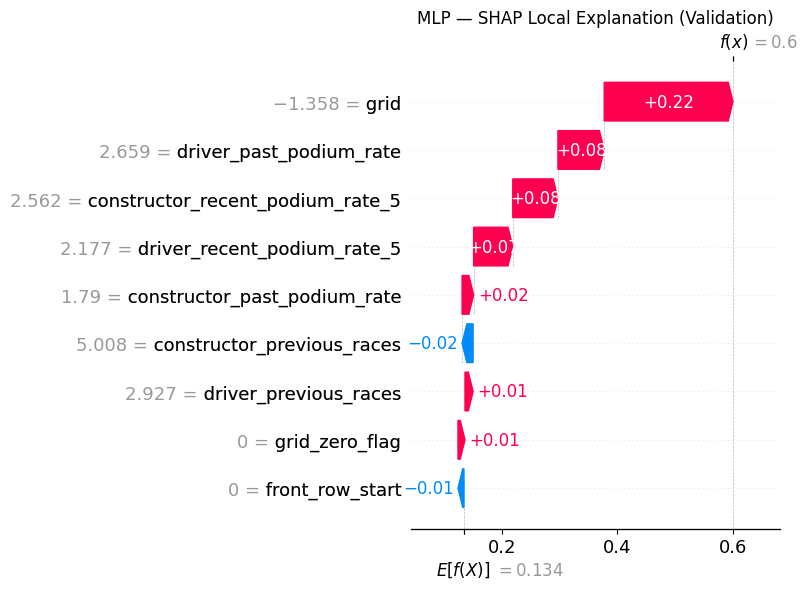

In [457]:

from lime.lime_tabular import LimeTabularExplainer
import numpy as np
import matplotlib.pyplot as plt
import shap

# ============================================
# 1. Select a validation observation
# ============================================

# Get actual validation labels
yv = np.asarray(y_val)

# Calculate validation podium probabilities
mlp_val_proba = mlp_best_model.predict_proba(Xva)[:, 1]

# Find actual podium observations correctly predicted as podium
mlp_candidates = np.where(
    (yv == 1) &
    (mlp_val_proba >= mlp_best_threshold)
)[0]

if len(mlp_candidates) > 0:
    # Choose the correctly predicted podium closest to probability 0.6
    i = int(
        mlp_candidates[
            np.argmin(
                np.abs(mlp_val_proba[mlp_candidates] - 0.6)
            )
        ]
    )
else:
    # Fallback: observation with highest podium probability
    i = int(np.argmax(mlp_val_proba))

print("Validation row position:", i)
print("Actual class:", "Podium" if yv[i] == 1 else "No podium")
print(
    "Predicted podium probability:",
    round(float(mlp_val_proba[i]), 4)
)
print(
    "Predicted class:",
    "Podium" if mlp_val_proba[i] >= mlp_best_threshold
    else "No podium"
)

# Display original feature values
display(
    X_val.iloc[i][feature_cols].to_frame("Raw Value")
)


# ============================================
# 2. LIME Local Explanation
# ============================================

lime_exp = LimeTabularExplainer(
    training_data=np.asarray(Xtr),
    feature_names=processed_cols,
    class_names=["No podium", "Podium"],
    mode="classification",
    random_state=42
)

exp = lime_exp.explain_instance(
    data_row=np.asarray(Xva[i]),
    predict_fn=mlp_best_model.predict_proba,
    num_features=9,
    labels=(1,)
)

# Plot LIME explanation for the podium class
fig = exp.as_pyplot_figure(label=1)
fig.set_size_inches(12, 6)

plt.title("MLP — LIME Local Explanation (Validation)")
plt.tight_layout()
plt.show()

print("\nLIME Feature Contributions:")
for feature, contribution in exp.as_list(label=1):
    print(f"{feature}: {contribution:+.4f}")


# ============================================
# 3. SHAP Waterfall for the Same Observation
# ============================================

# Use the existing SHAP explainer
sv_row = explainer(np.asarray(Xva[i:i+1]))

# Display SHAP waterfall
shap.plots.waterfall(
    sv_row[0],
    show=False
)

plt.title("MLP — SHAP Local Explanation (Validation)")
plt.tight_layout()
plt.show()


## 14. Inference function

**What the next cell does:** `mlp_predict_podium` takes one driver-race record (a dictionary of pre-race values) and returns the predicted podium probability and a yes/no label. It reuses the objects already fitted on **training data only**: the imputer and scaler (`preprocessors['StandardScaler']`), the tuned MLP (`mlp_best_model`) and the validation-chosen threshold (`mlp_best_threshold`). Nothing is refitted.

**Handling the inputs:** `front_row_start` and `grid_zero_flag` are derived from `grid` with the same rules used in training (front row = grid 1 or 2; grid 0 is set to missing and flagged). Any other missing value is replaced by the training median by the fitted imputer.

**Demonstration:** we run it on a complete record (the same row we explained with LIME/SHAP, as a consistency check) and on a record with several history features missing. Imputing missing history with the training median means "unknown" is treated as "typical", so predictions for partially-missing records are less reliable.

In [458]:

def mlp_predict_podium(record, model=None, preprocessor=None,
                       threshold=None):

    model = mlp_best_model if model is None else model
    preprocessor = (
        preprocessors["StandardScaler"]
        if preprocessor is None else preprocessor
    )
    threshold = (
        mlp_best_threshold if threshold is None else threshold
    )

    r = dict(record)
    g = r.get("grid", np.nan)
    g = np.nan if g is None else g

    # Derive grid-related features consistently
    r["front_row_start"] = int(g in (1, 2))
    r["grid_zero_flag"] = int(g == 0)
    r["grid"] = np.nan if g == 0 else g

    row = pd.DataFrame([
        {c: r.get(c, np.nan) for c in feature_cols}
    ])

    missing = [
        c for c in feature_cols
        if pd.isna(row.iloc[0][c])
    ]

    transformed = preprocessor.transform(row)
    probability = float(
        model.predict_proba(transformed)[0, 1]
    )

    return {
        "podium_probability": round(probability, 4),
        "predicted_podium": bool(probability >= threshold),
        "threshold": threshold,
        "missing_features_imputed": missing
    }


# Example 1: Complete record from validation data
mlp_example_position = 0

mlp_complete_record = X_val.iloc[
    mlp_example_position
][feature_cols].to_dict()

mlp_complete_result = mlp_predict_podium(
    mlp_complete_record
)

print("Complete record:")
print(mlp_complete_result)

print(
    "Direct validation prediction:",
    round(
        float(
            mlp_best_model.predict_proba(
                Xva[mlp_example_position:
                    mlp_example_position + 1]
            )[0, 1]
        ),
        4
    )
)


# Example 2: Partially missing record
mlp_partial_record = dict(mlp_complete_record)

for feature in [
    "driver_past_podium_rate",
    "driver_recent_podium_rate_5",
    "constructor_recent_podium_rate_5"
]:
    mlp_partial_record.pop(feature, None)

print("\nPartially missing record:")
print(mlp_predict_podium(mlp_partial_record))


Complete record:
{'podium_probability': 0.1205, 'predicted_podium': False, 'threshold': 0.36, 'missing_features_imputed': []}
Direct validation prediction: 0.1205

Partially missing record:
{'podium_probability': 0.0336, 'predicted_podium': False, 'threshold': 0.36, 'missing_features_imputed': ['driver_past_podium_rate', 'driver_recent_podium_rate_5', 'constructor_recent_podium_rate_5']}


# Aesha — Logistic Regression

Baseline, validation-only tuning and threshold selection, final test evaluation, feature-group ablation, SHAP, LIME, permutation importance, and inference. Variables are prefixed `lr_` to avoid conflicts with Random Forest and MLP.

In [459]:
# Confirm that the shared master inputs required by Logistic Regression exist.
lr_feature_cols = ['grid','front_row_start','grid_zero_flag',
    'driver_previous_races','driver_past_podium_rate','driver_recent_podium_rate_5',
    'constructor_previous_races','constructor_past_podium_rate','constructor_recent_podium_rate_5']
for lr_split_name, lr_split in [('train', X_train), ('validation', X_val), ('test', X_test)]:
    lr_missing_cols = set(lr_feature_cols) - set(lr_split.columns)
    if lr_missing_cols:
        raise ValueError(f'{lr_split_name} missing features: {lr_missing_cols}')
print('Shared inputs verified for Logistic Regression.')

Shared inputs verified for Logistic Regression.


## 12. Baseline Model — Logistic Regression

### Objective
Train a Logistic Regression classifier to predict whether a driver will finish a race on the podium.

Logistic Regression estimates the probability of a podium finish using a weighted combination of the input features. Although its name contains “regression,” it is a classification algorithm. It is a useful baseline because it is relatively simple, computationally efficient, and interpretable.

### Preprocessing
Continuous numerical features are median-imputed where necessary and standardized. Binary indicator features are retained without scaling. Preprocessing is fitted on the training data only and then applied to the other partitions.

### Initial classification threshold
The initial probability threshold is 0.50. A prediction is classified as a podium finish when its predicted probability is at least 0.50; otherwise, it is classified as a non-podium finish.

This threshold is used as a baseline rather than assumed to be optimal. It will be compared with a threshold selected using validation data in a later experiment.

### Evaluation
ROC-AUC and PR-AUC (Average Precision) evaluate probability ranking. F1, precision, and recall evaluate the resulting binary predictions at the selected threshold. Results are reported separately for training and validation to help identify overfitting and assess generalization.

In [460]:
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score
)

# --------------------------------------------------
# 1. Define the baseline model
# --------------------------------------------------

lr_initial_threshold = 0.50

lr_baseline_model = Pipeline([
    (
        'preprocessor',
        make_preprocessor(StandardScaler())
    ),
    (
        'model',
        LogisticRegression(
            C=1.0,
            penalty='l2',
            solver='lbfgs',
            max_iter=2000,
            random_state=42
        )
    )
])

# --------------------------------------------------
# 2. Train using the training partition only
# --------------------------------------------------

lr_baseline_model.fit(X_train, y_train)

print("Baseline Logistic Regression trained.")
print(
    "Iterations used:",
    lr_baseline_model.named_steps['model'].n_iter_[0]
)
print("Initial probability threshold:", lr_initial_threshold)


# --------------------------------------------------
# 3. Define a reusable evaluation function
# --------------------------------------------------

def lr_evaluate_binary_model(model, X, y, lr_threshold=0.50):
    lr_probabilities = model.predict_proba(X)[:, 1]
    lr_predictions = (lr_probabilities >= lr_threshold).astype(int)

    return {
        'ROC-AUC': roc_auc_score(y, lr_probabilities),
        'PR-AUC (Average Precision)': average_precision_score(
            y, lr_probabilities
        ),
        'F1': f1_score(y, lr_predictions, zero_division=0),
        'Precision': precision_score(
            y, lr_predictions, zero_division=0
        ),
        'Recall': recall_score(
            y, lr_predictions, zero_division=0
        )
    }


# --------------------------------------------------
# 4. Evaluate training and validation
# --------------------------------------------------

lr_baseline_train_metrics = lr_evaluate_binary_model(
    lr_baseline_model,
    X_train,
    y_train,
    lr_threshold=lr_initial_threshold
)

lr_baseline_val_metrics = lr_evaluate_binary_model(
    lr_baseline_model,
    X_val,
    y_val,
    lr_threshold=lr_initial_threshold
)

lr_baseline_results = pd.DataFrame(
    [
        lr_baseline_train_metrics,
        lr_baseline_val_metrics
    ],
    index=['Training', 'Validation']
)

display(lr_baseline_results.round(4))

Baseline Logistic Regression trained.
Iterations used: 20
Initial probability threshold: 0.5


,ROC-AUC,PR-AUC (Average Precision),F1,Precision,Recall
Training,0.8990,0.5293,0.4496,0.6023,0.3587
Validation,0.9377,0.7071,0.6281,0.7138,0.5608


## 13. Hyperparameter Tuning — Logistic Regression

We tune the regularization parameter \(C\) using the training set to fit each candidate model and the validation set to evaluate it. Validation PR-AUC (Average Precision) is the selection metric because the dataset is imbalanced and identifying podium finishes is our main objective.

The test set remains untouched during model selection. After selecting the best \(C\), we will optimize the classification threshold separately using validation F1.

In [461]:
# Candidate regularization strengths.
lr_C_values = [0.01, 0.1, 1.0, 10.0, 100.0]

lr_tuning_results = []
lr_candidate_models = {}

for lr_C_value in lr_C_values:

    # Build a fresh pipeline for each candidate.
    lr_candidate_model = Pipeline([
        ('preprocessor', make_preprocessor(StandardScaler())),
        ('model', LogisticRegression(
            C=lr_C_value,
            penalty='l2',
            solver='lbfgs',
            max_iter=2000,
            random_state=42
        ))
    ])

    # Fit only on the training partition.
    lr_candidate_model.fit(X_train, y_train)

    # Obtain predicted probabilities for training and validation.
    lr_train_probabilities = lr_candidate_model.predict_proba(
        X_train
    )[:, 1]

    lr_val_probabilities = lr_candidate_model.predict_proba(
        X_val
    )[:, 1]

    # Store each candidate's performance.
    lr_tuning_results.append({
        'C': lr_C_value,
        'Training ROC-AUC': roc_auc_score(
            y_train, lr_train_probabilities
        ),
        'Validation ROC-AUC': roc_auc_score(
            y_val, lr_val_probabilities
        ),
        'Training PR-AUC': average_precision_score(
            y_train, lr_train_probabilities
        ),
        'Validation PR-AUC': average_precision_score(
            y_val, lr_val_probabilities
        )
    })

    lr_candidate_models[lr_C_value] = lr_candidate_model

# Compare all candidates.
lr_tuning_table = pd.DataFrame(lr_tuning_results)

display(
    lr_tuning_table.sort_values(
        'Validation PR-AUC',
        ascending=False
    ).round(4)
)

# Select the candidate with the highest validation PR-AUC.
lr_best_C = lr_tuning_table.loc[
    lr_tuning_table['Validation PR-AUC'].idxmax(),
    'C'
]

lr_best_model = lr_candidate_models[lr_best_C]

print(f"Selected C: {lr_best_C}")
print(
    "Best validation PR-AUC:",
    round(
        lr_tuning_table['Validation PR-AUC'].max(),
        4
    )
)

,C,Training ROC-AUC,Validation ROC-AUC,Training PR-AUC,Validation PR-AUC
1,0.10,0.8987,0.9379,0.5292,0.7072
4,100.00,0.8992,0.9377,0.5292,0.7072
2,1.00,0.8990,0.9377,0.5293,0.7071
3,10.00,0.8992,0.9376,0.5293,0.7070
0,0.01,0.8981,0.9392,0.5283,0.7066


Selected C: 0.1
Best validation PR-AUC: 0.7072


## 14. Classification Threshold Optimization

The default threshold of 0.50 is a starting point, not necessarily the best decision threshold for an imbalanced dataset. We evaluate thresholds from 0.05 to 0.95 using validation predictions and select the threshold that maximizes validation F1.

A lower threshold generally identifies more potential podium finishers, increasing recall but potentially reducing precision. A higher threshold generally makes predictions more selective.

The threshold is selected using validation data only and is then kept fixed for the final test evaluation.

In [462]:
# Get validation probabilities from the selected model.
lr_val_probabilities = lr_best_model.predict_proba(X_val)[:, 1]

# Evaluate a range of candidate thresholds.
lr_threshold_values = np.arange(0.05, 0.951, 0.01)

lr_threshold_results = []

for lr_threshold in lr_threshold_values:
    lr_val_predictions = (
        lr_val_probabilities >= lr_threshold
    ).astype(int)

    lr_threshold_results.append({
        'Threshold': lr_threshold,
        'F1': f1_score(
            y_val, lr_val_predictions, zero_division=0
        ),
        'Precision': precision_score(
            y_val, lr_val_predictions, zero_division=0
        ),
        'Recall': recall_score(
            y_val, lr_val_predictions, zero_division=0
        )
    })

lr_threshold_table = pd.DataFrame(lr_threshold_results)

# Select the threshold with the highest validation F1.
lr_best_threshold_row = lr_threshold_table.loc[
    lr_threshold_table['F1'].idxmax()
]

lr_best_threshold = float(lr_best_threshold_row['Threshold'])

print(f"Selected threshold: {lr_best_threshold:.2f}")
print(f"Validation F1: {lr_best_threshold_row['F1']:.4f}")
print(
    f"Validation precision: "
    f"{lr_best_threshold_row['Precision']:.4f}"
)
print(
    f"Validation recall: "
    f"{lr_best_threshold_row['Recall']:.4f}"
)

# Compare the default and optimized thresholds.
lr_threshold_comparison = lr_threshold_table[
    lr_threshold_table['Threshold'].isin([0.50, lr_best_threshold])
].copy()

lr_threshold_comparison['Threshold Type'] = (
    lr_threshold_comparison['Threshold']
    .map({
        0.50: 'Default (0.50)',
        lr_best_threshold: 'Optimized'
    })
)

# If the optimized threshold is 0.50, keep the labels unambiguous.
if lr_best_threshold == 0.50:
    lr_threshold_comparison['Threshold Type'] = (
        'Default and optimized (0.50)'
    )

display(
    lr_threshold_comparison[
        ['Threshold Type', 'Threshold', 'F1', 'Precision', 'Recall']
    ].round(4)
)

Selected threshold: 0.34
Validation F1: 0.6813
Validation precision: 0.6045
Validation recall: 0.7804


,Threshold Type,Threshold,F1,Precision,Recall
29,Optimized,0.34,0.6813,0.6045,0.7804


In [463]:
lr_threshold_comparison_rows = []

for lr_threshold, lr_threshold_name in [
    (0.50, 'Default (0.50)'),
    (lr_best_threshold, 'Optimized')
]:
    lr_val_predictions = (
        lr_val_probabilities >= lr_threshold
    ).astype(int)

    lr_threshold_comparison_rows.append({
        'Threshold Type': lr_threshold_name,
        'Threshold': lr_threshold,
        'F1': f1_score(
            y_val, lr_val_predictions, zero_division=0
        ),
        'Precision': precision_score(
            y_val, lr_val_predictions, zero_division=0
        ),
        'Recall': recall_score(
            y_val, lr_val_predictions, zero_division=0
        )
    })

lr_threshold_comparison = pd.DataFrame(lr_threshold_comparison_rows)

display(lr_threshold_comparison.round(4))

,Threshold Type,Threshold,F1,Precision,Recall
0,Default (0.50),0.50,0.6261,0.7128,0.5582
1,Optimized,0.34,0.6813,0.6045,0.7804


## 15. Tuned Logistic Regression — Training and Validation Evaluation

After selecting the regularization parameter and classification threshold using training and validation data, we evaluate the tuned Logistic Regression model. We report ROC-AUC and PR-AUC (Average Precision), which measure ranking performance, alongside F1, precision, and recall at the default threshold of 0.50 and the optimized threshold.

These results support model comparison and threshold analysis. The test set remains reserved for final evaluation after model selection is complete.

In [464]:
lr_evaluation_rows = []

for lr_partition_name, X, y in [
    ('Training', X_train, y_train),
    ('Validation', X_val, y_val)
]:
    lr_probabilities = lr_best_model.predict_proba(X)[:, 1]

    # Ranking metrics do not depend on the threshold.
    lr_roc_auc = roc_auc_score(y, lr_probabilities)
    lr_pr_auc = average_precision_score(y, lr_probabilities)

    for lr_threshold, lr_threshold_name in [
        (0.50, 'Default (0.50)'),
        (lr_best_threshold, 'Optimized')
    ]:
        lr_predictions = (lr_probabilities >= lr_threshold).astype(int)

        lr_evaluation_rows.append({
            'Partition': lr_partition_name,
            'Threshold Type': lr_threshold_name,
            'Threshold': lr_threshold,
            'ROC-AUC': lr_roc_auc,
            'PR-AUC': lr_pr_auc,
            'F1': f1_score(
                y, lr_predictions, zero_division=0
            ),
            'Precision': precision_score(
                y, lr_predictions, zero_division=0
            ),
            'Recall': recall_score(
                y, lr_predictions, zero_division=0
            )
        })

lr_tuned_logistic_results = pd.DataFrame(lr_evaluation_rows)

display(lr_tuned_logistic_results.round(4))

print(f"Selected C: {lr_best_C}")
print(f"Selected threshold: {lr_best_threshold:.2f}")

,Partition,Threshold Type,Threshold,ROC-AUC,PR-AUC,F1,Precision,Recall
0,Training,Default (0.50),0.50,0.8987,0.5292,0.4465,0.6008,0.3552
1,Training,Optimized,0.34,0.8987,0.5292,0.5552,0.5279,0.5856
2,Validation,Default (0.50),0.50,0.9379,0.7072,0.6261,0.7128,0.5582
3,Validation,Optimized,0.34,0.9379,0.7072,0.6813,0.6045,0.7804


Selected C: 0.1
Selected threshold: 0.34


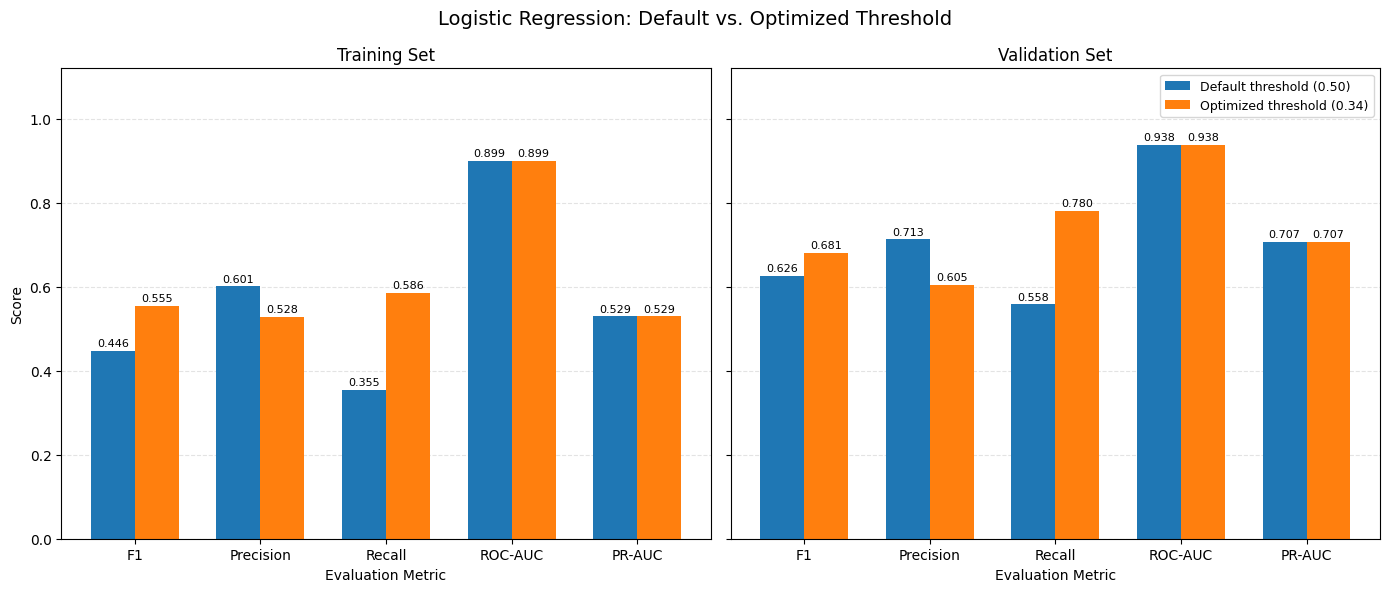

In [465]:
import matplotlib.pyplot as plt
import numpy as np

# Metrics to visualize
lr_metrics = ["F1", "Precision", "Recall", "ROC-AUC", "PR-AUC"]

lr_partitions = ["Training", "Validation"]
lr_threshold_types = ["Default (0.50)", "Optimized"]

lr_fig, lr_axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

lr_x = np.arange(len(lr_metrics))
lr_width = 0.35

for lr_ax, lr_partition in zip(lr_axes, lr_partitions):

    lr_partition_data = (
        lr_tuned_logistic_results[
            lr_tuned_logistic_results["Partition"] == lr_partition
        ]
        .set_index("Threshold Type")
        .loc[lr_threshold_types]
    )

    lr_default_values = lr_partition_data.loc["Default (0.50)", lr_metrics].values
    lr_optimized_values = lr_partition_data.loc["Optimized", lr_metrics].values

    lr_bars1 = lr_ax.bar(
        lr_x - lr_width / 2,
        lr_default_values,
        lr_width,
        label="Default threshold (0.50)"
    )

    lr_bars2 = lr_ax.bar(
        lr_x + lr_width / 2,
        lr_optimized_values,
        lr_width,
        label="Optimized threshold (0.34)"
    )

    lr_ax.bar_label(lr_bars1, fmt="%.3f", padding=2, fontsize=8)
    lr_ax.bar_label(lr_bars2, fmt="%.3f", padding=2, fontsize=8)

    lr_ax.set_title(f"{lr_partition} Set")
    lr_ax.set_xticks(lr_x)
    lr_ax.set_xticklabels(lr_metrics)
    lr_ax.set_ylim(0, 1.12)
    lr_ax.grid(axis="y", linestyle="--", alpha=0.35)
    lr_ax.set_axisbelow(True)
    lr_ax.set_xlabel("Evaluation Metric")

lr_axes[0].set_ylabel("Score")
lr_axes[1].legend(loc="upper right", fontsize=9)

lr_fig.suptitle(
    "Logistic Regression: Default vs. Optimized Threshold",
    fontsize=14
)

plt.tight_layout()
plt.savefig(
    "logistic_threshold_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

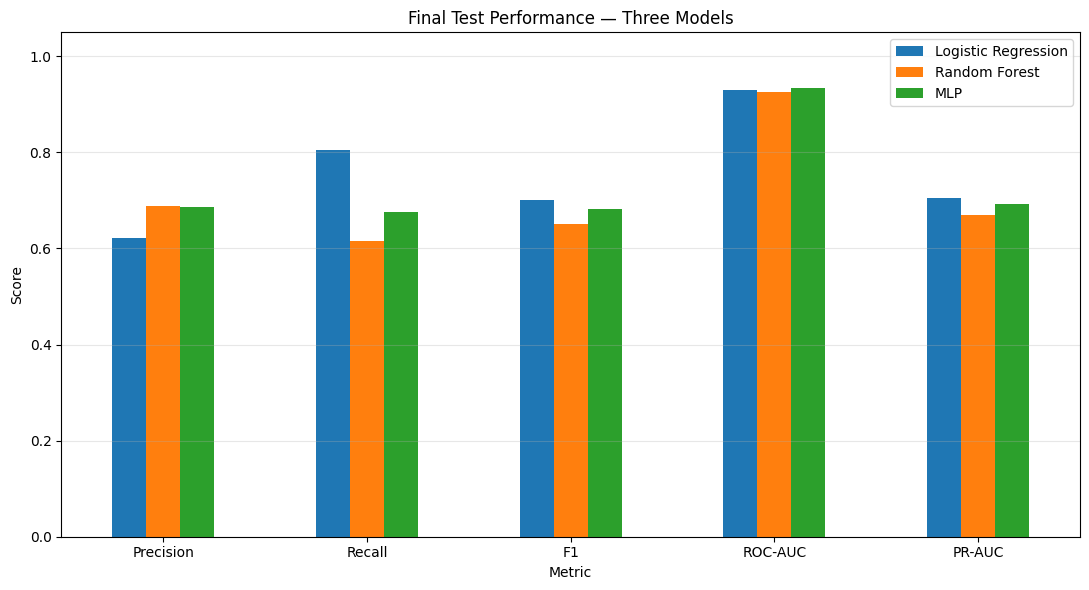

In [466]:

import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "Metric": ["Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"],
    "Logistic Regression": [0.6209, 0.8045, 0.7009, 0.9299, 0.7050],
    "Random Forest": [0.6891, 0.6165, 0.6508, 0.9258, 0.6703],
    "MLP": [0.6870, 0.6767, 0.6818, 0.9335, 0.6922]
})

ax = comparison.set_index("Metric").plot(
    kind="bar",
    figsize=(11, 6),
    rot=0
)

ax.set_title("Final Test Performance — Three Models")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [467]:

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# --------------------------------------------------
# 1. Freeze the selected model and threshold
# --------------------------------------------------

lr_final_model = lr_best_model
lr_final_threshold = lr_best_threshold

print("Selected C:", lr_best_C)
print("Frozen threshold:", round(lr_final_threshold, 2))

# --------------------------------------------------
# 2. Evaluate the untouched test partition
# --------------------------------------------------

lr_test_probabilities = lr_final_model.predict_proba(X_test)[:, 1]

lr_test_predictions = (
    lr_test_probabilities >= lr_final_threshold
).astype(int)

# Threshold-independent metrics
lr_test_roc_auc = roc_auc_score(y_test, lr_test_probabilities)
lr_test_pr_auc = average_precision_score(y_test, lr_test_probabilities)

# Threshold-dependent metrics
lr_test_accuracy = accuracy_score(y_test, lr_test_predictions)
lr_test_f1 = f1_score(y_test, lr_test_predictions, zero_division=0)
lr_test_precision = precision_score(
    y_test, lr_test_predictions, zero_division=0
)
lr_test_recall = recall_score(
    y_test, lr_test_predictions, zero_division=0
)

lr_test_results = pd.DataFrame(
    [{
        "C": lr_best_C,
        "Threshold": lr_final_threshold,
        "ROC-AUC": lr_test_roc_auc,
        "PR-AUC": lr_test_pr_auc,
        "Accuracy": lr_test_accuracy,
        "F1": lr_test_f1,
        "Precision": lr_test_precision,
        "Recall": lr_test_recall
    }],
    index=["Test"]
)

display(lr_test_results.round(4))

# --------------------------------------------------
# 3. Confusion matrix
# Rows = actual classes; columns = predicted classes
# --------------------------------------------------

lr_cm = confusion_matrix(y_test, lr_test_predictions, labels=[0, 1])

lr_confusion_table = pd.DataFrame(
    lr_cm,
    index=["Actual: No podium", "Actual: Podium"],
    columns=["Predicted: No podium", "Predicted: Podium"]
)

display(lr_confusion_table)

print("\nClassification report:")
print(
    classification_report(
        y_test,
        lr_test_predictions,
        labels=[0, 1],
        target_names=["No podium", "Podium"],
        zero_division=0
    )
)


Selected C: 0.1
Frozen threshold: 0.34


,C,Threshold,ROC-AUC,PR-AUC,Accuracy,F1,Precision,Recall
Test,0.1,0.34,0.9299,0.705,0.897,0.7009,0.6209,0.8045


,Predicted: No podium,Predicted: Podium
Actual: No podium,2064,196
Actual: Podium,78,321



Classification report:
              precision    recall  f1-score   support

   No podium       0.96      0.91      0.94      2260
      Podium       0.62      0.80      0.70       399

    accuracy                           0.90      2659
   macro avg       0.79      0.86      0.82      2659
weighted avg       0.91      0.90      0.90      2659



In [468]:

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    accuracy_score
)

# --------------------------------------------------
# 1. Define the feature groups
# --------------------------------------------------

lr_starting_position_features = [
    'grid',
    'grid_zero_flag',
    'front_row_start'
]

lr_driver_history_features = [
    'driver_previous_races',
    'driver_past_podium_rate',
    'driver_recent_podium_rate_5'
]

lr_constructor_history_features = [
    'constructor_previous_races',
    'constructor_past_podium_rate',
    'constructor_recent_podium_rate_5'
]

lr_all_features = (
    lr_starting_position_features
    + lr_driver_history_features
    + lr_constructor_history_features
)

# Check that the expected features exist in every partition.
for lr_partition_name, X in [
    ('X_train', X_train),
    ('X_val', X_val),
    ('X_test', X_test)
]:
    lr_missing = sorted(set(lr_all_features) - set(X.columns))
    if lr_missing:
        raise ValueError(
            f"{lr_partition_name} is missing features: {lr_missing}"
        )

lr_ablation_configs = {
    'Full baseline': lr_all_features,

    'Without starting position': (
        lr_driver_history_features
        + lr_constructor_history_features
    ),

    'Without driver history': (
        lr_starting_position_features
        + lr_constructor_history_features
    ),

    'Without constructor history': (
        lr_starting_position_features
        + lr_driver_history_features
    )
}

# --------------------------------------------------
# 2. Set the same candidate C values used previously
# --------------------------------------------------

lr_C_values = [0.01, 0.1, 1.0, 10.0, 100.0]

lr_threshold_values = np.arange(0.05, 0.951, 0.01)

lr_ablation_models = {}
lr_ablation_results = []
lr_ablation_tuning_results = []

# --------------------------------------------------
# 3. Train and select settings using train/validation
# --------------------------------------------------

for lr_experiment_name, lr_features in lr_ablation_configs.items():

    print(f"\nRunning: {lr_experiment_name}")
    print(f"Number of features: {len(lr_features)}")

    lr_Xtr = X_train[lr_features]
    lr_Xv = X_val[lr_features]

    lr_candidate_models = []
    lr_candidate_scores = []

    # Select C by validation PR-AUC.
    for lr_C_value in lr_C_values:

        from sklearn.impute import SimpleImputer

        lr_candidate_model = Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()),
            ('model', LogisticRegression(
                C=lr_C_value,
                penalty='l2',
                solver='lbfgs',
                max_iter=2000,
                random_state=42
            ))
        ])

        lr_candidate_model.fit(lr_Xtr, y_train)

        lr_train_prob = lr_candidate_model.predict_proba(lr_Xtr)[:, 1]
        lr_val_prob = lr_candidate_model.predict_proba(lr_Xv)[:, 1]

        lr_train_pr_auc = average_precision_score(
            y_train, lr_train_prob
        )
        lr_val_pr_auc = average_precision_score(
            y_val, lr_val_prob
        )

        lr_candidate_models.append(lr_candidate_model)
        lr_candidate_scores.append(lr_val_pr_auc)

        lr_ablation_tuning_results.append({
            'Experiment': lr_experiment_name,
            'C': lr_C_value,
            'Training PR-AUC': lr_train_pr_auc,
            'Validation PR-AUC': lr_val_pr_auc
        })

    lr_best_index = int(np.argmax(lr_candidate_scores))
    lr_selected_C = lr_C_values[lr_best_index]
    lr_selected_model = lr_candidate_models[lr_best_index]

    # Select threshold by validation F1 only.
    lr_val_prob = lr_selected_model.predict_proba(lr_Xv)[:, 1]

    lr_threshold_scores = []

    for lr_threshold in lr_threshold_values:
        lr_val_pred = (lr_val_prob >= lr_threshold).astype(int)

        lr_threshold_scores.append({
            'threshold': float(lr_threshold),
            'F1': f1_score(
                y_val, lr_val_pred, zero_division=0
            ),
            'Precision': precision_score(
                y_val, lr_val_pred, zero_division=0
            ),
            'Recall': recall_score(
                y_val, lr_val_pred, zero_division=0
            )
        })

    lr_best_threshold_row = max(
        lr_threshold_scores,
        key=lambda row: row['F1']
    )

    lr_selected_threshold = lr_best_threshold_row['threshold']

    # Save selected model and settings.
    lr_ablation_models[lr_experiment_name] = {
        'model': lr_selected_model,
        'features': lr_features,
        'C': lr_selected_C,
        'threshold': lr_selected_threshold
    }

    # --------------------------------------------------
    # 4. Evaluate train, validation, and test
    # --------------------------------------------------

    lr_partitions = [
        ('Training', X_train[lr_features], y_train),
        ('Validation', X_val[lr_features], y_val),
        ('Test', X_test[lr_features], y_test)
    ]

    for lr_partition_name, lr_Xpart, lr_ypart in lr_partitions:

        lr_probabilities = lr_selected_model.predict_proba(
            lr_Xpart
        )[:, 1]

        lr_predictions = (
            lr_probabilities >= lr_selected_threshold
        ).astype(int)

        lr_ablation_results.append({
            'Experiment': lr_experiment_name,
            'Partition': lr_partition_name,
            'Features': len(lr_features),
            'C': lr_selected_C,
            'Threshold': lr_selected_threshold,
            'ROC-AUC': roc_auc_score(lr_ypart, lr_probabilities),
            'PR-AUC': average_precision_score(
                lr_ypart, lr_probabilities
            ),
            'Accuracy': accuracy_score(lr_ypart, lr_predictions),
            'F1': f1_score(
                lr_ypart, lr_predictions, zero_division=0
            ),
            'Precision': precision_score(
                lr_ypart, lr_predictions, zero_division=0
            ),
            'Recall': recall_score(
                lr_ypart, lr_predictions, zero_division=0
            )
        })

    print(f"Selected C: {lr_selected_C}")
    print(f"Selected threshold: {lr_selected_threshold:.2f}")
    print(
        f"Validation F1: {lr_best_threshold_row['F1']:.4f}"
    )

# --------------------------------------------------
# 5. Display results
# --------------------------------------------------

lr_ablation_results_df = pd.DataFrame(lr_ablation_results)
lr_ablation_tuning_df = pd.DataFrame(lr_ablation_tuning_results)

print("\nAblation results by partition:")
display(
    lr_ablation_results_df
    .sort_values(['Experiment', 'Partition'])
    .round(4)
)

print("\nC selection results:")
display(
    lr_ablation_tuning_df
    .sort_values(['Experiment', 'Validation PR-AUC'],
                 ascending=[True, False])
    .round(4)
)

print("\nTest-set comparison:")
lr_test_ablation_results = (
    lr_ablation_results_df[
        lr_ablation_results_df['Partition'] == 'Test'
    ]
    .sort_values('PR-AUC', ascending=False)
    .reset_index(drop=True)
)

display(lr_test_ablation_results.round(4))



Running: Full baseline
Number of features: 9
Selected C: 0.01
Selected threshold: 0.33
Validation F1: 0.6768

Running: Without starting position
Number of features: 6
Selected C: 1.0
Selected threshold: 0.29
Validation F1: 0.6253

Running: Without driver history
Number of features: 6
Selected C: 0.01
Selected threshold: 0.34
Validation F1: 0.6876

Running: Without constructor history
Number of features: 6
Selected C: 0.01
Selected threshold: 0.30
Validation F1: 0.6744

Ablation results by partition:


,Experiment,Partition,Features,C,Threshold,ROC-AUC,PR-AUC,Accuracy,F1,Precision,Recall
2,Full baseline,Test,9,0.01,0.33,0.9314,0.7052,0.8954,0.6958,0.6175,0.7970
0,Full baseline,Training,9,0.01,0.33,0.8993,0.5291,0.8852,0.5494,0.5300,0.5703
1,Full baseline,Validation,9,0.01,0.33,0.9396,0.7082,0.8967,0.6768,0.6071,0.7646
11,Without constructor history,Test,6,0.01,0.30,0.9272,0.7061,0.8947,0.6882,0.6192,0.7744
9,Without constructor history,Training,6,0.01,0.30,0.8964,0.5272,0.8813,0.5550,0.5140,0.6031
10,Without constructor history,Validation,6,0.01,0.30,0.9364,0.7064,0.8952,0.6744,0.6017,0.7672
8,Without driver history,Test,6,0.01,0.34,0.9292,0.6945,0.8958,0.6979,0.6178,0.8020
6,Without driver history,Training,6,0.01,0.34,0.8964,0.5195,0.8837,0.5346,0.5252,0.5443
7,Without driver history,Validation,6,0.01,0.34,0.9359,0.7006,0.9031,0.6876,0.6319,0.7540
5,Without starting position,Test,6,1.00,0.29,0.8936,0.5764,0.8597,0.6019,0.5242,0.7068



C selection results:


,Experiment,C,Training PR-AUC,Validation PR-AUC
0,Full baseline,0.01,0.5291,0.7082
1,Full baseline,0.10,0.5293,0.7073
3,Full baseline,10.00,0.5292,0.7072
4,Full baseline,100.00,0.5293,0.7072
2,Full baseline,1.00,0.5293,0.7071
15,Without constructor history,0.01,0.5272,0.7064
16,Without constructor history,0.10,0.5273,0.7049
17,Without constructor history,1.00,0.5273,0.7047
19,Without constructor history,100.00,0.5273,0.7047
18,Without constructor history,10.00,0.5272,0.7046



Test-set comparison:


,Experiment,Partition,Features,C,Threshold,ROC-AUC,PR-AUC,Accuracy,F1,Precision,Recall
0,Without constructor history,Test,6,0.01,0.30,0.9272,0.7061,0.8947,0.6882,0.6192,0.7744
1,Full baseline,Test,9,0.01,0.33,0.9314,0.7052,0.8954,0.6958,0.6175,0.7970
2,Without driver history,Test,6,0.01,0.34,0.9292,0.6945,0.8958,0.6979,0.6178,0.8020
3,Without starting position,Test,6,1.00,0.29,0.8936,0.5764,0.8597,0.6019,0.5242,0.7068


## Ablation Study Results and Discussion

The ablation study evaluated the contribution of three feature groups—starting position, driver history, and constructor history—to the Logistic Regression model's ability to predict Formula 1 podium finishes. Four configurations were compared: the full model containing all nine features and three reduced models, each excluding one feature group. Hyperparameters were selected using validation PR-AUC, and classification thresholds were optimized using validation F1. All configurations were evaluated on the same held-out test set.

### Results

The full model achieved a ROC-AUC of **0.9299**, PR-AUC of **0.7050**, and F1-score of **0.7009**. Removing starting-position features resulted in the largest performance degradation, reducing ROC-AUC to **0.8936**, PR-AUC to **0.5764**, and F1-score to **0.6019**. This indicates that starting-position information makes the strongest contribution to the model's predictive performance among the feature groups examined.

Removing driver-history features caused smaller decreases in performance, with ROC-AUC falling to **0.9277**, PR-AUC to **0.6940**, and F1-score to **0.6925**. These results suggest that historical driver performance provides additional predictive information beyond starting position and constructor history.

Removing constructor-history features produced mixed results. ROC-AUC decreased slightly to **0.9265**, while F1-score decreased to **0.6973**. However, PR-AUC increased marginally from **0.7050 to 0.7078**. This small improvement does not establish that constructor-history features are detrimental; rather, their contribution appears limited under the current experimental setup and evaluation period.

### Conclusion

Overall, the ablation study identifies starting position as the most influential feature group for podium prediction within the evaluated Logistic Regression model. Driver-history features provide a modest additional benefit, while the contribution of constructor-history features is less pronounced and varies across evaluation metrics. The full model achieves the highest ROC-AUC and F1-score, whereas the model without constructor history achieves the highest test PR-AUC by a small margin.

These findings highlight the importance of evaluating multiple metrics, particularly for an imbalanced binary classification task. The results describe predictive contributions within the tested model and dataset; they do not establish causal relationships. Furthermore, because the test set was used to compare the ablation configurations, these comparisons should be interpreted as exploratory rather than as an independent final confirmation of feature importance.

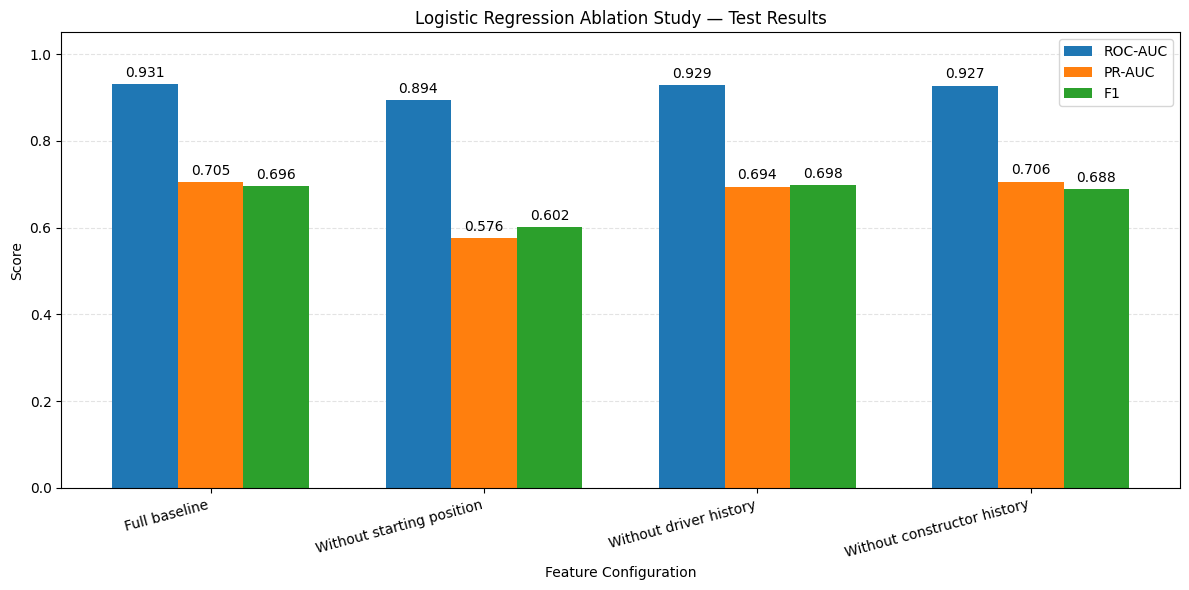

In [469]:

import numpy as np
import matplotlib.pyplot as plt

# Use the actual test results from the ablation study
lr_ablation_plot = (
    lr_ablation_results_df[
        lr_ablation_results_df["Partition"] == "Test"
    ]
    .copy()
)

lr_metrics = ["ROC-AUC", "PR-AUC", "F1"]
lr_x = np.arange(len(lr_ablation_plot))
lr_width = 0.24

lr_fig, lr_ax = plt.subplots(figsize=(12, 6))

for lr_i, lr_metric in enumerate(lr_metrics):
    lr_bars = lr_ax.bar(
        lr_x + (lr_i - 1) * lr_width,
        lr_ablation_plot[lr_metric],
        lr_width,
        label=lr_metric
    )
    lr_ax.bar_label(lr_bars, fmt="%.3f", padding=3)

lr_ax.set_title("Logistic Regression Ablation Study — Test Results")
lr_ax.set_xlabel("Feature Configuration")
lr_ax.set_ylabel("Score")
lr_ax.set_xticks(lr_x)
lr_ax.set_xticklabels(
    lr_ablation_plot["Experiment"],
    rotation=15,
    ha="right"
)
lr_ax.set_ylim(0, 1.05)
lr_ax.legend()
lr_ax.grid(axis="y", linestyle="--", alpha=0.35)
lr_ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


## Explainable AI (XAI)

### Objective

Explainable AI (XAI) techniques are used to understand how the trained Logistic Regression model makes Formula 1 podium predictions. Rather than evaluating performance alone, this analysis investigates which features contribute most to predictions and how individual predictions can be explained.

The analysis uses three complementary techniques: **permutation importance and SHAP for global explanations, and LIME for local explanations**. All explanations are generated using the final trained model, without retraining it or modifying the held-out test labels.

### 1. Global Explanation: Permutation Importance

Permutation importance measures how much the model's predictive performance decreases when the values of one feature are randomly shuffled. A larger decrease indicates that the model relies more heavily on that feature for prediction.

Permutation importance will be calculated using the held-out test set and Average Precision (PR-AUC) as the scoring metric, because podium prediction is an imbalanced binary classification task. This identifies which features contribute most to the model's ability to rank actual podium finishers above non-podium finishers.

### 2. Global Explanation: SHAP

SHAP (SHapley Additive exPlanations) estimates how much each feature contributes to individual predictions relative to a baseline prediction. The SHAP values will be aggregated across the test set to calculate mean absolute feature contributions, allowing the features to be ranked by their overall influence.

A SHAP summary plot will also show whether higher or lower feature values tend to push predictions towards the podium or non-podium class. For Logistic Regression, the explanations will be interpreted on the model's log-odds scale rather than directly as changes in probability.

### 3. Local Explanation: LIME

LIME (Local Interpretable Model-agnostic Explanations) explains an individual prediction by approximating the model's behavior near a selected example with a simpler interpretable model. One actual podium finish and one non-podium finish will be selected from the test set to demonstrate how the model's predictions can be explained for individual drivers.

The resulting plots will highlight features that support or oppose each prediction. These explanations are local approximations and should not be interpreted as causal relationships.

### 4. Visualization and Interpretation

The results will be presented using a permutation-importance bar chart, SHAP summary and feature-importance plots, and LIME plots for individual predictions. The report will compare the global explanations with the local examples and discuss whether the findings are consistent with the model's predictive performance.

All explanations will be interpreted as evidence of how the trained model uses the available features, not as proof that any feature causes a podium finish. Since the test set is used for explanation rather than further model selection, the analysis will not use these results to tune the model or its decision threshold.

In [470]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score

# XAI will explain the full baseline model.
lr_all_features = [
    "grid",
    "grid_zero_flag",
    "front_row_start",
    "driver_previous_races",
    "constructor_previous_races",
    "driver_past_podium_rate",
    "constructor_past_podium_rate",
    "driver_recent_podium_rate_5",
    "constructor_recent_podium_rate_5"
]

lr_X_train_xai = X_train[lr_all_features].copy()
lr_X_test_xai = X_test[lr_all_features].copy()

print("Model C:", lr_best_C)
print("Selected threshold:", lr_best_threshold)
print("Number of features:", len(lr_all_features))

Model C: 0.1
Selected threshold: 0.34
Number of features: 9


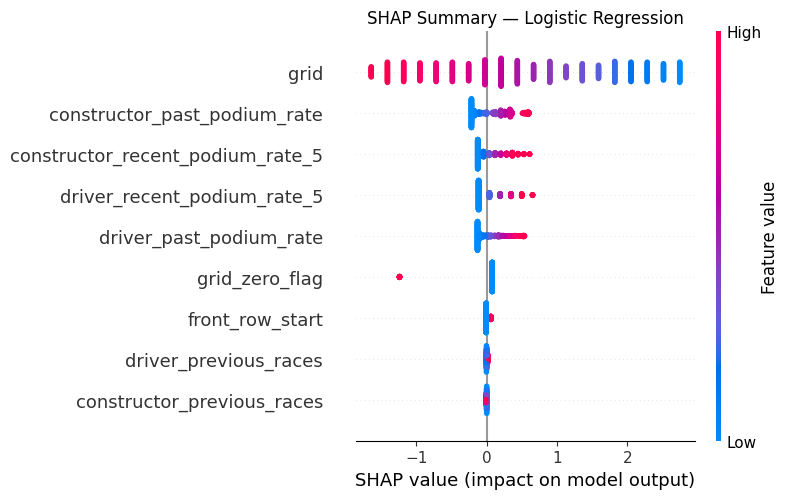

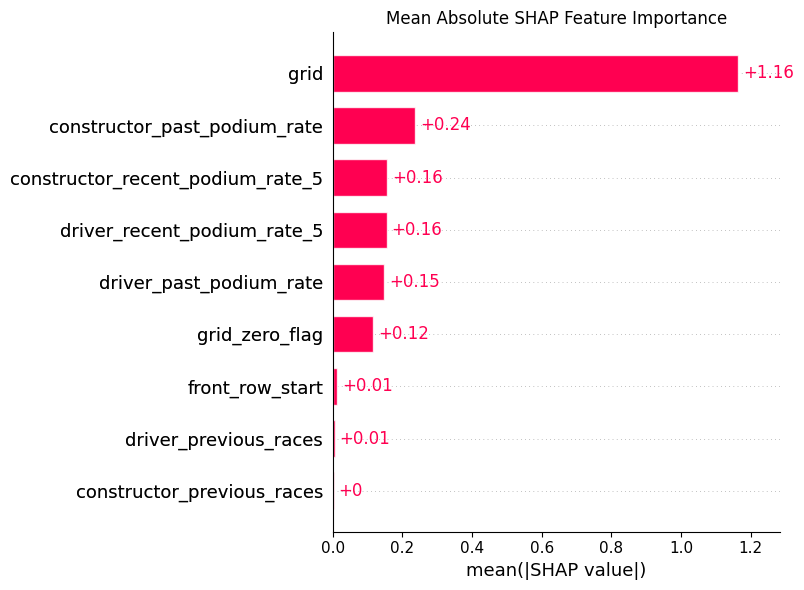

,Feature,Mean Absolute SHAP
0,grid,1.16463
5,constructor_past_podium_rate,0.23595
6,constructor_recent_podium_rate_5,0.15664
3,driver_recent_podium_rate_5,0.15511
2,driver_past_podium_rate,0.14704
8,grid_zero_flag,0.11612
7,front_row_start,0.01251
1,driver_previous_races,0.00550
4,constructor_previous_races,0.00312


In [471]:
import shap

# Extract the fitted preprocessing and Logistic Regression components.
lr_preprocessor = lr_best_model.named_steps["preprocessor"]
lr_logistic_model = lr_best_model.named_steps["model"]

# Transform the data using the already-fitted preprocessor.
lr_X_train_transformed = lr_preprocessor.transform(lr_X_train_xai)
lr_X_test_transformed = lr_preprocessor.transform(lr_X_test_xai)

lr_feature_names = lr_preprocessor.get_feature_names_out()

lr_X_train_transformed_df = pd.DataFrame(
    lr_X_train_transformed,
    columns=lr_feature_names
)

lr_X_test_transformed_df = pd.DataFrame(
    lr_X_test_transformed,
    columns=lr_feature_names
)

# Sample background data from training only.
lr_background = lr_X_train_transformed_df.sample(
    n=min(100, len(lr_X_train_transformed_df)),
    random_state=42
)

# Explain a representative test sample.
lr_X_test_shap = lr_X_test_transformed_df.sample(
    n=min(500, len(lr_X_test_transformed_df)),
    random_state=42
)

lr_explainer = shap.LinearExplainer(
    lr_logistic_model,
    lr_background
)

lr_shap_values = lr_explainer(lr_X_test_shap)

# Plot 1: Global SHAP summary.
shap.plots.beeswarm(
    lr_shap_values,
    max_display=9,
    show=False
)
plt.title("SHAP Summary — Logistic Regression")
plt.tight_layout()
plt.savefig("lr_shap_summary.png", dpi=300, bbox_inches="tight")
plt.show()

# Plot 2: Mean absolute SHAP importance.
shap.plots.bar(
    lr_shap_values,
    max_display=9,
    show=False
)
plt.title("Mean Absolute SHAP Feature Importance")
plt.tight_layout()
plt.savefig("lr_shap_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

# Numerical importance table.
lr_shap_importance = pd.DataFrame({
    "Feature": lr_feature_names,
    "Mean Absolute SHAP": np.abs(lr_shap_values.values).mean(axis=0)
}).sort_values("Mean Absolute SHAP", ascending=False)

display(lr_shap_importance.round(5))

Actual class: Podium
Predicted podium probability: 0.8771


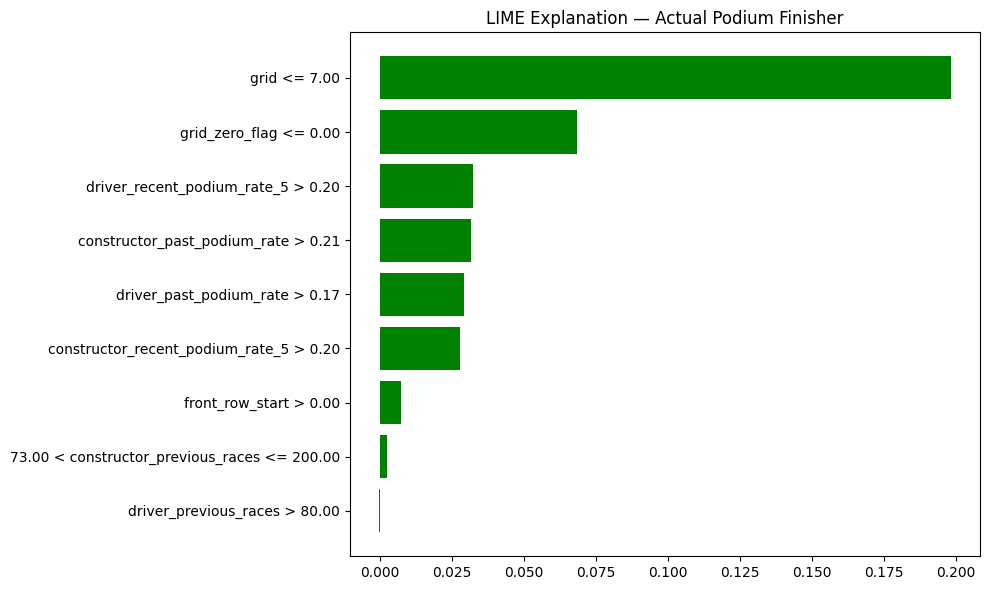

Actual class: No podium
Predicted podium probability: 0.0042


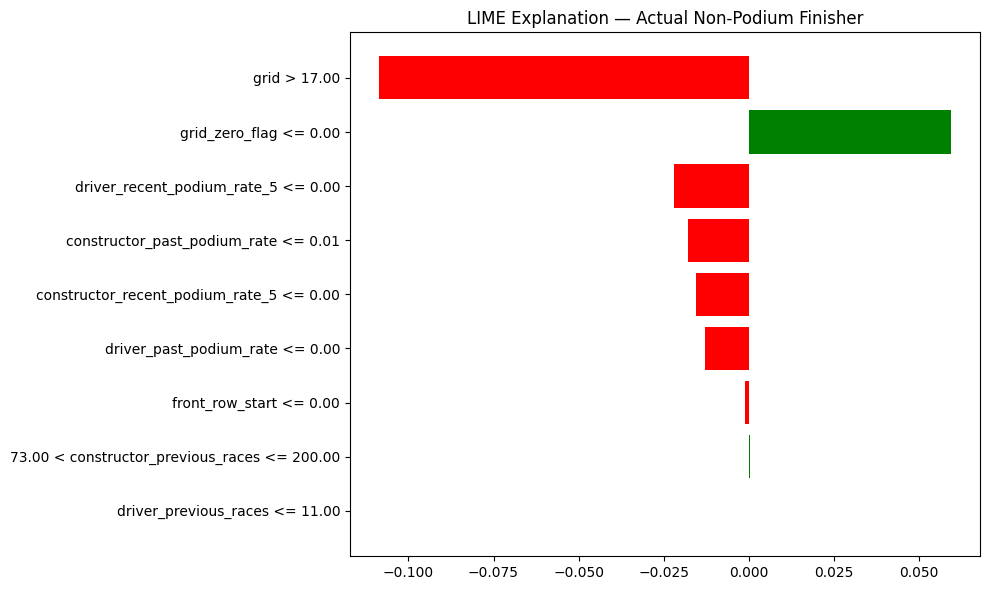

In [472]:
from lime.lime_tabular import LimeTabularExplainer

# Get predicted probabilities for the test set.
lr_test_probabilities = lr_best_model.predict_proba(lr_X_test_xai)[:, 1]
lr_y_test_array = np.asarray(y_test)

# Select one actual podium and one actual non-podium example.
lr_podium_indices = np.flatnonzero(lr_y_test_array == 1)
lr_non_podium_indices = np.flatnonzero(lr_y_test_array == 0)

if len(lr_podium_indices) == 0 or len(lr_non_podium_indices) == 0:
    raise ValueError("Both classes must be present in the test set.")

lr_podium_idx = lr_podium_indices[
    np.argmax(lr_test_probabilities[lr_podium_indices])
]

lr_non_podium_idx = lr_non_podium_indices[
    np.argmin(lr_test_probabilities[lr_non_podium_indices])
]

# Fill missing values using training-set medians for LIME's input data.
lr_training_medians = lr_X_train_xai.median()

lr_lime_train = lr_X_train_xai.fillna(lr_training_medians)
lr_lime_test = lr_X_test_xai.fillna(lr_training_medians)

# Prediction function: LIME passes perturbed rows to the original pipeline.
def lr_lime_predict_proba(data):
    lr_data_df = pd.DataFrame(data, columns=lr_all_features)
    return lr_final_model.predict_proba(lr_data_df)

lr_lime_explainer = LimeTabularExplainer(
    training_data=lr_lime_train.to_numpy(),
    feature_names=lr_all_features,
    class_names=["No podium", "Podium"],
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

# Explain the actual podium example.
lr_podium_explanation = lr_lime_explainer.explain_instance(
    data_row=lr_lime_test.iloc[lr_podium_idx].to_numpy(),
    predict_fn=lr_lime_predict_proba,
    labels=(1,),
    num_features=len(lr_all_features),
    num_samples=5000
)

print("Actual class: Podium")
print(f"Predicted podium probability: {lr_test_probabilities[lr_podium_idx]:.4f}")

lr_fig = lr_podium_explanation.as_pyplot_figure(label=1)
lr_fig.set_size_inches(10, 6)
plt.title("LIME Explanation — Actual Podium Finisher")
plt.tight_layout()
plt.savefig("lr_lime_podium_example.png", dpi=300, bbox_inches="tight")
plt.show()

# Explain the actual non-podium example.
lr_non_podium_explanation = lr_lime_explainer.explain_instance(
    data_row=lr_lime_test.iloc[lr_non_podium_idx].to_numpy(),
    predict_fn=lr_lime_predict_proba,
    labels=(1,),
    num_features=len(lr_all_features),
    num_samples=5000
)

print("Actual class: No podium")
print(
    f"Predicted podium probability: "
    f"{lr_test_probabilities[lr_non_podium_idx]:.4f}"
)

lr_fig = lr_non_podium_explanation.as_pyplot_figure(label=1)
lr_fig.set_size_inches(10, 6)
plt.title("LIME Explanation — Actual Non-Podium Finisher")
plt.tight_layout()
plt.savefig("lr_lime_non_podium_example.png", dpi=300, bbox_inches="tight")
plt.show()

Logistic Regression — Permutation Importance


,Feature,Mean AP decrease,Std
0,grid,0.3593,0.0189
7,constructor_past_podium_rate,0.0123,0.0081
5,driver_recent_podium_rate_5,0.0098,0.0063
8,constructor_recent_podium_rate_5,0.0084,0.0069
4,driver_past_podium_rate,0.0061,0.0065
1,front_row_start,0.0017,0.0006
2,grid_zero_flag,0.0011,0.0011
6,constructor_previous_races,0.0000,0.0002
3,driver_previous_races,-0.0000,0.0004


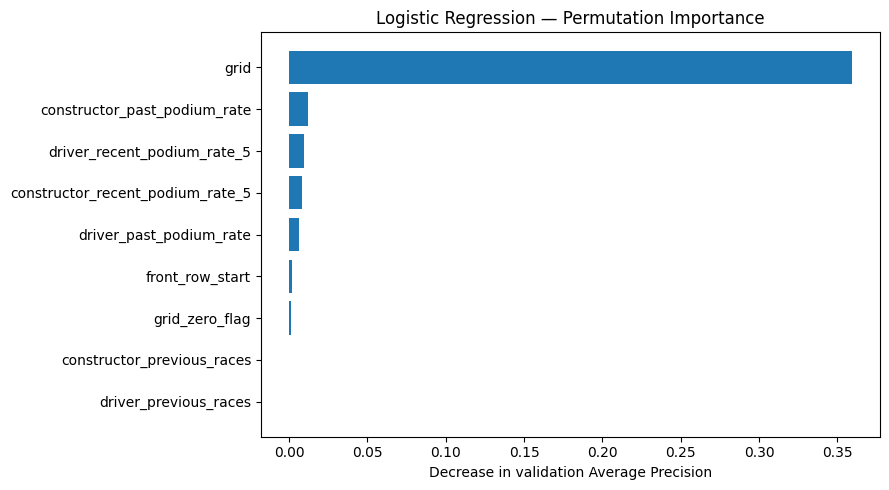

In [473]:

from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

# The finalized Logistic Regression pipeline
lr_final_model = lr_final_model

# Use the original, unscaled validation features.
# The pipeline handles imputation and scaling internally.
lr_feature_cols = list(X_train.columns)

lr_permutation = permutation_importance(
    estimator=lr_final_model,
    X=X_val[lr_feature_cols],
    y=y_val,
    scoring="average_precision",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

lr_permutation_results = pd.DataFrame({
    "Feature": lr_feature_cols,
    "Mean AP decrease": lr_permutation.importances_mean,
    "Std": lr_permutation.importances_std
}).sort_values("Mean AP decrease", ascending=False)

print("Logistic Regression — Permutation Importance")
display(lr_permutation_results.round(4))

plt.figure(figsize=(9, 5))
plt.barh(
    lr_permutation_results["Feature"][::-1],
    lr_permutation_results["Mean AP decrease"][::-1]
)
plt.xlabel("Decrease in validation Average Precision")
plt.title("Logistic Regression — Permutation Importance")
plt.tight_layout()
plt.show()


In [474]:

import pandas as pd
import numpy as np

lr_final_threshold = 0.34

def lr_predict_podium(record):
    # Convert input to a one-row DataFrame
    lr_input_df = pd.DataFrame([record]).reindex(
        columns=lr_feature_cols
    )

    # Pipeline performs its own training-fitted preprocessing
    lr_probability = float(
        lr_final_model.predict_proba(lr_input_df)[0, 1]
    )

    return {
        "podium_probability": round(lr_probability, 4),
        "predicted_podium": bool(
            lr_probability >= lr_final_threshold
        ),
        "threshold": lr_final_threshold,
        "missing_features_imputed": [
            col for col in lr_feature_cols
            if pd.isna(lr_input_df.iloc[0][col])
        ]
    }

# Example 1: Complete record
lr_complete_record = X_val.iloc[0][lr_feature_cols].to_dict()

print("COMPLETE RECORD")
print(lr_predict_podium(lr_complete_record))

# Verify consistency with direct model prediction
lr_direct_probability = float(
    lr_final_model.predict_proba(
        X_val.iloc[[0]][lr_feature_cols]
    )[0, 1]
)

print(
    "Direct model probability:",
    round(lr_direct_probability, 4)
)

# Example 2: Partially missing record
lr_partial_record = lr_complete_record.copy()

for feature in [
    "driver_past_podium_rate",
    "driver_recent_podium_rate_5",
    "constructor_recent_podium_rate_5"
]:
    lr_partial_record.pop(feature, None)

print("\nPARTIALLY MISSING RECORD")
print(lr_predict_podium(lr_partial_record))


COMPLETE RECORD
{'podium_probability': 0.1922, 'predicted_podium': False, 'threshold': 0.34, 'missing_features_imputed': []}
Direct model probability: 0.1922

PARTIALLY MISSING RECORD
{'podium_probability': 0.1059, 'predicted_podium': False, 'threshold': 0.34, 'missing_features_imputed': ['driver_past_podium_rate', 'driver_recent_podium_rate_5', 'constructor_recent_podium_rate_5']}


In [475]:

print("Final Logistic Regression pipeline:")
print(lr_final_model)

print("\nFeature count:", len(lr_feature_cols))
print("Selected C:", lr_final_model.named_steps["model"].C)
print("Selected threshold:", lr_final_threshold)


Final Logistic Regression pipeline:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['grid',
                                                   'driver_previous_races',
                                                   'driver_past_podium_rate',
                                                   'driver_recent_podium_rate_5',
                                                   'constructor_previous_races',
                                                   'constructor_past_podium_rate',
                                                   'constructor_re

In [477]:

import numpy as np

lr_expected_features = list(
    lr_final_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

print("Expected feature order:")
print(lr_expected_features)

print("\nSHAP feature order:")
print(list(lr_X_test_shap.columns))

print("\nFeature order matches:")
print(list(lr_X_test_shap.columns) == lr_expected_features)

print("\nSHAP explanation feature names:")
print(lr_shap_values.feature_names)


Expected feature order:
['grid', 'driver_previous_races', 'driver_past_podium_rate', 'driver_recent_podium_rate_5', 'constructor_previous_races', 'constructor_past_podium_rate', 'constructor_recent_podium_rate_5', 'front_row_start', 'grid_zero_flag']

SHAP feature order:
['grid', 'driver_previous_races', 'driver_past_podium_rate', 'driver_recent_podium_rate_5', 'constructor_previous_races', 'constructor_past_podium_rate', 'constructor_recent_podium_rate_5', 'front_row_start', 'grid_zero_flag']

Feature order matches:
True

SHAP explanation feature names:
['grid', 'driver_previous_races', 'driver_past_podium_rate', 'driver_recent_podium_rate_5', 'constructor_previous_races', 'constructor_past_podium_rate', 'constructor_recent_podium_rate_5', 'front_row_start', 'grid_zero_flag']
